# A-R1: linear action scorer

Team A | Rishitha Gogineni | 21 November 2026

This is the completed Colab CPU run. The heuristic played 300 fresh collection games and saved 3,346 decisions. After excluding 256 forced choices, 3,090 decisions were used for imitation. Whole games were split into 210 training games, 45 validation games and 45 test games. Earlier Day 3 test games were not reused.

A-R1 uses 375 visible state and legal option features. It learns the heuristic's preferences for MAIN decisions requiring one option. Other decisions use the frozen heuristic. No other member's files are required.

The selected model uses L2 equal to zero and the checkpoint from epoch 14. Test agreement with any highest scoring teacher action was 98.72 percent. Agreement with the exact teacher choice was 96.15 percent. These measure imitation, not game winning performance.

The Kaggle screenshot supplied after the manual upload shows all three submissions Complete: A-R1 at 828.8, heuristic at 257.6 and random at 11.5. These are rating snapshots. Saved JSON and CSV outputs retain the status from before the upload.


## 1. Settings

The default run collects 300 games, tries three regularization values, and plays 40 evaluation battles per comparison. The training split uses 70 percent of eligible games; validation and the final test each use 15 percent. The exact counts are saved.


In [1]:
import ast
import csv
import hashlib
import json
import os
import platform
import shutil
import subprocess
import sys
import tarfile
import traceback
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

assert platform.system() == 'Linux', 'Use a fresh Colab CPU session.'
N_DEMO_GAMES = 300
N_EVALUATION_GAMES = 40
N_ARCHIVE_GAMES_PER_OPPONENT = 2
MAX_EPOCHS = 60
MAX_RECORDS_PER_GAME = 500
PROCESS_TIMEOUT_SECONDS = 1200
assert N_DEMO_GAMES >= 150 and min(N_EVALUATION_GAMES, N_ARCHIVE_GAMES_PER_OPPONENT, MAX_EPOCHS) > 0
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
work_dir = Path('/content/ptcg_ar1') / RUN_ID
output_dir = work_dir / 'outputs'
source_dir = output_dir / 'source'
sdk_dir = work_dir / 'official_sample'
random_dir = work_dir / 'random_agent'
teacher_dir = work_dir / 'heuristic_agent'
candidate_dir = work_dir / 'ar1_agent'
for folder in (source_dir, sdk_dir, random_dir, teacher_dir, candidate_dir):
    folder.mkdir(parents=True, exist_ok=False)

def save_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(value, indent=2) + '\n', encoding='utf-8')
    temporary.replace(path)

def sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024*1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

run_info = {'model_id': 'A-R1', 'run_id': RUN_ID, 'python': sys.version,
            'platform': platform.platform(), 'numpy': np.__version__, 'matplotlib': matplotlib.__version__,
            'unit': 'individual_battle', 'native_engine_seed_verified': False,
            'requested_collection_games': N_DEMO_GAMES, 'evaluation_battles_per_comparison': N_EVALUATION_GAMES,
            'max_epochs': MAX_EPOCHS, 'collection_seed_start': 30000, 'evaluation_seed_start': 40000,
            'archive_seed_start': 50000, 'teacher_source_run': '20261121T232326Z_2121ee87',
            'feature_schema': 'ar1-visible-v1'}
save_json(output_dir / 'run_info.json', run_info)
print('Run:', RUN_ID)
print('Runtime:', sys.version.split()[0], platform.machine(), '| CPU')


Run: 20261122T002608Z_bd91a79d
Runtime: 3.13.18 x86_64 | CPU


## 2. Competition files

Upload the official ZIP used in the earlier notebooks. The recorded hash is checked before using its sample deck and simulator.


In [2]:
from google.colab import files

filename = 'the-pokemon-company-ptcg-ai-battle-challenge-playground.zip'
archive_path = Path('/content') / filename
if not archive_path.exists():
    uploaded = files.upload()
    choices = [name for name in uploaded if name.lower().endswith('.zip')]
    if len(choices) != 1:
        raise ValueError('Upload one official competition ZIP.')
    archive_path = Path('/content') / choices[0]
expected_hash = '6fe557e77ca21b86dea9056d7f4531cbeb328abc1b25aecf9c3a4e2b7d5b2c87'
assert sha256(archive_path) == expected_hash, 'Use the same official ZIP as Day 3. A different SDK version needs a separate compatibility review.'
prefix = 'sample_submission/sample_submission/sample_submission/'
with zipfile.ZipFile(archive_path) as archive:
    names = [name for name in archive.namelist() if name.startswith(prefix) and not name.endswith('/')]
    if not names:
        raise ValueError('Official sample package not found.')
    for name in names:
        relative = Path(name[len(prefix):])
        if relative.is_absolute() or '..' in relative.parts:
            raise ValueError('Unexpected archive path.')
        target = sdk_dir / relative
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(archive.read(name))
deck = [int(line) for line in (sdk_dir / 'deck.csv').read_text().splitlines() if line.strip()]
assert len(deck) == 60
for folder in (random_dir, teacher_dir, candidate_dir):
    shutil.copy2(sdk_dir / 'deck.csv', folder / 'deck.csv')
run_info['input_zip_sha256'] = sha256(archive_path)
run_info['deck_sha256'] = sha256(sdk_dir / 'deck.csv')
run_info['sdk_files'] = [{'path': str(path.relative_to(sdk_dir)), 'sha256': sha256(path)}
                         for path in sorted((sdk_dir / 'cg').rglob('*')) if path.is_file()]
save_json(output_dir / 'run_info.json', run_info)
print('Official files checked. Deck entries:', len(deck))


<IPython.core.display.HTML object>

Saving the-pokemon-company-ptcg-ai-battle-challenge-playground.zip to the-pokemon-company-ptcg-ai-battle-challenge-playground.zip
Official files checked. Deck entries: 60


## 3. Source files

Keep the accepted random and heuristic policies frozen. A-R1 scores each legal candidate with a shared linear model. Features include action type, visible card statistics, and interactions between action type and the visible state. Teacher scores, selected labels, outcomes and hidden card identities are excluded from the inputs.


In [3]:
SOURCES = {'ar1_features.py': 'ATTACK_DAMAGE = {1: 0, 2: 100, 3: 10, 4: 60, 5: 150, 6: 0, 7: 120, 8: 0, 9: 100, 10: 0, 11: 70, 12: 0, 13: 100, 14: 10, 15: 0, 16: 120, 17: 70, 18: 140, 19: 0, 20: 60, 21: 30, 22: 70, 23: 0, 24: 10, 25: 20, 26: 20, 27: 0, 28: 0, 29: 140, 30: 30, 31: 30, 32: 80, 33: 170, 34: 0, 35: 30, 36: 110, 37: 0, 38: 30, 39: 0, 40: 20, 41: 240, 42: 0, 43: 50, 44: 60, 45: 260, 46: 10, 47: 30, 48: 160, 49: 0, 50: 40, 51: 130, 52: 0, 53: 0, 54: 120, 55: 0, 56: 40, 57: 10, 58: 30, 59: 100, 60: 90, 61: 30, 62: 0, 63: 160, 64: 0, 65: 30, 66: 30, 67: 70, 68: 120, 69: 0, 70: 130, 71: 0, 72: 0, 73: 20, 74: 10, 75: 30, 76: 90, 77: 50, 78: 0, 79: 20, 80: 20, 81: 0, 82: 0, 83: 140, 84: 10, 85: 40, 86: 110, 87: 30, 88: 10, 89: 180, 90: 10, 91: 10, 92: 30, 93: 80, 94: 240, 95: 0, 96: 20, 97: 20, 98: 180, 99: 160, 100: 70, 101: 0, 102: 10, 103: 50, 104: 60, 105: 40, 106: 160, 107: 0, 108: 20, 109: 10, 110: 30, 111: 50, 112: 60, 113: 180, 114: 10, 115: 0, 116: 0, 117: 0, 118: 0, 119: 20, 120: 30, 121: 0, 122: 20, 123: 0, 124: 0, 125: 140, 126: 10, 127: 0, 128: 30, 129: 100, 130: 20, 131: 60, 132: 30, 133: 30, 134: 250, 135: 20, 136: 100, 137: 10, 138: 0, 139: 10, 140: 30, 141: 60, 142: 40, 143: 20, 144: 50, 145: 80, 146: 250, 147: 70, 148: 140, 149: 0, 150: 10, 151: 40, 152: 70, 153: 70, 154: 200, 155: 50, 156: 30, 157: 0, 158: 80, 159: 180, 160: 50, 161: 0, 162: 10, 163: 0, 164: 30, 165: 0, 166: 170, 167: 20, 168: 250, 169: 0, 170: 30, 171: 50, 172: 150, 173: 0, 174: 90, 175: 100, 176: 10, 177: 0, 178: 0, 179: 110, 180: 0, 181: 130, 182: 190, 183: 0, 184: 0, 185: 100, 186: 0, 187: 20, 188: 0, 189: 0, 190: 20, 191: 50, 192: 0, 193: 30, 194: 20, 195: 30, 196: 10, 197: 30, 198: 60, 199: 280, 200: 0, 201: 0, 202: 0, 203: 150, 204: 250, 205: 60, 206: 80, 207: 110, 208: 0, 209: 110, 210: 180, 211: 0, 212: 30, 213: 0, 214: 120, 215: 0, 216: 20, 217: 0, 218: 20, 219: 60, 220: 130, 221: 0, 222: 30, 223: 30, 224: 80, 225: 160, 226: 0, 227: 130, 228: 0, 229: 60, 230: 70, 231: 130, 232: 0, 233: 180, 234: 0, 235: 20, 236: 80, 237: 90, 238: 250, 239: 50, 240: 40, 241: 120, 242: 0, 243: 200, 244: 10, 245: 0, 246: 50, 247: 0, 248: 20, 249: 0, 250: 50, 251: 130, 252: 0, 253: 220, 254: 30, 255: 100, 256: 40, 257: 100, 258: 150, 259: 0, 260: 0, 261: 100, 262: 0, 263: 160, 264: 0, 265: 100, 266: 10, 267: 120, 268: 0, 269: 0, 270: 30, 271: 20, 272: 130, 273: 30, 274: 60, 275: 10, 276: 70, 277: 10, 278: 0, 279: 160, 280: 30, 281: 120, 282: 300, 283: 40, 284: 0, 285: 0, 286: 0, 287: 90, 288: 140, 289: 0, 290: 0, 291: 160, 292: 10, 293: 10, 294: 20, 295: 0, 296: 100, 297: 0, 298: 20, 299: 80, 300: 0, 301: 30, 302: 160, 303: 0, 304: 130, 305: 0, 306: 80, 307: 30, 308: 110, 309: 0, 310: 20, 311: 0, 312: 60, 313: 200, 314: 130, 315: 10, 316: 100, 317: 0, 318: 280, 319: 40, 320: 150, 321: 0, 322: 100, 323: 10, 324: 0, 325: 230, 326: 0, 327: 40, 328: 130, 329: 280, 330: 60, 331: 0, 332: 280, 333: 0, 334: 110, 335: 0, 336: 60, 337: 280, 338: 0, 339: 10, 340: 160, 341: 0, 342: 0, 343: 160, 344: 0, 345: 200, 346: 20, 347: 100, 348: 20, 349: 0, 350: 0, 351: 20, 352: 90, 353: 20, 354: 50, 355: 0, 356: 90, 357: 160, 358: 20, 359: 70, 360: 130, 361: 60, 362: 10, 363: 20, 364: 0, 365: 100, 366: 30, 367: 30, 368: 230, 369: 10, 370: 70, 371: 20, 372: 0, 373: 70, 374: 10, 375: 30, 376: 30, 377: 50, 378: 60, 379: 130, 380: 20, 381: 0, 382: 0, 383: 50, 384: 0, 385: 30, 386: 0, 387: 10, 388: 20, 389: 50, 390: 180, 391: 20, 392: 60, 393: 0, 394: 20, 395: 40, 396: 0, 397: 20, 398: 30, 399: 140, 400: 150, 401: 30, 402: 20, 403: 0, 404: 0, 405: 20, 406: 40, 407: 50, 408: 0, 409: 20, 410: 50, 411: 150, 412: 30, 413: 240, 414: 10, 415: 50, 416: 30, 417: 80, 418: 0, 419: 300, 420: 0, 421: 170, 422: 140, 423: 0, 424: 20, 425: 0, 426: 150, 427: 0, 428: 20, 429: 30, 430: 80, 431: 50, 432: 80, 433: 120, 434: 20, 435: 60, 436: 60, 437: 220, 438: 10, 439: 230, 440: 160, 441: 0, 442: 30, 443: 50, 444: 100, 445: 20, 446: 30, 447: 280, 448: 30, 449: 60, 450: 20, 451: 30, 452: 50, 453: 200, 454: 10, 455: 30, 456: 30, 457: 220, 458: 60, 459: 100, 460: 50, 461: 120, 462: 60, 463: 130, 464: 10, 465: 20, 466: 20, 467: 20, 468: 210, 469: 140, 470: 20, 471: 70, 472: 0, 473: 30, 474: 210, 475: 20, 476: 80, 477: 30, 478: 0, 479: 120, 480: 10, 481: 50, 482: 0, 483: 140, 484: 0, 485: 120, 486: 0, 487: 60, 488: 30, 489: 40, 490: 40, 491: 160, 492: 20, 493: 0, 494: 160, 495: 0, 496: 80, 497: 30, 498: 20, 499: 60, 500: 10, 501: 0, 502: 120, 503: 0, 504: 60, 505: 10, 506: 60, 507: 10, 508: 30, 509: 30, 510: 140, 511: 30, 512: 120, 513: 0, 514: 100, 515: 50, 516: 0, 517: 180, 518: 30, 519: 10, 520: 30, 521: 30, 522: 120, 523: 20, 524: 0, 525: 20, 526: 0, 527: 20, 528: 0, 529: 20, 530: 40, 531: 100, 532: 260, 533: 0, 534: 130, 535: 30, 536: 0, 537: 120, 538: 0, 539: 100, 540: 0, 541: 10, 542: 50, 543: 30, 544: 210, 545: 30, 546: 50, 547: 10, 548: 50, 549: 10, 550: 30, 551: 30, 552: 90, 553: 20, 554: 0, 555: 20, 556: 30, 557: 130, 558: 0, 559: 30, 560: 0, 561: 10, 562: 0, 563: 40, 564: 0, 565: 160, 566: 10, 567: 20, 568: 50, 569: 100, 570: 110, 571: 0, 572: 20, 573: 0, 574: 120, 575: 0, 576: 10, 577: 20, 578: 0, 579: 70, 580: 120, 581: 0, 582: 0, 583: 60, 584: 10, 585: 80, 586: 0, 587: 20, 588: 50, 589: 90, 590: 120, 591: 20, 592: 0, 593: 30, 594: 40, 595: 60, 596: 30, 597: 80, 598: 140, 599: 30, 600: 60, 601: 0, 602: 10, 603: 50, 604: 140, 605: 10, 606: 40, 607: 0, 608: 160, 609: 0, 610: 70, 611: 0, 612: 0, 613: 0, 614: 30, 615: 40, 616: 30, 617: 0, 618: 160, 619: 10, 620: 30, 621: 180, 622: 20, 623: 40, 624: 40, 625: 70, 626: 10, 627: 50, 628: 0, 629: 140, 630: 0, 631: 10, 632: 0, 633: 30, 634: 0, 635: 50, 636: 60, 637: 130, 638: 10, 639: 30, 640: 30, 641: 60, 642: 100, 643: 240, 644: 0, 645: 30, 646: 120, 647: 0, 648: 40, 649: 0, 650: 30, 651: 0, 652: 0, 653: 30, 654: 20, 655: 0, 656: 20, 657: 0, 658: 0, 659: 60, 660: 70, 661: 10, 662: 90, 663: 0, 664: 0, 665: 0, 666: 140, 667: 50, 668: 0, 669: 0, 670: 0, 671: 0, 672: 20, 673: 0, 674: 70, 675: 20, 676: 10, 677: 30, 678: 20, 679: 60, 680: 150, 681: 0, 682: 30, 683: 70, 684: 0, 685: 10, 686: 30, 687: 70, 688: 20, 689: 50, 690: 10, 691: 0, 692: 30, 693: 60, 694: 120, 695: 30, 696: 50, 697: 180, 698: 0, 699: 50, 700: 50, 701: 180, 702: 10, 703: 70, 704: 0, 705: 30, 706: 70, 707: 0, 708: 0, 709: 60, 710: 0, 711: 160, 712: 0, 713: 80, 714: 150, 715: 70, 716: 10, 717: 0, 718: 150, 719: 0, 720: 30, 721: 50, 722: 130, 723: 0, 724: 20, 725: 0, 726: 50, 727: 60, 728: 0, 729: 0, 730: 110, 731: 50, 732: 130, 733: 0, 734: 10, 735: 0, 736: 50, 737: 10, 738: 0, 739: 30, 740: 0, 741: 40, 742: 0, 743: 40, 744: 0, 745: 80, 746: 60, 747: 0, 748: 200, 749: 30, 750: 10, 751: 30, 752: 60, 753: 200, 754: 10, 755: 50, 756: 30, 757: 60, 758: 100, 759: 120, 760: 0, 761: 20, 762: 80, 763: 0, 764: 110, 765: 0, 766: 30, 767: 90, 768: 10, 769: 40, 770: 60, 771: 120, 772: 10, 773: 90, 774: 90, 775: 10, 776: 40, 777: 60, 778: 20, 779: 80, 780: 150, 781: 0, 782: 30, 783: 90, 784: 80, 785: 0, 786: 0, 787: 10, 788: 40, 789: 0, 790: 120, 791: 30, 792: 0, 793: 20, 794: 20, 795: 40, 796: 0, 797: 90, 798: 10, 799: 0, 800: 0, 801: 30, 802: 50, 803: 100, 804: 10, 805: 50, 806: 30, 807: 130, 808: 10, 809: 30, 810: 30, 811: 80, 812: 120, 813: 0, 814: 30, 815: 70, 816: 0, 817: 60, 818: 50, 819: 130, 820: 10, 821: 30, 822: 0, 823: 30, 824: 10, 825: 50, 826: 0, 827: 20, 828: 30, 829: 120, 830: 10, 831: 20, 832: 30, 833: 50, 834: 60, 835: 0, 836: 30, 837: 120, 838: 10, 839: 30, 840: 30, 841: 100, 842: 30, 843: 0, 844: 20, 845: 50, 846: 10, 847: 0, 848: 50, 849: 0, 850: 0, 851: 20, 852: 0, 853: 60, 854: 20, 855: 0, 856: 40, 857: 90, 858: 20, 859: 80, 860: 0, 861: 30, 862: 30, 863: 90, 864: 0, 865: 160, 866: 30, 867: 90, 868: 30, 869: 100, 870: 20, 871: 40, 872: 80, 873: 50, 874: 100, 875: 0, 876: 50, 877: 10, 878: 30, 879: 0, 880: 10, 881: 20, 882: 40, 883: 120, 884: 30, 885: 0, 886: 0, 887: 20, 888: 50, 889: 0, 890: 100, 891: 200, 892: 10, 893: 40, 894: 0, 895: 130, 896: 10, 897: 50, 898: 120, 899: 20, 900: 50, 901: 40, 902: 90, 903: 0, 904: 10, 905: 0, 906: 80, 907: 10, 908: 0, 909: 70, 910: 0, 911: 100, 912: 100, 913: 10, 914: 20, 915: 40, 916: 130, 917: 0, 918: 100, 919: 0, 920: 20, 921: 20, 922: 220, 923: 80, 924: 30, 925: 0, 926: 30, 927: 70, 928: 200, 929: 20, 930: 70, 931: 50, 932: 40, 933: 160, 934: 0, 935: 10, 936: 60, 937: 180, 938: 20, 939: 10, 940: 60, 941: 240, 942: 0, 943: 30, 944: 60, 945: 0, 946: 30, 947: 0, 948: 20, 949: 30, 950: 50, 951: 0, 952: 100, 953: 10, 954: 20, 955: 0, 956: 60, 957: 0, 958: 30, 959: 80, 960: 280, 961: 0, 962: 130, 963: 30, 964: 0, 965: 50, 966: 10, 967: 30, 968: 10, 969: 10, 970: 20, 971: 50, 972: 100, 973: 30, 974: 100, 975: 10, 976: 10, 977: 30, 978: 210, 979: 50, 980: 70, 981: 30, 982: 130, 983: 270, 984: 20, 985: 70, 986: 60, 987: 20, 988: 140, 989: 10, 990: 50, 991: 130, 992: 30, 993: 130, 994: 0, 995: 200, 996: 10, 997: 20, 998: 110, 999: 20, 1000: 20, 1001: 60, 1002: 20, 1003: 90, 1004: 40, 1005: 140, 1006: 0, 1007: 260, 1008: 30, 1009: 80, 1010: 20, 1011: 30, 1012: 240, 1013: 0, 1014: 100, 1015: 10, 1016: 0, 1017: 0, 1018: 60, 1019: 0, 1020: 20, 1021: 50, 1022: 0, 1023: 30, 1024: 30, 1025: 120, 1026: 20, 1027: 50, 1028: 140, 1029: 30, 1030: 20, 1031: 90, 1032: 30, 1033: 30, 1034: 70, 1035: 10, 1036: 50, 1037: 50, 1038: 140, 1039: 40, 1040: 0, 1041: 50, 1042: 0, 1043: 130, 1044: 10, 1045: 30, 1046: 0, 1047: 200, 1048: 50, 1049: 210, 1050: 30, 1051: 0, 1052: 0, 1053: 110, 1054: 0, 1055: 0, 1056: 20, 1057: 90, 1058: 10, 1059: 30, 1060: 50, 1061: 160, 1062: 30, 1063: 30, 1064: 120, 1065: 200, 1066: 10, 1067: 0, 1068: 20, 1069: 70, 1070: 10, 1071: 30, 1072: 0, 1073: 30, 1074: 0, 1075: 10, 1076: 0, 1077: 30, 1078: 0, 1079: 0, 1080: 0, 1081: 0, 1082: 60, 1083: 0, 1084: 120, 1085: 10, 1086: 40, 1087: 30, 1088: 130, 1089: 40, 1090: 300, 1091: 130, 1092: 200, 1093: 0, 1094: 30, 1095: 0, 1096: 10, 1097: 0, 1098: 60, 1099: 10, 1100: 20, 1101: 50, 1102: 100, 1103: 20, 1104: 50, 1105: 90, 1106: 0, 1107: 90, 1108: 0, 1109: 50, 1110: 0, 1111: 0, 1112: 20, 1113: 10, 1114: 0, 1115: 10, 1116: 40, 1117: 230, 1118: 10, 1119: 30, 1120: 0, 1121: 20, 1122: 0, 1123: 60, 1124: 50, 1125: 130, 1126: 20, 1127: 20, 1128: 30, 1129: 60, 1130: 100, 1131: 170, 1132: 30, 1133: 30, 1134: 120, 1135: 0, 1136: 110, 1137: 0, 1138: 30, 1139: 150, 1140: 20, 1141: 40, 1142: 0, 1143: 20, 1144: 10, 1145: 40, 1146: 30, 1147: 240, 1148: 110, 1149: 0, 1150: 10, 1151: 220, 1152: 20, 1153: 0, 1154: 10, 1155: 20, 1156: 30, 1157: 70, 1158: 120, 1159: 200, 1160: 30, 1161: 0, 1162: 20, 1163: 20, 1164: 0, 1165: 130, 1166: 20, 1167: 70, 1168: 0, 1169: 10, 1170: 60, 1171: 130, 1172: 20, 1173: 150, 1174: 0, 1175: 0, 1176: 50, 1177: 50, 1178: 0, 1179: 80, 1180: 0, 1181: 70, 1182: 10, 1183: 50, 1184: 0, 1185: 60, 1186: 130, 1187: 10, 1188: 30, 1189: 20, 1190: 60, 1191: 30, 1192: 70, 1193: 120, 1194: 120, 1195: 10, 1196: 20, 1197: 30, 1198: 60, 1199: 60, 1200: 160, 1201: 0, 1202: 20, 1203: 100, 1204: 210, 1205: 0, 1206: 30, 1207: 0, 1208: 0, 1209: 0, 1210: 30, 1211: 70, 1212: 120, 1213: 0, 1214: 0, 1215: 100, 1216: 20, 1217: 50, 1218: 0, 1219: 0, 1220: 40, 1221: 30, 1222: 70, 1223: 0, 1224: 20, 1225: 60, 1226: 160, 1227: 20, 1228: 30, 1229: 40, 1230: 0, 1231: 0, 1232: 100, 1233: 30, 1234: 20, 1235: 110, 1236: 170, 1237: 20, 1238: 60, 1239: 10, 1240: 0, 1241: 150, 1242: 0, 1243: 20, 1244: 20, 1245: 60, 1246: 0, 1247: 120, 1248: 20, 1249: 90, 1250: 20, 1251: 130, 1252: 0, 1253: 190, 1254: 30, 1255: 30, 1256: 0, 1257: 0, 1258: 130, 1259: 10, 1260: 0, 1261: 150, 1262: 0, 1263: 60, 1264: 0, 1265: 0, 1266: 10, 1267: 30, 1268: 90, 1269: 30, 1270: 0, 1271: 0, 1272: 50, 1273: 0, 1274: 10, 1275: 150, 1276: 20, 1277: 120, 1278: 20, 1279: 20, 1280: 60, 1281: 0, 1282: 220, 1283: 20, 1284: 80, 1285: 0, 1286: 100, 1287: 10, 1288: 20, 1289: 50, 1290: 0, 1291: 160, 1292: 20, 1293: 160, 1294: 40, 1295: 80, 1296: 20, 1297: 10, 1298: 50, 1299: 180, 1300: 30, 1301: 60, 1302: 330, 1303: 20, 1304: 130, 1305: 70, 1306: 250, 1307: 0, 1308: 30, 1309: 40, 1310: 70, 1311: 30, 1312: 50, 1313: 160, 1314: 20, 1315: 30, 1316: 70, 1317: 0, 1318: 130, 1319: 50, 1320: 10, 1321: 60, 1322: 0, 1323: 30, 1324: 60, 1325: 70, 1326: 220, 1327: 20, 1328: 0, 1329: 30, 1330: 90, 1331: 20, 1332: 30, 1333: 50, 1334: 0, 1335: 30, 1336: 20, 1337: 70, 1338: 320, 1339: 10, 1340: 20, 1341: 130, 1342: 80, 1343: 20, 1344: 30, 1345: 40, 1346: 50, 1347: 200, 1348: 0, 1349: 140, 1350: 10, 1351: 30, 1352: 60, 1353: 60, 1354: 170, 1355: 0, 1356: 140, 1357: 20, 1358: 20, 1359: 0, 1360: 10, 1361: 10, 1362: 30, 1363: 20, 1364: 150, 1365: 20, 1366: 100, 1367: 20, 1368: 80, 1369: 0, 1370: 190, 1371: 120, 1372: 250, 1373: 0, 1374: 10, 1375: 20, 1376: 40, 1377: 120, 1378: 0, 1379: 100, 1380: 30, 1381: 30, 1382: 0, 1383: 20, 1384: 60, 1385: 20, 1386: 0, 1387: 20, 1388: 40, 1389: 70, 1390: 0, 1391: 10, 1392: 130, 1393: 0, 1394: 120, 1395: 0, 1396: 170, 1397: 0, 1398: 50, 1399: 80, 1400: 150, 1401: 30, 1402: 30, 1403: 100, 1404: 70, 1405: 20, 1406: 50, 1407: 0, 1408: 50, 1409: 200, 1410: 0, 1411: 40, 1412: 0, 1413: 60, 1414: 0, 1415: 160, 1416: 20, 1417: 0, 1418: 160, 1419: 0, 1420: 130, 1421: 0, 1422: 50, 1423: 0, 1424: 90, 1425: 0, 1426: 140, 1427: 20, 1428: 20, 1429: 80, 1430: 120, 1431: 230, 1432: 50, 1433: 130, 1434: 150, 1435: 80, 1436: 0, 1437: 230, 1438: 10, 1439: 0, 1440: 0, 1441: 50, 1442: 20, 1443: 40, 1444: 0, 1445: 20, 1446: 180, 1447: 0, 1448: 10, 1449: 20, 1450: 50, 1451: 60, 1452: 150, 1453: 0, 1454: 20, 1455: 20, 1456: 50, 1457: 120, 1458: 0, 1459: 50, 1460: 120, 1461: 10, 1462: 50, 1463: 0, 1464: 30, 1465: 30, 1466: 40, 1467: 0, 1468: 100, 1469: 20, 1470: 0, 1471: 60, 1472: 0, 1473: 30, 1474: 20, 1475: 0, 1476: 240, 1477: 60, 1478: 110, 1479: 20, 1480: 0, 1481: 100, 1482: 80, 1483: 10, 1484: 30, 1485: 60, 1486: 20, 1487: 120, 1488: 210, 1489: 50, 1490: 150, 1491: 50, 1492: 0, 1493: 0, 1494: 40, 1495: 0, 1496: 200, 1497: 0, 1498: 30, 1499: 0, 1500: 30, 1501: 120, 1502: 0, 1503: 0, 1504: 10, 1505: 0, 1506: 30, 1507: 0, 1508: 10, 1509: 50, 1510: 40, 1511: 60, 1512: 260, 1513: 10, 1514: 60, 1515: 80, 1516: 130, 1517: 50, 1518: 120, 1519: 0, 1520: 30, 1521: 80, 1522: 0, 1523: 160, 1524: 30, 1525: 200, 1526: 0, 1527: 30, 1528: 0, 1529: 10, 1530: 20, 1531: 60, 1532: 100, 1533: 0, 1534: 210, 1535: 20, 1536: 80, 1537: 0, 1538: 10, 1539: 0, 1540: 80, 1541: 230, 1542: 30, 1543: 30, 1544: 20, 1545: 0, 1546: 60, 1547: 0, 1548: 160, 1549: 10, 1550: 140, 1551: 100, 1552: 0, 1553: 20, 1554: 0, 1555: 30, 1556: 350, 1557: 30, 1558: 20, 1559: 0, 1560: 80, 1561: 10, 1562: 30, 1563: 20, 1564: 80, 1565: 160, 1566: 0, 1567: 0, 1568: 70, 1569: 0, 1570: 130, 1571: 0, 1572: 10, 1573: 80, 1574: 0, 1575: 10, 1576: 80, 1577: 290, 1578: 20, 1579: 30, 1580: 120, 1581: 0, 1582: 40, 1583: 20, 1584: 70, 1585: 0, 1586: 10, 1587: 0, 1588: 50, 1589: 120, 1590: 10, 1591: 50, 1592: 0, 1593: 160, 1594: 10, 1595: 20, 1596: 30, 1597: 150, 1598: 20, 1599: 40, 1600: 140, 1601: 0, 1602: 30, 1603: 0, 1604: 80, 1605: 120, 1606: 80, 1607: 30, 1608: 0, 1609: 200, 1610: 10, 1611: 80, 1612: 10, 1613: 30, 1614: 60, 1615: 20, 1616: 30, 1617: 140, 1618: 0, 1619: 0, 1620: 30, 1621: 10, 1622: 40, 1623: 20, 1624: 180, 1625: 0, 1626: 50, 1627: 0, 1628: 30, 1629: 80, 1630: 30, 1631: 20, 1632: 40, 1633: 100, 1634: 10, 1635: 100, 1636: 10, 1637: 10, 1638: 20, 1639: 30, 1640: 70, 1641: 60, 1642: 150, 1643: 40, 1644: 70, 1645: 200, 1646: 0, 1647: 0, 1648: 30, 1649: 70, 1650: 160, 1651: 0, 1652: 10, 1653: 0, 1654: 50, 1655: 30, 1656: 0, 1657: 0, 1658: 60, 1659: 10, 1660: 30, 1661: 60, 1662: 140, 1663: 0, 1664: 0, 1665: 0, 1666: 120, 1667: 0, 1668: 0, 1669: 0, 1670: 160, 1671: 40, 1672: 40, 1673: 30, 1674: 0, 1675: 40, 1676: 80, 1677: 120, 1678: 270, 1679: 10, 1680: 20, 1681: 40, 1682: 120, 1683: 20, 1684: 80, 1685: 0, 1686: 30, 1687: 50, 1688: 110, 1689: 30, 1690: 50, 1691: 0, 1692: 260, 1693: 0, 1694: 150, 1695: 90, 1696: 0, 1697: 20, 1698: 50, 1699: 110, 1700: 0, 1701: 50, 1702: 10, 1703: 80, 1704: 0, 1705: 20, 1706: 0, 1707: 130, 1708: 30, 1709: 0, 1710: 100, 1711: 20, 1712: 50, 1713: 70, 1714: 150, 1715: 0, 1716: 50, 1717: 30, 1718: 190, 1719: 110, 1720: 0, 1721: 10, 1722: 20, 1723: 0, 1724: 120, 1725: 0, 1726: 30, 1727: 0, 1728: 130, 1729: 10, 1730: 30, 1731: 0, 1732: 80, 1733: 0, 1734: 40, 1735: 30, 1736: 100, 1737: 40, 1738: 60, 1739: 210, 1740: 20, 1741: 0, 1742: 50, 1743: 160, 1744: 10, 1745: 40, 1746: 120, 1747: 90, 1748: 200, 1749: 0, 1750: 30, 1751: 60, 1752: 40, 1753: 130, 1754: 0, 1755: 100}\nCARD_HP = {1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10: 0, 11: 0, 12: 0, 13: 0, 14: 0, 15: 0, 16: 0, 17: 0, 18: 0, 19: 0, 20: 0, 21: 120, 22: 90, 23: 160, 24: 230, 25: 110, 26: 120, 27: 120, 28: 30, 29: 240, 30: 270, 31: 110, 32: 120, 33: 60, 34: 90, 35: 130, 36: 70, 37: 230, 38: 100, 39: 120, 40: 310, 41: 140, 42: 40, 43: 50, 44: 260, 45: 70, 46: 230, 47: 70, 48: 90, 49: 180, 50: 60, 51: 150, 52: 250, 53: 70, 54: 80, 55: 110, 56: 90, 57: 100, 58: 140, 59: 60, 60: 90, 61: 140, 62: 140, 63: 240, 64: 70, 65: 60, 66: 140, 67: 70, 68: 60, 69: 90, 70: 150, 71: 70, 72: 130, 73: 50, 74: 70, 75: 220, 76: 80, 77: 70, 78: 100, 79: 320, 80: 220, 81: 70, 82: 130, 83: 260, 84: 270, 85: 70, 86: 100, 87: 110, 88: 70, 89: 70, 90: 100, 91: 180, 92: 40, 93: 80, 94: 70, 95: 110, 96: 210, 97: 60, 98: 130, 99: 210, 100: 50, 101: 90, 102: 120, 103: 60, 104: 90, 105: 70, 106: 100, 107: 340, 108: 210, 109: 40, 110: 120, 111: 90, 112: 110, 113: 80, 114: 100, 115: 180, 116: 130, 117: 210, 118: 140, 119: 70, 120: 90, 121: 320, 122: 70, 123: 70, 124: 120, 125: 300, 126: 100, 127: 70, 128: 90, 129: 150, 130: 280, 131: 60, 132: 90, 133: 160, 134: 120, 135: 150, 136: 70, 137: 120, 138: 250, 139: 210, 140: 210, 141: 190, 142: 110, 143: 70, 144: 130, 145: 70, 146: 100, 147: 150, 148: 90, 149: 40, 150: 330, 151: 70, 152: 90, 153: 320, 154: 220, 155: 160, 156: 160, 157: 80, 158: 140, 159: 130, 160: 30, 161: 260, 162: 80, 163: 120, 164: 70, 165: 60, 166: 90, 167: 140, 168: 70, 169: 130, 170: 180, 171: 130, 172: 70, 173: 100, 174: 70, 175: 100, 176: 230, 177: 30, 178: 120, 179: 230, 180: 110, 181: 100, 182: 170, 183: 30, 184: 210, 185: 40, 186: 70, 187: 60, 188: 90, 189: 310, 190: 300, 191: 130, 192: 130, 193: 300, 194: 120, 195: 130, 196: 120, 197: 50, 198: 190, 199: 40, 200: 80, 201: 130, 202: 70, 203: 180, 204: 80, 205: 260, 206: 30, 207: 270, 208: 70, 209: 120, 210: 200, 211: 100, 212: 80, 213: 120, 214: 140, 215: 70, 216: 70, 217: 70, 218: 70, 219: 120, 220: 60, 221: 90, 222: 70, 223: 280, 224: 140, 225: 130, 226: 130, 227: 70, 228: 100, 229: 330, 230: 80, 231: 160, 232: 340, 233: 130, 234: 120, 235: 30, 236: 270, 237: 60, 238: 100, 239: 270, 240: 110, 241: 280, 242: 30, 243: 270, 244: 260, 245: 140, 246: 270, 247: 50, 248: 280, 249: 200, 250: 80, 251: 160, 252: 50, 253: 90, 254: 120, 255: 110, 256: 130, 257: 80, 258: 140, 259: 220, 260: 60, 261: 90, 262: 140, 263: 130, 264: 240, 265: 70, 266: 100, 267: 40, 268: 60, 269: 280, 270: 60, 271: 120, 272: 190, 273: 90, 274: 60, 275: 100, 276: 170, 277: 110, 278: 30, 279: 70, 280: 70, 281: 70, 282: 100, 283: 340, 284: 70, 285: 90, 286: 70, 287: 120, 288: 80, 289: 140, 290: 190, 291: 70, 292: 70, 293: 280, 294: 60, 295: 90, 296: 160, 297: 90, 298: 170, 299: 230, 300: 70, 301: 100, 302: 320, 303: 130, 304: 150, 305: 70, 306: 270, 307: 60, 308: 90, 309: 70, 310: 120, 311: 110, 312: 120, 313: 220, 314: 70, 315: 120, 316: 270, 317: 50, 318: 130, 319: 70, 320: 270, 321: 50, 322: 110, 323: 50, 324: 60, 325: 90, 326: 320, 327: 70, 328: 190, 329: 200, 330: 120, 331: 210, 332: 130, 333: 70, 334: 60, 335: 70, 336: 220, 337: 220, 338: 120, 339: 70, 340: 280, 341: 70, 342: 130, 343: 80, 344: 70, 345: 150, 346: 40, 347: 90, 348: 170, 349: 110, 350: 70, 351: 110, 352: 70, 353: 100, 354: 170, 355: 80, 356: 130, 357: 230, 358: 110, 359: 70, 360: 70, 361: 100, 362: 30, 363: 180, 364: 110, 365: 30, 366: 130, 367: 70, 368: 120, 369: 260, 370: 110, 371: 90, 372: 280, 373: 30, 374: 60, 375: 120, 376: 60, 377: 100, 378: 110, 379: 70, 380: 100, 381: 330, 382: 90, 383: 150, 384: 70, 385: 140, 386: 110, 387: 70, 388: 70, 389: 270, 390: 130, 391: 60, 392: 120, 393: 70, 394: 60, 395: 120, 396: 70, 397: 60, 398: 120, 399: 60, 400: 50, 401: 130, 402: 60, 403: 90, 404: 310, 405: 80, 406: 140, 407: 220, 408: 70, 409: 130, 410: 70, 411: 100, 412: 170, 413: 80, 414: 120, 415: 60, 416: 110, 417: 90, 418: 90, 419: 150, 420: 80, 421: 70, 422: 130, 423: 100, 424: 300, 425: 120, 426: 60, 427: 90, 428: 140, 429: 80, 430: 130, 431: 280, 432: 110, 433: 30, 434: 60, 435: 80, 436: 130, 437: 70, 438: 110, 439: 150, 440: 70, 441: 100, 442: 180, 443: 80, 444: 140, 445: 70, 446: 120, 447: 230, 448: 70, 449: 130, 450: 70, 451: 90, 452: 170, 453: 70, 454: 100, 455: 330, 456: 50, 457: 80, 458: 310, 459: 80, 460: 150, 461: 70, 462: 130, 463: 80, 464: 80, 465: 130, 466: 110, 467: 130, 468: 50, 469: 90, 470: 70, 471: 260, 472: 120, 473: 60, 474: 90, 475: 140, 476: 60, 477: 100, 478: 70, 479: 70, 480: 100, 481: 320, 482: 70, 483: 100, 484: 60, 485: 100, 486: 100, 487: 60, 488: 50, 489: 120, 490: 80, 491: 80, 492: 140, 493: 60, 494: 80, 495: 150, 496: 60, 497: 120, 498: 70, 499: 100, 500: 60, 501: 90, 502: 170, 503: 100, 504: 180, 505: 110, 506: 70, 507: 150, 508: 90, 509: 230, 510: 70, 511: 40, 512: 90, 513: 160, 514: 120, 515: 230, 516: 70, 517: 120, 518: 40, 519: 70, 520: 140, 521: 60, 522: 90, 523: 90, 524: 160, 525: 200, 526: 70, 527: 270, 528: 70, 529: 100, 530: 140, 531: 130, 532: 70, 533: 150, 534: 130, 535: 80, 536: 100, 537: 160, 538: 70, 539: 100, 540: 170, 541: 70, 542: 110, 543: 130, 544: 60, 545: 120, 546: 120, 547: 220, 548: 70, 549: 100, 550: 170, 551: 60, 552: 80, 553: 150, 554: 100, 555: 60, 556: 100, 557: 50, 558: 80, 559: 130, 560: 60, 561: 230, 562: 70, 563: 130, 564: 60, 565: 100, 566: 120, 567: 70, 568: 110, 569: 180, 570: 70, 571: 100, 572: 120, 573: 230, 574: 70, 575: 100, 576: 160, 577: 90, 578: 70, 579: 120, 580: 60, 581: 90, 582: 150, 583: 210, 584: 60, 585: 120, 586: 40, 587: 90, 588: 110, 589: 60, 590: 90, 591: 120, 592: 70, 593: 120, 594: 70, 595: 90, 596: 150, 597: 80, 598: 270, 599: 80, 600: 110, 601: 170, 602: 110, 603: 80, 604: 140, 605: 60, 606: 100, 607: 140, 608: 60, 609: 110, 610: 70, 611: 120, 612: 70, 613: 140, 614: 70, 615: 120, 616: 80, 617: 110, 618: 330, 619: 70, 620: 140, 621: 60, 622: 90, 623: 150, 624: 110, 625: 120, 626: 60, 627: 90, 628: 60, 629: 90, 630: 160, 631: 220, 632: 70, 633: 140, 634: 120, 635: 60, 636: 120, 637: 80, 638: 120, 639: 70, 640: 100, 641: 340, 642: 60, 643: 100, 644: 70, 645: 120, 646: 70, 647: 100, 648: 320, 649: 70, 650: 80, 651: 110, 652: 380, 653: 60, 654: 140, 655: 80, 656: 60, 657: 100, 658: 160, 659: 70, 660: 120, 661: 80, 662: 340, 663: 130, 664: 70, 665: 100, 666: 160, 667: 80, 668: 70, 669: 70, 670: 120, 671: 120, 672: 30, 673: 80, 674: 150, 675: 110, 676: 110, 677: 80, 678: 340, 679: 70, 680: 130, 681: 90, 682: 130, 683: 70, 684: 110, 685: 180, 686: 130, 687: 280, 688: 80, 689: 110, 690: 70, 691: 120, 692: 60, 693: 100, 694: 200, 695: 270, 696: 140, 697: 70, 698: 90, 699: 160, 700: 130, 701: 60, 702: 100, 703: 120, 704: 70, 705: 100, 706: 80, 707: 150, 708: 70, 709: 110, 710: 160, 711: 80, 712: 50, 713: 80, 714: 120, 715: 70, 716: 130, 717: 80, 718: 140, 719: 110, 720: 110, 721: 150, 722: 90, 723: 350, 724: 80, 725: 130, 726: 70, 727: 100, 728: 150, 729: 50, 730: 110, 731: 110, 732: 70, 733: 90, 734: 160, 735: 120, 736: 70, 737: 330, 738: 70, 739: 70, 740: 120, 741: 50, 742: 80, 743: 140, 744: 110, 745: 70, 746: 100, 747: 360, 748: 60, 749: 70, 750: 120, 751: 120, 752: 80, 753: 140, 754: 280, 755: 130, 756: 300, 757: 90, 758: 70, 759: 110, 760: 70, 761: 130, 762: 70, 763: 130, 764: 120, 765: 90, 766: 270, 767: 70, 768: 50, 769: 90, 770: 70, 771: 100, 772: 350, 773: 60, 774: 130, 775: 80, 776: 110, 777: 150, 778: 50, 779: 70, 780: 150, 781: 280, 782: 70, 783: 90, 784: 160, 785: 120, 786: 50, 787: 120, 788: 80, 789: 110, 790: 360, 791: 120, 792: 80, 793: 150, 794: 130, 795: 190, 796: 70, 797: 140, 798: 80, 799: 130, 800: 70, 801: 100, 802: 180, 803: 130, 804: 70, 805: 100, 806: 190, 807: 70, 808: 130, 809: 60, 810: 90, 811: 140, 812: 70, 813: 260, 814: 60, 815: 90, 816: 130, 817: 50, 818: 100, 819: 130, 820: 70, 821: 120, 822: 70, 823: 90, 824: 150, 825: 70, 826: 90, 827: 70, 828: 330, 829: 120, 830: 70, 831: 100, 832: 170, 833: 70, 834: 140, 835: 320, 836: 80, 837: 140, 838: 80, 839: 130, 840: 180, 841: 70, 842: 120, 843: 70, 844: 110, 845: 80, 846: 70, 847: 100, 848: 70, 849: 330, 850: 60, 851: 90, 852: 130, 853: 90, 854: 140, 855: 140, 856: 80, 857: 140, 858: 70, 859: 120, 860: 70, 861: 310, 862: 60, 863: 100, 864: 150, 865: 50, 866: 110, 867: 130, 868: 350, 869: 110, 870: 70, 871: 120, 872: 120, 873: 60, 874: 140, 875: 60, 876: 110, 877: 60, 878: 70, 879: 140, 880: 120, 881: 60, 882: 100, 883: 70, 884: 120, 885: 70, 886: 250, 887: 80, 888: 110, 889: 180, 890: 140, 891: 130, 892: 70, 893: 90, 894: 170, 895: 80, 896: 330, 897: 140, 898: 80, 899: 70, 900: 120, 901: 170, 902: 80, 903: 100, 904: 370, 905: 120, 906: 130, 907: 70, 908: 120, 909: 60, 910: 90, 911: 310, 912: 60, 913: 90, 914: 150, 915: 80, 916: 90, 917: 70, 918: 100, 919: 360, 920: 140, 921: 90, 922: 60, 923: 90, 924: 160, 925: 70, 926: 80, 927: 100, 928: 360, 929: 80, 930: 80, 931: 110, 932: 380, 933: 70, 934: 130, 935: 80, 936: 110, 937: 80, 938: 100, 939: 370, 940: 120, 941: 70, 942: 100, 943: 170, 944: 230, 945: 60, 946: 110, 947: 60, 948: 70, 949: 130, 950: 60, 951: 170, 952: 110, 953: 120, 954: 310, 955: 60, 956: 120, 957: 220, 958: 120, 959: 50, 960: 90, 961: 70, 962: 270, 963: 60, 964: 100, 965: 60, 966: 120, 967: 60, 968: 250, 969: 190, 970: 120, 971: 140, 972: 100, 973: 140, 974: 70, 975: 210, 976: 90, 977: 90, 978: 110, 979: 230, 980: 80, 981: 100, 982: 170, 983: 70, 984: 260, 985: 120, 986: 120, 987: 90, 988: 230, 989: 60, 990: 190, 991: 160, 992: 130, 993: 220, 994: 100, 995: 170, 996: 70, 997: 270, 998: 60, 999: 90, 1000: 60, 1001: 100, 1002: 200, 1003: 60, 1004: 90, 1005: 150, 1006: 270, 1007: 70, 1008: 130, 1009: 90, 1010: 130, 1011: 60, 1012: 110, 1013: 70, 1014: 70, 1015: 100, 1016: 160, 1017: 40, 1018: 80, 1019: 120, 1020: 80, 1021: 100, 1022: 320, 1023: 90, 1024: 150, 1025: 70, 1026: 260, 1027: 120, 1028: 80, 1029: 130, 1030: 70, 1031: 330, 1032: 100, 1033: 170, 1034: 130, 1035: 70, 1036: 90, 1037: 150, 1038: 70, 1039: 70, 1040: 320, 1041: 110, 1042: 60, 1043: 100, 1044: 70, 1045: 120, 1046: 90, 1047: 140, 1048: 100, 1049: 150, 1050: 120, 1051: 80, 1052: 130, 1053: 100, 1054: 180, 1055: 70, 1056: 310, 1057: 70, 1058: 100, 1059: 130, 1060: 80, 1061: 140, 1062: 210, 1063: 120, 1064: 260, 1065: 70, 1066: 100, 1067: 150, 1068: 70, 1069: 40, 1070: 90, 1071: 170, 1072: 160, 1073: 70, 1074: 150, 1075: 60, 1076: 90, 1077: 0, 1078: 0, 1079: 0, 1080: 0, 1081: 0, 1082: 0, 1083: 0, 1084: 0, 1085: 0, 1086: 0, 1087: 0, 1088: 0, 1089: 0, 1090: 0, 1091: 0, 1092: 0, 1093: 0, 1094: 0, 1095: 0, 1096: 0, 1097: 0, 1098: 0, 1099: 60, 1100: 0, 1101: 0, 1102: 0, 1103: 0, 1104: 0, 1105: 0, 1106: 0, 1107: 0, 1108: 0, 1109: 0, 1110: 0, 1111: 0, 1112: 0, 1113: 0, 1114: 0, 1115: 0, 1116: 0, 1117: 0, 1118: 0, 1119: 0, 1120: 0, 1121: 0, 1122: 0, 1123: 0, 1124: 0, 1125: 0, 1126: 0, 1127: 0, 1128: 0, 1129: 0, 1130: 0, 1131: 0, 1132: 0, 1133: 0, 1134: 0, 1135: 0, 1136: 60, 1137: 0, 1138: 60, 1139: 0, 1140: 0, 1141: 0, 1142: 0, 1143: 0, 1144: 0, 1145: 0, 1146: 0, 1147: 0, 1148: 0, 1149: 0, 1150: 60, 1151: 60, 1152: 0, 1153: 0, 1154: 0, 1155: 0, 1156: 0, 1157: 0, 1158: 0, 1159: 0, 1160: 0, 1161: 0, 1162: 0, 1163: 0, 1164: 0, 1165: 0, 1166: 0, 1167: 0, 1168: 0, 1169: 0, 1170: 0, 1171: 0, 1172: 0, 1173: 0, 1174: 0, 1175: 0, 1176: 0, 1177: 0, 1178: 0, 1179: 0, 1180: 0, 1181: 0, 1182: 0, 1183: 0, 1184: 0, 1185: 0, 1186: 0, 1187: 0, 1188: 0, 1189: 0, 1190: 0, 1191: 0, 1192: 0, 1193: 0, 1194: 0, 1195: 0, 1196: 0, 1197: 0, 1198: 0, 1199: 0, 1200: 0, 1201: 0, 1202: 0, 1203: 0, 1204: 0, 1205: 0, 1206: 0, 1207: 0, 1208: 0, 1209: 0, 1210: 0, 1211: 0, 1212: 0, 1213: 0, 1214: 0, 1215: 0, 1216: 0, 1217: 0, 1218: 0, 1219: 0, 1220: 0, 1221: 0, 1222: 0, 1223: 0, 1224: 0, 1225: 0, 1226: 0, 1227: 0, 1228: 0, 1229: 0, 1230: 0, 1231: 0, 1232: 0, 1233: 0, 1234: 0, 1235: 0, 1236: 0, 1237: 0, 1238: 0, 1239: 0, 1240: 0, 1241: 0, 1242: 0, 1243: 0, 1244: 0, 1245: 0, 1246: 0, 1247: 0, 1248: 0, 1249: 0, 1250: 0, 1251: 0, 1252: 0, 1253: 0, 1254: 0, 1255: 0, 1256: 0, 1257: 0, 1258: 0, 1259: 0, 1260: 0, 1261: 0, 1262: 0, 1263: 0, 1264: 0, 1265: 0, 1266: 0, 1267: 0, 1268: 0, 1269: 0, 1270: 0, 1271: 0, 1272: 0, 1273: 50, 1274: 80, 1275: 310, 1276: 110, 1277: 70, 1278: 100, 1279: 180, 1280: 70, 1281: 120, 1282: 130, 1283: 70, 1284: 100, 1285: 160, 1286: 70, 1287: 340, 1288: 70, 1289: 110, 1290: 90, 1291: 110, 1292: 70, 1293: 100, 1294: 350, 1295: 80, 1296: 160, 1297: 70, 1298: 140, 1299: 70, 1300: 90, 1301: 160, 1302: 70, 1303: 110, 1304: 120, 1305: 130, 1306: 100, 1307: 250, 1308: 60, 1309: 100, 1310: 70, 1311: 130, 1312: 60, 1313: 270, 1314: 130, 1315: 110, 1316: 80, 1317: 150, 1318: 70, 1319: 120, 1320: 40, 1321: 80, 1322: 130, 1323: 90, 1324: 70, 1325: 110, 1326: 70, 1327: 140, 1328: 70, 1329: 70, 1330: 100, 1331: 180, 1332: 70, 1333: 130, 1334: 210, 1335: 330, 1336: 60, 1337: 90, 1338: 160, 1339: 130, 1340: 70, 1341: 100, 1342: 70, 1343: 240, 1344: 110, 1345: 70, 1346: 70, 1347: 260, 1348: 30, 1349: 60, 1350: 140, 1351: 80, 1352: 140, 1353: 80, 1354: 140, 1355: 70, 1356: 110, 1357: 130, 1358: 380, 1359: 100, 1360: 70, 1361: 90, 1362: 150, 1363: 80, 1364: 150, 1365: 70, 1366: 120, 1367: 100, 1368: 160, 1369: 270, 1370: 120, 1371: 70, 1372: 130, 1373: 100, 1374: 50, 1375: 80, 1376: 60, 1377: 70, 1378: 90, 1379: 350, 1380: 140, 1381: 90, 1382: 150, 1383: 50, 1384: 110, 1385: 100, 1386: 330, 1387: 70, 1388: 130, 1389: 280, 1390: 70, 1391: 120, 1392: 60, 1393: 120, 1394: 70, 1395: 100, 1396: 180, 1397: 130, 1398: 70, 1399: 140, 1400: 90, 1401: 120, 1402: 100, 1403: 160, 1404: 80, 1405: 130, 1406: 340, 1407: 70, 1408: 90, 1409: 150, 1410: 110, 1411: 140, 1412: 100, 1413: 0, 1414: 0, 1415: 0, 1416: 0, 1417: 60, 1418: 60, 1419: 0, 1420: 0, 1421: 0, 1422: 0, 1423: 0, 1424: 0, 1425: 0, 1426: 0, 1427: 0, 1428: 0, 1429: 0, 1430: 0, 1431: 0}\n\n"""Visible state and legal option features for a linear candidate scorer."""\nimport math\n\nSCHEMA_VERSION = \'ar1-visible-v1\'\nTYPE_VALUES = tuple(range(15)) + (\'unknown\',)\nAREA_VALUES = tuple(range(7)) + (\'unknown\',)\nSTATE_NAMES = (\n    \'turn\', \'turn_actions\', \'own_active_hp\', \'own_active_hp_fraction\',\n    \'opponent_active_hp\', \'opponent_active_hp_fraction\',\n    \'own_bench_count\', \'opponent_bench_count\', \'own_hand_count\',\n    \'opponent_hand_count\', \'own_deck_count\', \'opponent_deck_count\',\n    \'own_prize_count\', \'opponent_prize_count\', \'own_active_energy_count\',\n    \'opponent_active_energy_count\', \'energy_attached\', \'supporter_played\',\n    \'retreated\', \'own_active_known\', \'opponent_active_known\',\n)\nOPTION_NAMES = (\n    \'printed_damage\', \'damage_known\', \'damage_to_visible_hp\',\n    \'source_card_hp\', \'source_card_known\', \'target_hp_fraction\', \'target_known\',\n) + tuple(\'source_area_\' + str(x) for x in AREA_VALUES) + tuple(\'target_area_\' + str(x) for x in AREA_VALUES)\nFEATURE_NAMES = (\n    tuple(\'type_\' + str(t) for t in TYPE_VALUES)\n    + OPTION_NAMES\n    + tuple(\'type_\' + str(t) + \'_times_\' + state for t in TYPE_VALUES for state in STATE_NAMES)\n)\n\n\ndef number(value, scale=1.0):\n    if not isinstance(value, (int, float)) or not math.isfinite(value):\n        return 0.0\n    return min(max(float(value) / scale, -1000000.0), 1000000.0)\n\n\ndef active(player):\n    cards = player.get(\'active\') or []\n    return cards[0] if cards and isinstance(cards[0], dict) else {}\n\n\ndef fraction(card):\n    maximum = number(card.get(\'maxHp\'))\n    return number(card.get(\'hp\')) / maximum if maximum > 0 else 0.0\n\n\ndef supported_main(observation):\n    selection = observation.get(\'select\') or {}\n    current = observation.get(\'current\') or {}\n    return (selection.get(\'type\') == 0 and selection.get(\'minCount\') == 1\n            and selection.get(\'maxCount\') == 1 and len(selection.get(\'option\') or []) >= 2\n            and current.get(\'yourIndex\') in (0, 1)\n            and isinstance(current.get(\'players\'), list) and len(current[\'players\']) == 2)\n\n\ndef state_features(observation):\n    current = observation[\'current\']\n    who = current[\'yourIndex\']\n    own, opponent = current[\'players\'][who], current[\'players\'][1-who]\n    a, b = active(own), active(opponent)\n    return [\n        number(current.get(\'turn\'), 30), number(current.get(\'turnActionCount\'), 30),\n        number(a.get(\'hp\'), 400), fraction(a), number(b.get(\'hp\'), 400), fraction(b),\n        number(len(own.get(\'bench\') or []), 5), number(len(opponent.get(\'bench\') or []), 5),\n        number(own.get(\'handCount\'), 60), number(opponent.get(\'handCount\'), 60),\n        number(own.get(\'deckCount\'), 60), number(opponent.get(\'deckCount\'), 60),\n        number(len(own.get(\'prize\') or []), 6), number(len(opponent.get(\'prize\') or []), 6),\n        number(len(a.get(\'energies\') or []), 10), number(len(b.get(\'energies\') or []), 10),\n        float(bool(current.get(\'energyAttached\'))), float(bool(current.get(\'supporterPlayed\'))),\n        float(bool(current.get(\'retreated\'))), float(bool(a)), float(bool(b)),\n    ]\n\n\ndef area_vector(value):\n    key = value if type(value) is int and value in range(7) else \'unknown\'\n    return [float(key == item) for item in AREA_VALUES]\n\n\ndef candidate_features(observation):\n    if not supported_main(observation):\n        raise ValueError(\'Expected a visible MAIN decision with at least two legal options.\')\n    current = observation[\'current\']\n    own = current[\'players\'][current[\'yourIndex\']]\n    opponent = current[\'players\'][1-current[\'yourIndex\']]\n    state = state_features(observation)\n    opponent_hp = number(active(opponent).get(\'hp\'))\n    result = []\n    for option in observation[\'select\'][\'option\']:\n        kind = option.get(\'type\')\n        kind = kind if type(kind) is int and kind in range(15) else \'unknown\'\n        types = [float(kind == item) for item in TYPE_VALUES]\n        attack_id = option.get(\'attackId\')\n        damage = number(ATTACK_DAMAGE.get(attack_id, 0)) if kind == 13 else 0.0\n        source_area = option.get(\'area\', 2 if kind == 7 else None)\n        source = {}\n        index = option.get(\'index\')\n        area_name = {2: \'hand\', 3: \'discard\', 4: \'active\', 5: \'bench\'}.get(source_area)\n        cards = own.get(area_name) if area_name else None\n        if isinstance(cards, list) and type(index) is int and 0 <= index < len(cards):\n            source = cards[index] if isinstance(cards[index], dict) else {}\n        card_id = source.get(\'id\')\n        target_area = option.get(\'inPlayArea\')\n        target_index = option.get(\'inPlayIndex\')\n        target_cards = own.get({4: \'active\', 5: \'bench\'}.get(target_area, \'\'))\n        target = {}\n        if isinstance(target_cards, list) and type(target_index) is int and 0 <= target_index < len(target_cards):\n            target = target_cards[target_index] if isinstance(target_cards[target_index], dict) else {}\n        extras = [\n            damage / 400, float(kind == 13 and attack_id in ATTACK_DAMAGE),\n            min(damage / opponent_hp, 10.0) if opponent_hp > 0 else 0.0,\n            number(CARD_HP.get(card_id), 400), float(card_id in CARD_HP),\n            fraction(target), float(bool(target)),\n        ] + area_vector(source_area) + area_vector(target_area)\n        vector = types + extras + [flag * value for flag in types for value in state]\n        if len(vector) != len(FEATURE_NAMES) or not all(math.isfinite(value) for value in vector):\n            raise ValueError(\'Invalid candidate feature vector.\')\n        result.append(vector)\n    return result\n', 'train_ar1.py': '"""Train one linear scorer using complete game groups and training only scaling."""\nimport argparse\nimport csv\nimport hashlib\nimport json\nimport math\nfrom pathlib import Path\nimport random\nimport time\n\nimport numpy as np\nimport ar1_features as features\n\n\ndef save_json(path, value):\n    path.parent.mkdir(parents=True, exist_ok=True)\n    temporary = path.with_suffix(path.suffix + \'.tmp\')\n    temporary.write_text(json.dumps(value, indent=2) + \'\\n\', encoding=\'utf-8\')\n    temporary.replace(path)\n\n\ndef prepare(collection, output, split_seed):\n    report = json.loads((collection / \'report.json\').read_text())\n    if report.get(\'all_passed\') is not True:\n        raise ValueError(\'Collection did not pass. Preserve logs and rerun collection before fitting.\')\n    groups, excluded = {}, []\n    for game in report[\'battles\']:\n        if game[\'status\'] != \'passed\' or not game[\'finished\'] or game.get(\'demo_cap_reached\'):\n            excluded.append(game[\'game_id\'])\n            continue\n        path = collection / game[\'demo_file\']\n        raw_rows = [json.loads(line) for line in path.read_text().splitlines() if line.strip()]\n        if len(raw_rows) != game[\'demo_records\']:\n            raise ValueError(\'Collection count mismatch.\')\n        examples = []\n        for row in raw_rows:\n            observation = row[\'observation\']\n            if row[\'game_id\'] != game[\'game_id\'] or not row[\'selection_accepted\']:\n                raise ValueError(\'Invalid record provenance.\')\n            if observation[\'current\'][\'yourIndex\'] != row[\'acting_player\']:\n                raise ValueError(\'Acting player mismatch.\')\n            if set(observation) - {\'current\', \'select\', \'logs\'}:\n                raise ValueError(\'Unexpected observation payload.\')\n            if not features.supported_main(observation):\n                continue\n            matrix = np.asarray(features.candidate_features(observation), dtype=np.float64)\n            scores = np.asarray(row[\'teacher_scores\'], dtype=np.float64)\n            chosen = row[\'chosen_option_index\']\n            if scores.shape != (len(matrix),) or not np.isfinite(scores).all():\n                raise ValueError(\'Invalid teacher labels.\')\n            if type(chosen) is not int or chosen not in range(len(matrix)) or scores[chosen] != scores.max():\n                raise ValueError(\'Chosen option is not a teacher maximum.\')\n            if row[\'legal_option_indices\'] != list(range(len(matrix))):\n                raise ValueError(\'Legal option mapping mismatch.\')\n            target = (scores == scores.max()).astype(np.float64)\n            target /= target.sum()\n            examples.append({\'x\': matrix, \'target\': target, \'chosen\': chosen, \'row\': row})\n        if examples:\n            groups[game[\'game_id\']] = examples\n        else:\n            excluded.append(game[\'game_id\'])\n    total = sum(map(len, groups.values()))\n    if len(groups) < 100 or total < 500:\n        raise ValueError(f\'Only {len(groups)} eligible games and {total} decisions. Collect more games before fitting.\')\n    ids = sorted(groups)\n    random.Random(split_seed).shuffle(ids)\n    held_count = max(1, int(len(ids) * .15))\n    validation_count = max(1, int(len(ids) * .15))\n    partitions = {\'held_out\': ids[:held_count],\n                  \'validation\': ids[held_count:held_count + validation_count],\n                  \'train\': ids[held_count + validation_count:]}\n    manifest = {\'schema_version\': features.SCHEMA_VERSION, \'grouping_key\': \'game_id\',\n                \'split_seed\': split_seed, \'source\': \'fresh_collection_only\',\n                \'excluded_game_ids\': excluded, \'teacher_id\': \'A-HEUR-01\',\n                \'target\': \'Uniform probability over teacher maximum score options\',\n                \'notes\': \'No earlier Day 3 data or evaluation games are reused. Losses are eligible. Forced one option decisions are excluded. Exact option ordering is not a feature.\'}\n    datasets = {}\n    for split, game_ids in partitions.items():\n        datasets[split] = [example for game_id in game_ids for example in groups[game_id]]\n        manifest[split] = {\'game_ids\': game_ids, \'games\': len(game_ids), \'rows\': len(datasets[split])}\n        with (output / (split + \'.jsonl\')).open(\'w\') as handle:\n            for example in datasets[split]:\n                handle.write(json.dumps(example[\'row\']) + \'\\n\')\n    assert not (set(partitions[\'train\']) & set(partitions[\'validation\'])\n                or set(partitions[\'train\']) & set(partitions[\'held_out\'])\n                or set(partitions[\'validation\']) & set(partitions[\'held_out\']))\n    save_json(output / \'dataset_manifest.json\', manifest)\n    return datasets, manifest\n\n\ndef pack(examples):\n    sizes = np.array([len(example[\'x\']) for example in examples], dtype=np.int64)\n    starts = np.r_[0, np.cumsum(sizes)[:-1]]\n    return (np.concatenate([example[\'x\'] for example in examples]),\n            np.concatenate([example[\'target\'] for example in examples]), sizes, starts)\n\n\ndef distribution(scores, sizes, starts):\n    maximum = np.maximum.reduceat(scores, starts)\n    shifted = scores - np.repeat(maximum, sizes)\n    exponentials = np.exp(shifted)\n    totals = np.add.reduceat(exponentials, starts)\n    probabilities = exponentials / np.repeat(totals, sizes)\n    log_probabilities = shifted - np.repeat(np.log(totals), sizes)\n    return probabilities, log_probabilities\n\n\ndef metrics(examples, weights):\n    x, target, sizes, starts = pack(examples)\n    scores = x @ weights\n    _, logp = distribution(scores, sizes, starts)\n    hits, exact = [], []\n    for index, (start, size) in enumerate(zip(starts, sizes)):\n        predicted = int(np.argmax(scores[start:start+size]))\n        hits.append(bool(examples[index][\'target\'][predicted] > 0))\n        exact.append(predicted == examples[index][\'chosen\'])\n    return {\'decisions\': len(examples), \'cross_entropy\': float(-target @ logp / len(examples)),\n            \'teacher_top_set_accuracy\': float(np.mean(hits)), \'exact_choice_accuracy\': float(np.mean(exact)),\n            \'uniform_choice_top_set_accuracy\': float(np.mean([np.count_nonzero(e[\'target\']) / len(e[\'target\']) for e in examples])),\n            \'uniform_cross_entropy\': float(np.log(sizes).mean())}\n\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'--collection\', required=True)\n    parser.add_argument(\'--output\', required=True)\n    parser.add_argument(\'--epochs\', type=int, default=60)\n    parser.add_argument(\'--seed\', type=int, default=42)\n    args = parser.parse_args()\n    if args.epochs <= 0:\n        raise ValueError(\'Epochs must be positive.\')\n    output = Path(args.output).resolve()\n    output.mkdir(parents=True, exist_ok=True)\n    started = time.perf_counter()\n    data, manifest = prepare(Path(args.collection), output, 2027)\n    train_matrix = np.concatenate([example[\'x\'] for example in data[\'train\']])\n    mean = train_matrix.mean(axis=0)\n    scale = train_matrix.std(axis=0)\n    scale[scale < 1e-6] = 1.0\n    for examples in data.values():\n        for example in examples:\n            example[\'x\'] = (example[\'x\'] - mean) / scale\n    save_json(output / \'feature_contract.json\', {\n        \'schema_version\': features.SCHEMA_VERSION, \'feature_names\': list(features.FEATURE_NAMES),\n        \'feature_dimension\': len(features.FEATURE_NAMES), \'supported_context\': \'MAIN, minCount=maxCount=1, at least two options\',\n        \'model\': \'One shared linear dot product per candidate; softmax over current legal candidates during fitting\',\n        \'state_interactions\': \'Action type multiplied by visible state values; state-only additive terms are omitted\',\n        \'normalization\': \'Mean and standard deviation fitted on training candidate rows only\',\n        \'excluded_inputs\': [\'teacher_scores\', \'chosen_option_index\', \'game_id\', \'step\', \'result\', \'logs\', \'serial\', \'search_begin_input\', \'opponent hidden card identities\', \'option list position\'],\n        \'fallback\': \'Frozen A-HEUR-01 for unsupported selections\',\n        \'teacher_limit\': \'Imitation of handcrafted preferences; no optimality or game reward objective\',\n    })\n    histories, candidates = [], []\n    for regularization in (0.0, 1e-4, 1e-3):\n        rng = np.random.default_rng(args.seed)\n        weights = np.zeros(len(mean), dtype=np.float64)\n        first_moment, second_moment = np.zeros_like(weights), np.zeros_like(weights)\n        updates, stale = 0, 0\n        best_loss, best_weights, best_epoch = math.inf, None, None\n        for epoch in range(1, args.epochs + 1):\n            order = rng.permutation(len(data[\'train\']))\n            for offset in range(0, len(order), 64):\n                examples = [data[\'train\'][int(i)] for i in order[offset:offset+64]]\n                x, target, sizes, starts = pack(examples)\n                probability, _ = distribution(x @ weights, sizes, starts)\n                gradient = x.T @ (probability - target) / len(examples) + regularization * weights\n                updates += 1\n                first_moment = .9 * first_moment + .1 * gradient\n                second_moment = .999 * second_moment + .001 * gradient * gradient\n                weights -= .03 * (first_moment / (1 - .9**updates)) / (np.sqrt(second_moment / (1 - .999**updates)) + 1e-8)\n                if not np.isfinite(weights).all():\n                    raise ValueError(\'Training produced nonfinite weights.\')\n            train_result = metrics(data[\'train\'], weights)\n            validation = metrics(data[\'validation\'], weights)\n            histories.append({\'regularization\': regularization, \'epoch\': epoch,\n                              \'train_cross_entropy\': train_result[\'cross_entropy\'],\n                              \'validation_cross_entropy\': validation[\'cross_entropy\'],\n                              \'validation_top_set_accuracy\': validation[\'teacher_top_set_accuracy\']})\n            if validation[\'cross_entropy\'] < best_loss - 1e-6:\n                best_loss, best_weights, best_epoch, stale = validation[\'cross_entropy\'], weights.copy(), epoch, 0\n            else:\n                stale += 1\n            if epoch == 1 or epoch % 10 == 0:\n                print(\'L2\', regularization, \'epoch\', epoch, \'validation loss\', round(validation[\'cross_entropy\'], 4), flush=True)\n            if stale >= 10:\n                break\n        candidate = {\'l2\': regularization, \'best_epoch\': best_epoch, \'validation_cross_entropy\': best_loss,\n                     \'weights\': best_weights}\n        candidates.append(candidate)\n        save_json(output / (\'checkpoint_\' + str(regularization) + \'.json\'),\n                  {key: value.tolist() if isinstance(value, np.ndarray) else value for key, value in candidate.items()})\n        with (output / \'training_history.csv\').open(\'w\', newline=\'\') as handle:\n            writer = csv.DictWriter(handle, fieldnames=list(histories[0]), lineterminator=\'\\n\')\n            writer.writeheader()\n            writer.writerows(histories)\n    selected = min(candidates, key=lambda item: item[\'validation_cross_entropy\'])\n    weights = selected[\'weights\']\n    model = {\'model_id\': \'A-R1\', \'schema_version\': features.SCHEMA_VERSION,\n             \'feature_names\': list(features.FEATURE_NAMES), \'mean\': mean.tolist(), \'scale\': scale.tolist(),\n             \'weights\': weights.tolist(), \'l2\': selected[\'l2\'], \'best_epoch\': selected[\'best_epoch\'],\n             \'training_seed\': args.seed, \'training_decisions\': len(data[\'train\']),\n             \'target\': \'Uniform over teacher maximum score options\',\n             \'selection\': \'Lowest validation cross entropy; held out games not used for selection\'}\n    save_json(output / \'model.json\', model)\n    results = {\'model_id\': \'A-R1\', \'fitting_passed\': True, \'selected_l2\': selected[\'l2\'],\n               \'selected_epoch\': selected[\'best_epoch\'], \'training_seconds\': time.perf_counter() - started,\n               \'splits\': {split: metrics(examples, weights) for split, examples in data.items()},\n               \'configurations\': [{key: value for key, value in candidate.items() if key != \'weights\'} for candidate in candidates],\n               \'model_sha256\': hashlib.sha256((output / \'model.json\').read_bytes()).hexdigest(),\n               \'notes\': \'Held out metrics were calculated only after model selection. Decision accuracy is descriptive; decisions within games are dependent. Agreement with the teacher is not game winning performance.\'}\n    save_json(output / \'metrics.json\', results)\n    print(json.dumps(results, indent=2), flush=True)\n\n\nif __name__ == \'__main__\':\n    main()\n', 'evaluate_policy.py': '"""Individual-battle comparison, incremental records and separate teacher demonstrations."""\nimport argparse\nfrom collections import Counter\nimport csv\nimport json\nimport math\nfrom pathlib import Path\nimport sys\nimport traceback\n\n\ndef save_json(path,value):\n    temporary=path.with_suffix(path.suffix+".tmp")\n    temporary.write_text(json.dumps(value,indent=2)+"\\n",encoding="utf-8")\n    temporary.replace(path)\n\n\ndef load_agent(directory):\n    path=(directory/"main.py").resolve()\n    namespace={}\n    exec(compile(path.read_text(encoding="utf-8"),str(path),"exec"),namespace)\n    functions=[value for value in namespace.values() if callable(value)]\n    if not functions or functions[-1].__name__!="agent":\n        raise ValueError("Expected agent as the last callable.")\n    function=functions[-1]\n    config={"__raw_path__":str(path)}\n    return lambda obs:function(obs,config),namespace\n\n\ndef wilson(wins,total):\n    if not total:return None\n    z=1.959963984540054\n    p=wins/total\n    denominator=1+z*z/total\n    center=(p+z*z/(2*total))/denominator\n    half=z*math.sqrt(p*(1-p)/total+z*z/(4*total*total))/denominator\n    return [max(0.0,center-half),min(1.0,center+half)]\n\n\ndef main():\n    parser=argparse.ArgumentParser()\n    for flag in ("sdk-dir","random-dir","heuristic-dir","output-dir","run-id","phase"):\n        parser.add_argument("--"+flag,required=True)\n    parser.add_argument("--games",type=int,default=30)\n    parser.add_argument("--seed-start",type=int,default=7000)\n    parser.add_argument("--collect",action="store_true")\n    parser.add_argument("--max-demo-records-per-game",type=int,default=500)\n    args=parser.parse_args()\n    if args.games<=0 or args.max_demo_records_per_game<=0:\n        parser.error("Games and record cap must be positive.")\n    root=Path(args.output_dir).resolve()\n    root.mkdir(parents=True,exist_ok=True)\n    sys.path.insert(0,str(Path(args.sdk_dir).resolve()))\n    from heuristic_runner import run_battle,check_action\n    rows=[]\n    contracts=[]\n    report={"status":"running","all_passed":False,"requested_battles":args.games,\n            "run_id":args.run_id,"phase":args.phase,"unit":"individual_battle",\n            "contract_checks":contracts,"battles":rows,"current_game_id":None,\n            "demonstrations_enabled":args.collect,"error":None}\n    fields=["game_id","battle_id","python_seed","candidate_seat","reverse_player","outcome",\n            "status","finished","result_code","steps","seconds","max_decision_ms",\n            "invalid_responses","engine_rejections","demo_records","supported_decisions_seen",\n            "demo_cap_reached","demo_file","error_type","error_message","cleanup_error"]\n\n    def checkpoint():\n        save_json(root/"report.json",report)\n        temporary=root/"battle_results.csv.tmp"\n        with temporary.open("w",newline="",encoding="utf-8") as handle:\n            writer=csv.DictWriter(handle,fieldnames=fields,extrasaction="ignore")\n            writer.writeheader();writer.writerows(rows)\n        temporary.replace(root/"battle_results.csv")\n\n    checkpoint()\n    try:\n        heuristic,heuristic_namespace=load_agent(Path(args.heuristic_dir))\n        random_agent,_=load_agent(Path(args.random_dir))\n        initial={"select":None,"logs":[],"current":None,"search_begin_input":None}\n        expected=[int(line) for line in (Path(args.heuristic_dir)/"deck.csv").read_text().splitlines() if line.strip()]\n        assert len(expected)==60 and heuristic(initial)==expected\n        contracts.append({"case":"deck_callback_without___file__","passed":True})\n        cases=[\n            ("single",{"minCount":1,"maxCount":1,"option":[{"type":14},{"type":13,"attackId":1}],"type":0,"context":0}),\n            ("multiple",{"minCount":2,"maxCount":2,"option":[{"type":3}]*3,"type":1,"context":2}),\n            ("zero",{"minCount":0,"maxCount":0,"option":[],"type":4,"context":30}),\n            ("optional",{"minCount":0,"maxCount":1,"option":[{"type":1},{"type":2}],"type":9,"context":43}),\n        ]\n        for name,selection in cases:\n            check_action(heuristic({"select":selection,"current":None}),selection)\n            contracts.append({"case":name,"passed":True})\n        checkpoint()\n        for index in range(args.games):\n            game_id=f"{args.run_id}:{args.phase}:{index+1:04d}"\n            report["current_game_id"]=game_id\n            checkpoint()\n            print("Starting",game_id,flush=True)\n            seat=index%2\n            agents=[heuristic,random_agent] if seat==0 else [random_agent,heuristic]\n            counts={"saved":0,"seen":0}\n            relative=f"records/game_{index+1:04d}.jsonl" if args.collect else ""\n            demo_handle=None\n            if args.collect:\n                (root/"records").mkdir(exist_ok=True)\n                demo_handle=(root/relative).open("w",encoding="utf-8")\n\n            def observe(observation,action,step,player):\n                selection=observation.get("select") or {}\n                if player!=seat or selection.get("type")!=0 or selection.get("minCount")!=1 or selection.get("maxCount")!=1:\n                    return\n                counts["seen"]+=1\n                if counts["saved"]>=args.max_demo_records_per_game:return\n                options=selection["option"]\n                scores=[float(heuristic_namespace["_option_score"](option,observation)) for option in options]\n                assert len(action)==1 and all(math.isfinite(score) for score in scores)\n                assert scores[action[0]]==max(scores)\n                example={"schema_version":"heuristic-main-v1","run_id":args.run_id,"game_id":game_id,\n                         "step":step,"turn":observation["current"].get("turn"),"acting_player":player,\n                         "teacher_id":"A-HEUR-01","teacher_kind":"handcrafted_rules_not_expert",\n                         "selection_type":selection["type"],"selection_context":selection.get("context"),\n                         "legal_option_indices":list(range(len(options))),"chosen_option_index":action[0],\n                         "chosen_option_indices":action,"teacher_scores":scores,"selection_accepted":True,\n                         "observation":observation}\n                demo_handle.write(json.dumps(example)+"\\n")\n                demo_handle.flush()\n                counts["saved"]+=1\n\n            try:\n                result=run_battle(agents,seed=args.seed_start+index,reverse_player=bool((index//2)%2),\n                                  decision_observer=observe if args.collect else None)\n            finally:\n                if demo_handle is not None:demo_handle.close()\n            win_code=result["result_code"]\n            if result["status"]!="passed" or not result["finished"]:outcome="error"\n            elif win_code==2:outcome="draw"\n            elif win_code==seat:outcome="win"\n            elif win_code in (0,1):outcome="loss"\n            else:outcome="unknown_result"\n            result["policy_usage"] = dict(heuristic_namespace.get("POLICY_USAGE", {}))\n            result.update(game_id=game_id,battle_id=index+1,candidate_seat=seat,outcome=outcome,\n                          demo_records=counts["saved"],supported_decisions_seen=counts["seen"],\n                          demo_cap_reached=counts["seen"]>counts["saved"],demo_file=relative)\n            rows.append(result)\n            checkpoint()\n            print(f"Finished {index+1}/{args.games}: {outcome}; status={result[\'status\']}; samples={counts[\'saved\']}",flush=True)\n        report["all_passed"]=(len(rows)==args.games and all(row["status"]=="passed" and row["finished"] and row["outcome"] in ("win","loss","draw") for row in rows))\n        report["status"]="passed" if report["all_passed"] else "failed"\n    except Exception as error:\n        report.update(status="error",error={"type":type(error).__name__,"message":str(error),"traceback":traceback.format_exc()})\n    finally:\n        checkpoint()\n        counts=Counter(row["outcome"] for row in rows)\n        valid=counts["win"]+counts["loss"]+counts["draw"]\n        summary={"phase":args.phase,"requested_battles":args.games,"recorded_battles":len(rows),\n                 "valid_battles":valid,"win":counts["win"],"loss":counts["loss"],"draw":counts["draw"],\n                 "error":counts["error"],"unknown_result":counts["unknown_result"],\n                 "win_rate":counts["win"]/valid if valid else None,\n                 "score_rate":(counts["win"]+.5*counts["draw"])/valid if valid else None,\n                 "win_rate_wilson_95":wilson(counts["win"],valid),\n                 "local_checks_passed":report["all_passed"],"unit":"individual_battle",\n                 "demonstration_records":sum(row["demo_records"] for row in rows),\n                 "note":"Rates use completed valid battles. Do not claim improvement if any game failed. The interval is an approximate binomial interval; it does not account for opponent/deck dependence or native RNG control."}\n        summary["policy_usage"] = rows[-1].get("policy_usage", {}) if rows else {}\n        save_json(root/"summary.json",summary)\n    print(json.dumps(summary,indent=2),flush=True)\n    return 0 if report["all_passed"] else 1\n\n\nif __name__=="__main__":\n    raise SystemExit(main())\n', 'heuristic_runner.py': '"""Reusable direct-SDK individual-battle runner. SDK must be importable as cg."""\n\nimport copy\nimport random\nimport time\nimport traceback\n\n\ndef check_action(action, selection):\n    if not isinstance(action, list) or not all(type(index) is int for index in action):\n        raise TypeError("The agent must return a list of integer option indices.")\n    if not selection["minCount"] <= len(action) <= selection["maxCount"]:\n        raise ValueError("Action length violates selection counts.")\n    if len(set(action)) != len(action):\n        raise ValueError("Repeated option indices.")\n    if any(index < 0 or index >= len(selection["option"]) for index in action):\n        raise ValueError("Option index out of range.")\n\n\ndef run_battle(agents, seed, max_steps=10000, reverse_player=False, decision_observer=None):\n    from cg.game import battle_start, battle_select, battle_finish\n    from cg.sim import Battle\n\n    random.seed(seed)\n    started = time.perf_counter()\n    record = {\n        "python_seed": seed, "unit": "individual_battle", "status": "running",\n        "finished": False, "result_code": None, "steps": 0,\n        "reverse_player": reverse_player, "seconds": None,\n        "max_decision_ms": 0.0, "selection_types": [],\n        "invalid_responses": 0, "engine_rejections": 0,\n        "error_type": "", "error_message": "", "traceback": "", "cleanup_error": "",\n    }\n    seen_types = set()\n    try:\n        initial = {"select": None, "logs": [], "current": None, "search_begin_input": None}\n        decks = [callback(dict(initial)) for callback in agents]\n        for deck in decks:\n            if not isinstance(deck, list) or len(deck) != 60 or not all(type(card) is int for card in deck):\n                raise ValueError("Initial callback did not return 60 integer card IDs.")\n        observation, start = battle_start(decks[0], decks[1], reverse_player)\n        if observation is None:\n            raise RuntimeError(f"Battle start error: player={start.errorPlayer}, type={start.errorType}")\n        for step in range(max_steps + 1):\n            current = observation.get("current")\n            if current is None:\n                raise ValueError("Missing current state in direct battle API.")\n            result_code = current["result"]\n            if result_code != -1:\n                record.update(status="passed", finished=True, result_code=result_code)\n                break\n            if step == max_steps:\n                record.update(status="step_limit", error_type="StepLimit", error_message=f"No terminal result after {max_steps} selections.")\n                break\n            player = current["yourIndex"]\n            if player not in (0, 1):\n                raise ValueError("Unexpected acting player.")\n            selection = observation.get("select")\n            if selection is None:\n                raise ValueError("Missing selection during the battle.")\n            seen_types.add(selection["type"])\n            t0 = time.perf_counter()\n            action = agents[player](observation)\n            record["max_decision_ms"] = max(record["max_decision_ms"], (time.perf_counter() - t0) * 1000)\n            try:\n                check_action(action, selection)\n            except Exception:\n                record["invalid_responses"] += 1\n                raise\n            snapshot = None\n            if decision_observer is not None:\n                snapshot = {key: copy.deepcopy(observation[key]) for key in ("logs", "current", "select") if key in observation}\n            try:\n                observation = battle_select(action)\n            except Exception:\n                record["engine_rejections"] += 1\n                raise\n            record["steps"] = step + 1\n            if decision_observer is not None:\n                decision_observer(snapshot, list(action), step, player)\n    except Exception as error:\n        record.update(status="error", error_type=type(error).__name__, error_message=str(error), traceback=traceback.format_exc())\n    finally:\n        try:\n            if Battle.battle_ptr:\n                battle_finish()\n        except Exception as error:\n            record["cleanup_error"] = f"{type(error).__name__}: {error}"\n            record["status"] = "cleanup_error"\n        finally:\n            Battle.battle_ptr = None\n            record["seconds"] = round(time.perf_counter() - started, 6)\n            record["max_decision_ms"] = round(record["max_decision_ms"], 6)\n            record["selection_types"] = sorted(seen_types)\n    return record\n', 'check_export.py': '"""Check the exported standard library policy against the fitted linear model."""\nimport argparse\nimport json\nfrom pathlib import Path\n\nimport numpy as np\nfrom evaluate_policy import load_agent\n\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'--agent\', required=True)\n    parser.add_argument(\'--training\', required=True)\n    parser.add_argument(\'--output\', required=True)\n    args = parser.parse_args()\n    directory = Path(args.agent).resolve()\n    training = Path(args.training).resolve()\n    callback, namespace = load_agent(directory)\n    model = json.loads((directory / \'model.json\').read_text())\n    mean, scale, weights = [np.asarray(model[key], dtype=np.float64) for key in (\'mean\', \'scale\', \'weights\')]\n    initial = {\'select\': None, \'current\': None, \'logs\': [], \'search_begin_input\': None}\n    expected = [int(line) for line in (directory / \'deck.csv\').read_text().splitlines() if line.strip()]\n    assert callback(initial) == expected and len(expected) == 60\n    checks = {}\n    largest_error = 0.0\n    for split in [\'train\', \'validation\', \'held_out\']:\n        count = 0\n        with (training / (split + \'.jsonl\')).open() as handle:\n            for line in handle:\n                if count >= 100:\n                    break\n                row = json.loads(line)\n                observation = row[\'observation\']\n                matrix = np.asarray(namespace[\'candidate_features\'](observation), dtype=np.float64)\n                expected_scores = ((matrix - mean) / scale) @ weights\n                actual = np.asarray(namespace[\'linear_scores\'](observation, {\'__raw_path__\': str(directory / \'main.py\')}))\n                assert np.allclose(expected_scores, actual, rtol=1e-8, atol=1e-8)\n                choice = callback(observation)\n                assert len(choice) == 1 and type(choice[0]) is int and choice[0] in range(len(matrix))\n                assert np.isclose(expected_scores[choice[0]], expected_scores.max(), rtol=1e-8, atol=1e-8)\n                largest_error = max(largest_error, float(np.max(np.abs(expected_scores - actual))))\n                count += 1\n        assert count > 0\n        checks[split] = count\n    assert namespace[\'POLICY_USAGE\'][\'learned\'] > 0\n    report = {\'passed\': True, \'tested_decisions\': checks, \'maximum_score_difference\': largest_error,\n              \'deck_callback_without_file\': True, \'policy_usage\': namespace[\'POLICY_USAGE\'],\n              \'note\': \'Parity checks use saved observations after fitting. They do not select or refit the model.\'}\n    Path(args.output).write_text(json.dumps(report, indent=2) + \'\\n\')\n    print(json.dumps(report, indent=2), flush=True)\n\n\nif __name__ == \'__main__\':\n    main()\n', 'ar1_main.py': '"""Team A: rule-based action-selection baseline, with no learned model.\nThe available options are already legal. Only their indices are returned.\n"""\nimport os\n\n# Values from cabt\'s documented OptionType and SelectContext enums.\nSELECT_MAIN = 0\nSELECT_CARD = 1\nSELECT_ENERGY = 4\nSELECT_COUNT = 8\nSELECT_YES_NO = 9\nTYPE_NUMBER = 0\nTYPE_YES = 1\nTYPE_NO = 2\nTYPE_CARD = 3\nTYPE_ENERGY = 6\nTYPE_PLAY = 7\nTYPE_ATTACH = 8\nTYPE_EVOLVE = 9\nTYPE_ABILITY = 10\nTYPE_DISCARD = 11\nTYPE_RETREAT = 12\nTYPE_ATTACK = 13\nTYPE_END = 14\nAREA_HAND = 2\nAREA_ACTIVE = 4\nAREA_BENCH = 5\n\n# Generated from the official local SDK. These are base attack damage values,\n# not guaranteed effective damage after weakness, resistance or effects.\nATTACK_DAMAGE = {1: 0, 2: 100, 3: 10, 4: 60, 5: 150, 6: 0, 7: 120, 8: 0, 9: 100, 10: 0, 11: 70, 12: 0, 13: 100, 14: 10, 15: 0, 16: 120, 17: 70, 18: 140, 19: 0, 20: 60, 21: 30, 22: 70, 23: 0, 24: 10, 25: 20, 26: 20, 27: 0, 28: 0, 29: 140, 30: 30, 31: 30, 32: 80, 33: 170, 34: 0, 35: 30, 36: 110, 37: 0, 38: 30, 39: 0, 40: 20, 41: 240, 42: 0, 43: 50, 44: 60, 45: 260, 46: 10, 47: 30, 48: 160, 49: 0, 50: 40, 51: 130, 52: 0, 53: 0, 54: 120, 55: 0, 56: 40, 57: 10, 58: 30, 59: 100, 60: 90, 61: 30, 62: 0, 63: 160, 64: 0, 65: 30, 66: 30, 67: 70, 68: 120, 69: 0, 70: 130, 71: 0, 72: 0, 73: 20, 74: 10, 75: 30, 76: 90, 77: 50, 78: 0, 79: 20, 80: 20, 81: 0, 82: 0, 83: 140, 84: 10, 85: 40, 86: 110, 87: 30, 88: 10, 89: 180, 90: 10, 91: 10, 92: 30, 93: 80, 94: 240, 95: 0, 96: 20, 97: 20, 98: 180, 99: 160, 100: 70, 101: 0, 102: 10, 103: 50, 104: 60, 105: 40, 106: 160, 107: 0, 108: 20, 109: 10, 110: 30, 111: 50, 112: 60, 113: 180, 114: 10, 115: 0, 116: 0, 117: 0, 118: 0, 119: 20, 120: 30, 121: 0, 122: 20, 123: 0, 124: 0, 125: 140, 126: 10, 127: 0, 128: 30, 129: 100, 130: 20, 131: 60, 132: 30, 133: 30, 134: 250, 135: 20, 136: 100, 137: 10, 138: 0, 139: 10, 140: 30, 141: 60, 142: 40, 143: 20, 144: 50, 145: 80, 146: 250, 147: 70, 148: 140, 149: 0, 150: 10, 151: 40, 152: 70, 153: 70, 154: 200, 155: 50, 156: 30, 157: 0, 158: 80, 159: 180, 160: 50, 161: 0, 162: 10, 163: 0, 164: 30, 165: 0, 166: 170, 167: 20, 168: 250, 169: 0, 170: 30, 171: 50, 172: 150, 173: 0, 174: 90, 175: 100, 176: 10, 177: 0, 178: 0, 179: 110, 180: 0, 181: 130, 182: 190, 183: 0, 184: 0, 185: 100, 186: 0, 187: 20, 188: 0, 189: 0, 190: 20, 191: 50, 192: 0, 193: 30, 194: 20, 195: 30, 196: 10, 197: 30, 198: 60, 199: 280, 200: 0, 201: 0, 202: 0, 203: 150, 204: 250, 205: 60, 206: 80, 207: 110, 208: 0, 209: 110, 210: 180, 211: 0, 212: 30, 213: 0, 214: 120, 215: 0, 216: 20, 217: 0, 218: 20, 219: 60, 220: 130, 221: 0, 222: 30, 223: 30, 224: 80, 225: 160, 226: 0, 227: 130, 228: 0, 229: 60, 230: 70, 231: 130, 232: 0, 233: 180, 234: 0, 235: 20, 236: 80, 237: 90, 238: 250, 239: 50, 240: 40, 241: 120, 242: 0, 243: 200, 244: 10, 245: 0, 246: 50, 247: 0, 248: 20, 249: 0, 250: 50, 251: 130, 252: 0, 253: 220, 254: 30, 255: 100, 256: 40, 257: 100, 258: 150, 259: 0, 260: 0, 261: 100, 262: 0, 263: 160, 264: 0, 265: 100, 266: 10, 267: 120, 268: 0, 269: 0, 270: 30, 271: 20, 272: 130, 273: 30, 274: 60, 275: 10, 276: 70, 277: 10, 278: 0, 279: 160, 280: 30, 281: 120, 282: 300, 283: 40, 284: 0, 285: 0, 286: 0, 287: 90, 288: 140, 289: 0, 290: 0, 291: 160, 292: 10, 293: 10, 294: 20, 295: 0, 296: 100, 297: 0, 298: 20, 299: 80, 300: 0, 301: 30, 302: 160, 303: 0, 304: 130, 305: 0, 306: 80, 307: 30, 308: 110, 309: 0, 310: 20, 311: 0, 312: 60, 313: 200, 314: 130, 315: 10, 316: 100, 317: 0, 318: 280, 319: 40, 320: 150, 321: 0, 322: 100, 323: 10, 324: 0, 325: 230, 326: 0, 327: 40, 328: 130, 329: 280, 330: 60, 331: 0, 332: 280, 333: 0, 334: 110, 335: 0, 336: 60, 337: 280, 338: 0, 339: 10, 340: 160, 341: 0, 342: 0, 343: 160, 344: 0, 345: 200, 346: 20, 347: 100, 348: 20, 349: 0, 350: 0, 351: 20, 352: 90, 353: 20, 354: 50, 355: 0, 356: 90, 357: 160, 358: 20, 359: 70, 360: 130, 361: 60, 362: 10, 363: 20, 364: 0, 365: 100, 366: 30, 367: 30, 368: 230, 369: 10, 370: 70, 371: 20, 372: 0, 373: 70, 374: 10, 375: 30, 376: 30, 377: 50, 378: 60, 379: 130, 380: 20, 381: 0, 382: 0, 383: 50, 384: 0, 385: 30, 386: 0, 387: 10, 388: 20, 389: 50, 390: 180, 391: 20, 392: 60, 393: 0, 394: 20, 395: 40, 396: 0, 397: 20, 398: 30, 399: 140, 400: 150, 401: 30, 402: 20, 403: 0, 404: 0, 405: 20, 406: 40, 407: 50, 408: 0, 409: 20, 410: 50, 411: 150, 412: 30, 413: 240, 414: 10, 415: 50, 416: 30, 417: 80, 418: 0, 419: 300, 420: 0, 421: 170, 422: 140, 423: 0, 424: 20, 425: 0, 426: 150, 427: 0, 428: 20, 429: 30, 430: 80, 431: 50, 432: 80, 433: 120, 434: 20, 435: 60, 436: 60, 437: 220, 438: 10, 439: 230, 440: 160, 441: 0, 442: 30, 443: 50, 444: 100, 445: 20, 446: 30, 447: 280, 448: 30, 449: 60, 450: 20, 451: 30, 452: 50, 453: 200, 454: 10, 455: 30, 456: 30, 457: 220, 458: 60, 459: 100, 460: 50, 461: 120, 462: 60, 463: 130, 464: 10, 465: 20, 466: 20, 467: 20, 468: 210, 469: 140, 470: 20, 471: 70, 472: 0, 473: 30, 474: 210, 475: 20, 476: 80, 477: 30, 478: 0, 479: 120, 480: 10, 481: 50, 482: 0, 483: 140, 484: 0, 485: 120, 486: 0, 487: 60, 488: 30, 489: 40, 490: 40, 491: 160, 492: 20, 493: 0, 494: 160, 495: 0, 496: 80, 497: 30, 498: 20, 499: 60, 500: 10, 501: 0, 502: 120, 503: 0, 504: 60, 505: 10, 506: 60, 507: 10, 508: 30, 509: 30, 510: 140, 511: 30, 512: 120, 513: 0, 514: 100, 515: 50, 516: 0, 517: 180, 518: 30, 519: 10, 520: 30, 521: 30, 522: 120, 523: 20, 524: 0, 525: 20, 526: 0, 527: 20, 528: 0, 529: 20, 530: 40, 531: 100, 532: 260, 533: 0, 534: 130, 535: 30, 536: 0, 537: 120, 538: 0, 539: 100, 540: 0, 541: 10, 542: 50, 543: 30, 544: 210, 545: 30, 546: 50, 547: 10, 548: 50, 549: 10, 550: 30, 551: 30, 552: 90, 553: 20, 554: 0, 555: 20, 556: 30, 557: 130, 558: 0, 559: 30, 560: 0, 561: 10, 562: 0, 563: 40, 564: 0, 565: 160, 566: 10, 567: 20, 568: 50, 569: 100, 570: 110, 571: 0, 572: 20, 573: 0, 574: 120, 575: 0, 576: 10, 577: 20, 578: 0, 579: 70, 580: 120, 581: 0, 582: 0, 583: 60, 584: 10, 585: 80, 586: 0, 587: 20, 588: 50, 589: 90, 590: 120, 591: 20, 592: 0, 593: 30, 594: 40, 595: 60, 596: 30, 597: 80, 598: 140, 599: 30, 600: 60, 601: 0, 602: 10, 603: 50, 604: 140, 605: 10, 606: 40, 607: 0, 608: 160, 609: 0, 610: 70, 611: 0, 612: 0, 613: 0, 614: 30, 615: 40, 616: 30, 617: 0, 618: 160, 619: 10, 620: 30, 621: 180, 622: 20, 623: 40, 624: 40, 625: 70, 626: 10, 627: 50, 628: 0, 629: 140, 630: 0, 631: 10, 632: 0, 633: 30, 634: 0, 635: 50, 636: 60, 637: 130, 638: 10, 639: 30, 640: 30, 641: 60, 642: 100, 643: 240, 644: 0, 645: 30, 646: 120, 647: 0, 648: 40, 649: 0, 650: 30, 651: 0, 652: 0, 653: 30, 654: 20, 655: 0, 656: 20, 657: 0, 658: 0, 659: 60, 660: 70, 661: 10, 662: 90, 663: 0, 664: 0, 665: 0, 666: 140, 667: 50, 668: 0, 669: 0, 670: 0, 671: 0, 672: 20, 673: 0, 674: 70, 675: 20, 676: 10, 677: 30, 678: 20, 679: 60, 680: 150, 681: 0, 682: 30, 683: 70, 684: 0, 685: 10, 686: 30, 687: 70, 688: 20, 689: 50, 690: 10, 691: 0, 692: 30, 693: 60, 694: 120, 695: 30, 696: 50, 697: 180, 698: 0, 699: 50, 700: 50, 701: 180, 702: 10, 703: 70, 704: 0, 705: 30, 706: 70, 707: 0, 708: 0, 709: 60, 710: 0, 711: 160, 712: 0, 713: 80, 714: 150, 715: 70, 716: 10, 717: 0, 718: 150, 719: 0, 720: 30, 721: 50, 722: 130, 723: 0, 724: 20, 725: 0, 726: 50, 727: 60, 728: 0, 729: 0, 730: 110, 731: 50, 732: 130, 733: 0, 734: 10, 735: 0, 736: 50, 737: 10, 738: 0, 739: 30, 740: 0, 741: 40, 742: 0, 743: 40, 744: 0, 745: 80, 746: 60, 747: 0, 748: 200, 749: 30, 750: 10, 751: 30, 752: 60, 753: 200, 754: 10, 755: 50, 756: 30, 757: 60, 758: 100, 759: 120, 760: 0, 761: 20, 762: 80, 763: 0, 764: 110, 765: 0, 766: 30, 767: 90, 768: 10, 769: 40, 770: 60, 771: 120, 772: 10, 773: 90, 774: 90, 775: 10, 776: 40, 777: 60, 778: 20, 779: 80, 780: 150, 781: 0, 782: 30, 783: 90, 784: 80, 785: 0, 786: 0, 787: 10, 788: 40, 789: 0, 790: 120, 791: 30, 792: 0, 793: 20, 794: 20, 795: 40, 796: 0, 797: 90, 798: 10, 799: 0, 800: 0, 801: 30, 802: 50, 803: 100, 804: 10, 805: 50, 806: 30, 807: 130, 808: 10, 809: 30, 810: 30, 811: 80, 812: 120, 813: 0, 814: 30, 815: 70, 816: 0, 817: 60, 818: 50, 819: 130, 820: 10, 821: 30, 822: 0, 823: 30, 824: 10, 825: 50, 826: 0, 827: 20, 828: 30, 829: 120, 830: 10, 831: 20, 832: 30, 833: 50, 834: 60, 835: 0, 836: 30, 837: 120, 838: 10, 839: 30, 840: 30, 841: 100, 842: 30, 843: 0, 844: 20, 845: 50, 846: 10, 847: 0, 848: 50, 849: 0, 850: 0, 851: 20, 852: 0, 853: 60, 854: 20, 855: 0, 856: 40, 857: 90, 858: 20, 859: 80, 860: 0, 861: 30, 862: 30, 863: 90, 864: 0, 865: 160, 866: 30, 867: 90, 868: 30, 869: 100, 870: 20, 871: 40, 872: 80, 873: 50, 874: 100, 875: 0, 876: 50, 877: 10, 878: 30, 879: 0, 880: 10, 881: 20, 882: 40, 883: 120, 884: 30, 885: 0, 886: 0, 887: 20, 888: 50, 889: 0, 890: 100, 891: 200, 892: 10, 893: 40, 894: 0, 895: 130, 896: 10, 897: 50, 898: 120, 899: 20, 900: 50, 901: 40, 902: 90, 903: 0, 904: 10, 905: 0, 906: 80, 907: 10, 908: 0, 909: 70, 910: 0, 911: 100, 912: 100, 913: 10, 914: 20, 915: 40, 916: 130, 917: 0, 918: 100, 919: 0, 920: 20, 921: 20, 922: 220, 923: 80, 924: 30, 925: 0, 926: 30, 927: 70, 928: 200, 929: 20, 930: 70, 931: 50, 932: 40, 933: 160, 934: 0, 935: 10, 936: 60, 937: 180, 938: 20, 939: 10, 940: 60, 941: 240, 942: 0, 943: 30, 944: 60, 945: 0, 946: 30, 947: 0, 948: 20, 949: 30, 950: 50, 951: 0, 952: 100, 953: 10, 954: 20, 955: 0, 956: 60, 957: 0, 958: 30, 959: 80, 960: 280, 961: 0, 962: 130, 963: 30, 964: 0, 965: 50, 966: 10, 967: 30, 968: 10, 969: 10, 970: 20, 971: 50, 972: 100, 973: 30, 974: 100, 975: 10, 976: 10, 977: 30, 978: 210, 979: 50, 980: 70, 981: 30, 982: 130, 983: 270, 984: 20, 985: 70, 986: 60, 987: 20, 988: 140, 989: 10, 990: 50, 991: 130, 992: 30, 993: 130, 994: 0, 995: 200, 996: 10, 997: 20, 998: 110, 999: 20, 1000: 20, 1001: 60, 1002: 20, 1003: 90, 1004: 40, 1005: 140, 1006: 0, 1007: 260, 1008: 30, 1009: 80, 1010: 20, 1011: 30, 1012: 240, 1013: 0, 1014: 100, 1015: 10, 1016: 0, 1017: 0, 1018: 60, 1019: 0, 1020: 20, 1021: 50, 1022: 0, 1023: 30, 1024: 30, 1025: 120, 1026: 20, 1027: 50, 1028: 140, 1029: 30, 1030: 20, 1031: 90, 1032: 30, 1033: 30, 1034: 70, 1035: 10, 1036: 50, 1037: 50, 1038: 140, 1039: 40, 1040: 0, 1041: 50, 1042: 0, 1043: 130, 1044: 10, 1045: 30, 1046: 0, 1047: 200, 1048: 50, 1049: 210, 1050: 30, 1051: 0, 1052: 0, 1053: 110, 1054: 0, 1055: 0, 1056: 20, 1057: 90, 1058: 10, 1059: 30, 1060: 50, 1061: 160, 1062: 30, 1063: 30, 1064: 120, 1065: 200, 1066: 10, 1067: 0, 1068: 20, 1069: 70, 1070: 10, 1071: 30, 1072: 0, 1073: 30, 1074: 0, 1075: 10, 1076: 0, 1077: 30, 1078: 0, 1079: 0, 1080: 0, 1081: 0, 1082: 60, 1083: 0, 1084: 120, 1085: 10, 1086: 40, 1087: 30, 1088: 130, 1089: 40, 1090: 300, 1091: 130, 1092: 200, 1093: 0, 1094: 30, 1095: 0, 1096: 10, 1097: 0, 1098: 60, 1099: 10, 1100: 20, 1101: 50, 1102: 100, 1103: 20, 1104: 50, 1105: 90, 1106: 0, 1107: 90, 1108: 0, 1109: 50, 1110: 0, 1111: 0, 1112: 20, 1113: 10, 1114: 0, 1115: 10, 1116: 40, 1117: 230, 1118: 10, 1119: 30, 1120: 0, 1121: 20, 1122: 0, 1123: 60, 1124: 50, 1125: 130, 1126: 20, 1127: 20, 1128: 30, 1129: 60, 1130: 100, 1131: 170, 1132: 30, 1133: 30, 1134: 120, 1135: 0, 1136: 110, 1137: 0, 1138: 30, 1139: 150, 1140: 20, 1141: 40, 1142: 0, 1143: 20, 1144: 10, 1145: 40, 1146: 30, 1147: 240, 1148: 110, 1149: 0, 1150: 10, 1151: 220, 1152: 20, 1153: 0, 1154: 10, 1155: 20, 1156: 30, 1157: 70, 1158: 120, 1159: 200, 1160: 30, 1161: 0, 1162: 20, 1163: 20, 1164: 0, 1165: 130, 1166: 20, 1167: 70, 1168: 0, 1169: 10, 1170: 60, 1171: 130, 1172: 20, 1173: 150, 1174: 0, 1175: 0, 1176: 50, 1177: 50, 1178: 0, 1179: 80, 1180: 0, 1181: 70, 1182: 10, 1183: 50, 1184: 0, 1185: 60, 1186: 130, 1187: 10, 1188: 30, 1189: 20, 1190: 60, 1191: 30, 1192: 70, 1193: 120, 1194: 120, 1195: 10, 1196: 20, 1197: 30, 1198: 60, 1199: 60, 1200: 160, 1201: 0, 1202: 20, 1203: 100, 1204: 210, 1205: 0, 1206: 30, 1207: 0, 1208: 0, 1209: 0, 1210: 30, 1211: 70, 1212: 120, 1213: 0, 1214: 0, 1215: 100, 1216: 20, 1217: 50, 1218: 0, 1219: 0, 1220: 40, 1221: 30, 1222: 70, 1223: 0, 1224: 20, 1225: 60, 1226: 160, 1227: 20, 1228: 30, 1229: 40, 1230: 0, 1231: 0, 1232: 100, 1233: 30, 1234: 20, 1235: 110, 1236: 170, 1237: 20, 1238: 60, 1239: 10, 1240: 0, 1241: 150, 1242: 0, 1243: 20, 1244: 20, 1245: 60, 1246: 0, 1247: 120, 1248: 20, 1249: 90, 1250: 20, 1251: 130, 1252: 0, 1253: 190, 1254: 30, 1255: 30, 1256: 0, 1257: 0, 1258: 130, 1259: 10, 1260: 0, 1261: 150, 1262: 0, 1263: 60, 1264: 0, 1265: 0, 1266: 10, 1267: 30, 1268: 90, 1269: 30, 1270: 0, 1271: 0, 1272: 50, 1273: 0, 1274: 10, 1275: 150, 1276: 20, 1277: 120, 1278: 20, 1279: 20, 1280: 60, 1281: 0, 1282: 220, 1283: 20, 1284: 80, 1285: 0, 1286: 100, 1287: 10, 1288: 20, 1289: 50, 1290: 0, 1291: 160, 1292: 20, 1293: 160, 1294: 40, 1295: 80, 1296: 20, 1297: 10, 1298: 50, 1299: 180, 1300: 30, 1301: 60, 1302: 330, 1303: 20, 1304: 130, 1305: 70, 1306: 250, 1307: 0, 1308: 30, 1309: 40, 1310: 70, 1311: 30, 1312: 50, 1313: 160, 1314: 20, 1315: 30, 1316: 70, 1317: 0, 1318: 130, 1319: 50, 1320: 10, 1321: 60, 1322: 0, 1323: 30, 1324: 60, 1325: 70, 1326: 220, 1327: 20, 1328: 0, 1329: 30, 1330: 90, 1331: 20, 1332: 30, 1333: 50, 1334: 0, 1335: 30, 1336: 20, 1337: 70, 1338: 320, 1339: 10, 1340: 20, 1341: 130, 1342: 80, 1343: 20, 1344: 30, 1345: 40, 1346: 50, 1347: 200, 1348: 0, 1349: 140, 1350: 10, 1351: 30, 1352: 60, 1353: 60, 1354: 170, 1355: 0, 1356: 140, 1357: 20, 1358: 20, 1359: 0, 1360: 10, 1361: 10, 1362: 30, 1363: 20, 1364: 150, 1365: 20, 1366: 100, 1367: 20, 1368: 80, 1369: 0, 1370: 190, 1371: 120, 1372: 250, 1373: 0, 1374: 10, 1375: 20, 1376: 40, 1377: 120, 1378: 0, 1379: 100, 1380: 30, 1381: 30, 1382: 0, 1383: 20, 1384: 60, 1385: 20, 1386: 0, 1387: 20, 1388: 40, 1389: 70, 1390: 0, 1391: 10, 1392: 130, 1393: 0, 1394: 120, 1395: 0, 1396: 170, 1397: 0, 1398: 50, 1399: 80, 1400: 150, 1401: 30, 1402: 30, 1403: 100, 1404: 70, 1405: 20, 1406: 50, 1407: 0, 1408: 50, 1409: 200, 1410: 0, 1411: 40, 1412: 0, 1413: 60, 1414: 0, 1415: 160, 1416: 20, 1417: 0, 1418: 160, 1419: 0, 1420: 130, 1421: 0, 1422: 50, 1423: 0, 1424: 90, 1425: 0, 1426: 140, 1427: 20, 1428: 20, 1429: 80, 1430: 120, 1431: 230, 1432: 50, 1433: 130, 1434: 150, 1435: 80, 1436: 0, 1437: 230, 1438: 10, 1439: 0, 1440: 0, 1441: 50, 1442: 20, 1443: 40, 1444: 0, 1445: 20, 1446: 180, 1447: 0, 1448: 10, 1449: 20, 1450: 50, 1451: 60, 1452: 150, 1453: 0, 1454: 20, 1455: 20, 1456: 50, 1457: 120, 1458: 0, 1459: 50, 1460: 120, 1461: 10, 1462: 50, 1463: 0, 1464: 30, 1465: 30, 1466: 40, 1467: 0, 1468: 100, 1469: 20, 1470: 0, 1471: 60, 1472: 0, 1473: 30, 1474: 20, 1475: 0, 1476: 240, 1477: 60, 1478: 110, 1479: 20, 1480: 0, 1481: 100, 1482: 80, 1483: 10, 1484: 30, 1485: 60, 1486: 20, 1487: 120, 1488: 210, 1489: 50, 1490: 150, 1491: 50, 1492: 0, 1493: 0, 1494: 40, 1495: 0, 1496: 200, 1497: 0, 1498: 30, 1499: 0, 1500: 30, 1501: 120, 1502: 0, 1503: 0, 1504: 10, 1505: 0, 1506: 30, 1507: 0, 1508: 10, 1509: 50, 1510: 40, 1511: 60, 1512: 260, 1513: 10, 1514: 60, 1515: 80, 1516: 130, 1517: 50, 1518: 120, 1519: 0, 1520: 30, 1521: 80, 1522: 0, 1523: 160, 1524: 30, 1525: 200, 1526: 0, 1527: 30, 1528: 0, 1529: 10, 1530: 20, 1531: 60, 1532: 100, 1533: 0, 1534: 210, 1535: 20, 1536: 80, 1537: 0, 1538: 10, 1539: 0, 1540: 80, 1541: 230, 1542: 30, 1543: 30, 1544: 20, 1545: 0, 1546: 60, 1547: 0, 1548: 160, 1549: 10, 1550: 140, 1551: 100, 1552: 0, 1553: 20, 1554: 0, 1555: 30, 1556: 350, 1557: 30, 1558: 20, 1559: 0, 1560: 80, 1561: 10, 1562: 30, 1563: 20, 1564: 80, 1565: 160, 1566: 0, 1567: 0, 1568: 70, 1569: 0, 1570: 130, 1571: 0, 1572: 10, 1573: 80, 1574: 0, 1575: 10, 1576: 80, 1577: 290, 1578: 20, 1579: 30, 1580: 120, 1581: 0, 1582: 40, 1583: 20, 1584: 70, 1585: 0, 1586: 10, 1587: 0, 1588: 50, 1589: 120, 1590: 10, 1591: 50, 1592: 0, 1593: 160, 1594: 10, 1595: 20, 1596: 30, 1597: 150, 1598: 20, 1599: 40, 1600: 140, 1601: 0, 1602: 30, 1603: 0, 1604: 80, 1605: 120, 1606: 80, 1607: 30, 1608: 0, 1609: 200, 1610: 10, 1611: 80, 1612: 10, 1613: 30, 1614: 60, 1615: 20, 1616: 30, 1617: 140, 1618: 0, 1619: 0, 1620: 30, 1621: 10, 1622: 40, 1623: 20, 1624: 180, 1625: 0, 1626: 50, 1627: 0, 1628: 30, 1629: 80, 1630: 30, 1631: 20, 1632: 40, 1633: 100, 1634: 10, 1635: 100, 1636: 10, 1637: 10, 1638: 20, 1639: 30, 1640: 70, 1641: 60, 1642: 150, 1643: 40, 1644: 70, 1645: 200, 1646: 0, 1647: 0, 1648: 30, 1649: 70, 1650: 160, 1651: 0, 1652: 10, 1653: 0, 1654: 50, 1655: 30, 1656: 0, 1657: 0, 1658: 60, 1659: 10, 1660: 30, 1661: 60, 1662: 140, 1663: 0, 1664: 0, 1665: 0, 1666: 120, 1667: 0, 1668: 0, 1669: 0, 1670: 160, 1671: 40, 1672: 40, 1673: 30, 1674: 0, 1675: 40, 1676: 80, 1677: 120, 1678: 270, 1679: 10, 1680: 20, 1681: 40, 1682: 120, 1683: 20, 1684: 80, 1685: 0, 1686: 30, 1687: 50, 1688: 110, 1689: 30, 1690: 50, 1691: 0, 1692: 260, 1693: 0, 1694: 150, 1695: 90, 1696: 0, 1697: 20, 1698: 50, 1699: 110, 1700: 0, 1701: 50, 1702: 10, 1703: 80, 1704: 0, 1705: 20, 1706: 0, 1707: 130, 1708: 30, 1709: 0, 1710: 100, 1711: 20, 1712: 50, 1713: 70, 1714: 150, 1715: 0, 1716: 50, 1717: 30, 1718: 190, 1719: 110, 1720: 0, 1721: 10, 1722: 20, 1723: 0, 1724: 120, 1725: 0, 1726: 30, 1727: 0, 1728: 130, 1729: 10, 1730: 30, 1731: 0, 1732: 80, 1733: 0, 1734: 40, 1735: 30, 1736: 100, 1737: 40, 1738: 60, 1739: 210, 1740: 20, 1741: 0, 1742: 50, 1743: 160, 1744: 10, 1745: 40, 1746: 120, 1747: 90, 1748: 200, 1749: 0, 1750: 30, 1751: 60, 1752: 40, 1753: 130, 1754: 0, 1755: 100}\nCARD_HP = {1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10: 0, 11: 0, 12: 0, 13: 0, 14: 0, 15: 0, 16: 0, 17: 0, 18: 0, 19: 0, 20: 0, 21: 120, 22: 90, 23: 160, 24: 230, 25: 110, 26: 120, 27: 120, 28: 30, 29: 240, 30: 270, 31: 110, 32: 120, 33: 60, 34: 90, 35: 130, 36: 70, 37: 230, 38: 100, 39: 120, 40: 310, 41: 140, 42: 40, 43: 50, 44: 260, 45: 70, 46: 230, 47: 70, 48: 90, 49: 180, 50: 60, 51: 150, 52: 250, 53: 70, 54: 80, 55: 110, 56: 90, 57: 100, 58: 140, 59: 60, 60: 90, 61: 140, 62: 140, 63: 240, 64: 70, 65: 60, 66: 140, 67: 70, 68: 60, 69: 90, 70: 150, 71: 70, 72: 130, 73: 50, 74: 70, 75: 220, 76: 80, 77: 70, 78: 100, 79: 320, 80: 220, 81: 70, 82: 130, 83: 260, 84: 270, 85: 70, 86: 100, 87: 110, 88: 70, 89: 70, 90: 100, 91: 180, 92: 40, 93: 80, 94: 70, 95: 110, 96: 210, 97: 60, 98: 130, 99: 210, 100: 50, 101: 90, 102: 120, 103: 60, 104: 90, 105: 70, 106: 100, 107: 340, 108: 210, 109: 40, 110: 120, 111: 90, 112: 110, 113: 80, 114: 100, 115: 180, 116: 130, 117: 210, 118: 140, 119: 70, 120: 90, 121: 320, 122: 70, 123: 70, 124: 120, 125: 300, 126: 100, 127: 70, 128: 90, 129: 150, 130: 280, 131: 60, 132: 90, 133: 160, 134: 120, 135: 150, 136: 70, 137: 120, 138: 250, 139: 210, 140: 210, 141: 190, 142: 110, 143: 70, 144: 130, 145: 70, 146: 100, 147: 150, 148: 90, 149: 40, 150: 330, 151: 70, 152: 90, 153: 320, 154: 220, 155: 160, 156: 160, 157: 80, 158: 140, 159: 130, 160: 30, 161: 260, 162: 80, 163: 120, 164: 70, 165: 60, 166: 90, 167: 140, 168: 70, 169: 130, 170: 180, 171: 130, 172: 70, 173: 100, 174: 70, 175: 100, 176: 230, 177: 30, 178: 120, 179: 230, 180: 110, 181: 100, 182: 170, 183: 30, 184: 210, 185: 40, 186: 70, 187: 60, 188: 90, 189: 310, 190: 300, 191: 130, 192: 130, 193: 300, 194: 120, 195: 130, 196: 120, 197: 50, 198: 190, 199: 40, 200: 80, 201: 130, 202: 70, 203: 180, 204: 80, 205: 260, 206: 30, 207: 270, 208: 70, 209: 120, 210: 200, 211: 100, 212: 80, 213: 120, 214: 140, 215: 70, 216: 70, 217: 70, 218: 70, 219: 120, 220: 60, 221: 90, 222: 70, 223: 280, 224: 140, 225: 130, 226: 130, 227: 70, 228: 100, 229: 330, 230: 80, 231: 160, 232: 340, 233: 130, 234: 120, 235: 30, 236: 270, 237: 60, 238: 100, 239: 270, 240: 110, 241: 280, 242: 30, 243: 270, 244: 260, 245: 140, 246: 270, 247: 50, 248: 280, 249: 200, 250: 80, 251: 160, 252: 50, 253: 90, 254: 120, 255: 110, 256: 130, 257: 80, 258: 140, 259: 220, 260: 60, 261: 90, 262: 140, 263: 130, 264: 240, 265: 70, 266: 100, 267: 40, 268: 60, 269: 280, 270: 60, 271: 120, 272: 190, 273: 90, 274: 60, 275: 100, 276: 170, 277: 110, 278: 30, 279: 70, 280: 70, 281: 70, 282: 100, 283: 340, 284: 70, 285: 90, 286: 70, 287: 120, 288: 80, 289: 140, 290: 190, 291: 70, 292: 70, 293: 280, 294: 60, 295: 90, 296: 160, 297: 90, 298: 170, 299: 230, 300: 70, 301: 100, 302: 320, 303: 130, 304: 150, 305: 70, 306: 270, 307: 60, 308: 90, 309: 70, 310: 120, 311: 110, 312: 120, 313: 220, 314: 70, 315: 120, 316: 270, 317: 50, 318: 130, 319: 70, 320: 270, 321: 50, 322: 110, 323: 50, 324: 60, 325: 90, 326: 320, 327: 70, 328: 190, 329: 200, 330: 120, 331: 210, 332: 130, 333: 70, 334: 60, 335: 70, 336: 220, 337: 220, 338: 120, 339: 70, 340: 280, 341: 70, 342: 130, 343: 80, 344: 70, 345: 150, 346: 40, 347: 90, 348: 170, 349: 110, 350: 70, 351: 110, 352: 70, 353: 100, 354: 170, 355: 80, 356: 130, 357: 230, 358: 110, 359: 70, 360: 70, 361: 100, 362: 30, 363: 180, 364: 110, 365: 30, 366: 130, 367: 70, 368: 120, 369: 260, 370: 110, 371: 90, 372: 280, 373: 30, 374: 60, 375: 120, 376: 60, 377: 100, 378: 110, 379: 70, 380: 100, 381: 330, 382: 90, 383: 150, 384: 70, 385: 140, 386: 110, 387: 70, 388: 70, 389: 270, 390: 130, 391: 60, 392: 120, 393: 70, 394: 60, 395: 120, 396: 70, 397: 60, 398: 120, 399: 60, 400: 50, 401: 130, 402: 60, 403: 90, 404: 310, 405: 80, 406: 140, 407: 220, 408: 70, 409: 130, 410: 70, 411: 100, 412: 170, 413: 80, 414: 120, 415: 60, 416: 110, 417: 90, 418: 90, 419: 150, 420: 80, 421: 70, 422: 130, 423: 100, 424: 300, 425: 120, 426: 60, 427: 90, 428: 140, 429: 80, 430: 130, 431: 280, 432: 110, 433: 30, 434: 60, 435: 80, 436: 130, 437: 70, 438: 110, 439: 150, 440: 70, 441: 100, 442: 180, 443: 80, 444: 140, 445: 70, 446: 120, 447: 230, 448: 70, 449: 130, 450: 70, 451: 90, 452: 170, 453: 70, 454: 100, 455: 330, 456: 50, 457: 80, 458: 310, 459: 80, 460: 150, 461: 70, 462: 130, 463: 80, 464: 80, 465: 130, 466: 110, 467: 130, 468: 50, 469: 90, 470: 70, 471: 260, 472: 120, 473: 60, 474: 90, 475: 140, 476: 60, 477: 100, 478: 70, 479: 70, 480: 100, 481: 320, 482: 70, 483: 100, 484: 60, 485: 100, 486: 100, 487: 60, 488: 50, 489: 120, 490: 80, 491: 80, 492: 140, 493: 60, 494: 80, 495: 150, 496: 60, 497: 120, 498: 70, 499: 100, 500: 60, 501: 90, 502: 170, 503: 100, 504: 180, 505: 110, 506: 70, 507: 150, 508: 90, 509: 230, 510: 70, 511: 40, 512: 90, 513: 160, 514: 120, 515: 230, 516: 70, 517: 120, 518: 40, 519: 70, 520: 140, 521: 60, 522: 90, 523: 90, 524: 160, 525: 200, 526: 70, 527: 270, 528: 70, 529: 100, 530: 140, 531: 130, 532: 70, 533: 150, 534: 130, 535: 80, 536: 100, 537: 160, 538: 70, 539: 100, 540: 170, 541: 70, 542: 110, 543: 130, 544: 60, 545: 120, 546: 120, 547: 220, 548: 70, 549: 100, 550: 170, 551: 60, 552: 80, 553: 150, 554: 100, 555: 60, 556: 100, 557: 50, 558: 80, 559: 130, 560: 60, 561: 230, 562: 70, 563: 130, 564: 60, 565: 100, 566: 120, 567: 70, 568: 110, 569: 180, 570: 70, 571: 100, 572: 120, 573: 230, 574: 70, 575: 100, 576: 160, 577: 90, 578: 70, 579: 120, 580: 60, 581: 90, 582: 150, 583: 210, 584: 60, 585: 120, 586: 40, 587: 90, 588: 110, 589: 60, 590: 90, 591: 120, 592: 70, 593: 120, 594: 70, 595: 90, 596: 150, 597: 80, 598: 270, 599: 80, 600: 110, 601: 170, 602: 110, 603: 80, 604: 140, 605: 60, 606: 100, 607: 140, 608: 60, 609: 110, 610: 70, 611: 120, 612: 70, 613: 140, 614: 70, 615: 120, 616: 80, 617: 110, 618: 330, 619: 70, 620: 140, 621: 60, 622: 90, 623: 150, 624: 110, 625: 120, 626: 60, 627: 90, 628: 60, 629: 90, 630: 160, 631: 220, 632: 70, 633: 140, 634: 120, 635: 60, 636: 120, 637: 80, 638: 120, 639: 70, 640: 100, 641: 340, 642: 60, 643: 100, 644: 70, 645: 120, 646: 70, 647: 100, 648: 320, 649: 70, 650: 80, 651: 110, 652: 380, 653: 60, 654: 140, 655: 80, 656: 60, 657: 100, 658: 160, 659: 70, 660: 120, 661: 80, 662: 340, 663: 130, 664: 70, 665: 100, 666: 160, 667: 80, 668: 70, 669: 70, 670: 120, 671: 120, 672: 30, 673: 80, 674: 150, 675: 110, 676: 110, 677: 80, 678: 340, 679: 70, 680: 130, 681: 90, 682: 130, 683: 70, 684: 110, 685: 180, 686: 130, 687: 280, 688: 80, 689: 110, 690: 70, 691: 120, 692: 60, 693: 100, 694: 200, 695: 270, 696: 140, 697: 70, 698: 90, 699: 160, 700: 130, 701: 60, 702: 100, 703: 120, 704: 70, 705: 100, 706: 80, 707: 150, 708: 70, 709: 110, 710: 160, 711: 80, 712: 50, 713: 80, 714: 120, 715: 70, 716: 130, 717: 80, 718: 140, 719: 110, 720: 110, 721: 150, 722: 90, 723: 350, 724: 80, 725: 130, 726: 70, 727: 100, 728: 150, 729: 50, 730: 110, 731: 110, 732: 70, 733: 90, 734: 160, 735: 120, 736: 70, 737: 330, 738: 70, 739: 70, 740: 120, 741: 50, 742: 80, 743: 140, 744: 110, 745: 70, 746: 100, 747: 360, 748: 60, 749: 70, 750: 120, 751: 120, 752: 80, 753: 140, 754: 280, 755: 130, 756: 300, 757: 90, 758: 70, 759: 110, 760: 70, 761: 130, 762: 70, 763: 130, 764: 120, 765: 90, 766: 270, 767: 70, 768: 50, 769: 90, 770: 70, 771: 100, 772: 350, 773: 60, 774: 130, 775: 80, 776: 110, 777: 150, 778: 50, 779: 70, 780: 150, 781: 280, 782: 70, 783: 90, 784: 160, 785: 120, 786: 50, 787: 120, 788: 80, 789: 110, 790: 360, 791: 120, 792: 80, 793: 150, 794: 130, 795: 190, 796: 70, 797: 140, 798: 80, 799: 130, 800: 70, 801: 100, 802: 180, 803: 130, 804: 70, 805: 100, 806: 190, 807: 70, 808: 130, 809: 60, 810: 90, 811: 140, 812: 70, 813: 260, 814: 60, 815: 90, 816: 130, 817: 50, 818: 100, 819: 130, 820: 70, 821: 120, 822: 70, 823: 90, 824: 150, 825: 70, 826: 90, 827: 70, 828: 330, 829: 120, 830: 70, 831: 100, 832: 170, 833: 70, 834: 140, 835: 320, 836: 80, 837: 140, 838: 80, 839: 130, 840: 180, 841: 70, 842: 120, 843: 70, 844: 110, 845: 80, 846: 70, 847: 100, 848: 70, 849: 330, 850: 60, 851: 90, 852: 130, 853: 90, 854: 140, 855: 140, 856: 80, 857: 140, 858: 70, 859: 120, 860: 70, 861: 310, 862: 60, 863: 100, 864: 150, 865: 50, 866: 110, 867: 130, 868: 350, 869: 110, 870: 70, 871: 120, 872: 120, 873: 60, 874: 140, 875: 60, 876: 110, 877: 60, 878: 70, 879: 140, 880: 120, 881: 60, 882: 100, 883: 70, 884: 120, 885: 70, 886: 250, 887: 80, 888: 110, 889: 180, 890: 140, 891: 130, 892: 70, 893: 90, 894: 170, 895: 80, 896: 330, 897: 140, 898: 80, 899: 70, 900: 120, 901: 170, 902: 80, 903: 100, 904: 370, 905: 120, 906: 130, 907: 70, 908: 120, 909: 60, 910: 90, 911: 310, 912: 60, 913: 90, 914: 150, 915: 80, 916: 90, 917: 70, 918: 100, 919: 360, 920: 140, 921: 90, 922: 60, 923: 90, 924: 160, 925: 70, 926: 80, 927: 100, 928: 360, 929: 80, 930: 80, 931: 110, 932: 380, 933: 70, 934: 130, 935: 80, 936: 110, 937: 80, 938: 100, 939: 370, 940: 120, 941: 70, 942: 100, 943: 170, 944: 230, 945: 60, 946: 110, 947: 60, 948: 70, 949: 130, 950: 60, 951: 170, 952: 110, 953: 120, 954: 310, 955: 60, 956: 120, 957: 220, 958: 120, 959: 50, 960: 90, 961: 70, 962: 270, 963: 60, 964: 100, 965: 60, 966: 120, 967: 60, 968: 250, 969: 190, 970: 120, 971: 140, 972: 100, 973: 140, 974: 70, 975: 210, 976: 90, 977: 90, 978: 110, 979: 230, 980: 80, 981: 100, 982: 170, 983: 70, 984: 260, 985: 120, 986: 120, 987: 90, 988: 230, 989: 60, 990: 190, 991: 160, 992: 130, 993: 220, 994: 100, 995: 170, 996: 70, 997: 270, 998: 60, 999: 90, 1000: 60, 1001: 100, 1002: 200, 1003: 60, 1004: 90, 1005: 150, 1006: 270, 1007: 70, 1008: 130, 1009: 90, 1010: 130, 1011: 60, 1012: 110, 1013: 70, 1014: 70, 1015: 100, 1016: 160, 1017: 40, 1018: 80, 1019: 120, 1020: 80, 1021: 100, 1022: 320, 1023: 90, 1024: 150, 1025: 70, 1026: 260, 1027: 120, 1028: 80, 1029: 130, 1030: 70, 1031: 330, 1032: 100, 1033: 170, 1034: 130, 1035: 70, 1036: 90, 1037: 150, 1038: 70, 1039: 70, 1040: 320, 1041: 110, 1042: 60, 1043: 100, 1044: 70, 1045: 120, 1046: 90, 1047: 140, 1048: 100, 1049: 150, 1050: 120, 1051: 80, 1052: 130, 1053: 100, 1054: 180, 1055: 70, 1056: 310, 1057: 70, 1058: 100, 1059: 130, 1060: 80, 1061: 140, 1062: 210, 1063: 120, 1064: 260, 1065: 70, 1066: 100, 1067: 150, 1068: 70, 1069: 40, 1070: 90, 1071: 170, 1072: 160, 1073: 70, 1074: 150, 1075: 60, 1076: 90, 1077: 0, 1078: 0, 1079: 0, 1080: 0, 1081: 0, 1082: 0, 1083: 0, 1084: 0, 1085: 0, 1086: 0, 1087: 0, 1088: 0, 1089: 0, 1090: 0, 1091: 0, 1092: 0, 1093: 0, 1094: 0, 1095: 0, 1096: 0, 1097: 0, 1098: 0, 1099: 60, 1100: 0, 1101: 0, 1102: 0, 1103: 0, 1104: 0, 1105: 0, 1106: 0, 1107: 0, 1108: 0, 1109: 0, 1110: 0, 1111: 0, 1112: 0, 1113: 0, 1114: 0, 1115: 0, 1116: 0, 1117: 0, 1118: 0, 1119: 0, 1120: 0, 1121: 0, 1122: 0, 1123: 0, 1124: 0, 1125: 0, 1126: 0, 1127: 0, 1128: 0, 1129: 0, 1130: 0, 1131: 0, 1132: 0, 1133: 0, 1134: 0, 1135: 0, 1136: 60, 1137: 0, 1138: 60, 1139: 0, 1140: 0, 1141: 0, 1142: 0, 1143: 0, 1144: 0, 1145: 0, 1146: 0, 1147: 0, 1148: 0, 1149: 0, 1150: 60, 1151: 60, 1152: 0, 1153: 0, 1154: 0, 1155: 0, 1156: 0, 1157: 0, 1158: 0, 1159: 0, 1160: 0, 1161: 0, 1162: 0, 1163: 0, 1164: 0, 1165: 0, 1166: 0, 1167: 0, 1168: 0, 1169: 0, 1170: 0, 1171: 0, 1172: 0, 1173: 0, 1174: 0, 1175: 0, 1176: 0, 1177: 0, 1178: 0, 1179: 0, 1180: 0, 1181: 0, 1182: 0, 1183: 0, 1184: 0, 1185: 0, 1186: 0, 1187: 0, 1188: 0, 1189: 0, 1190: 0, 1191: 0, 1192: 0, 1193: 0, 1194: 0, 1195: 0, 1196: 0, 1197: 0, 1198: 0, 1199: 0, 1200: 0, 1201: 0, 1202: 0, 1203: 0, 1204: 0, 1205: 0, 1206: 0, 1207: 0, 1208: 0, 1209: 0, 1210: 0, 1211: 0, 1212: 0, 1213: 0, 1214: 0, 1215: 0, 1216: 0, 1217: 0, 1218: 0, 1219: 0, 1220: 0, 1221: 0, 1222: 0, 1223: 0, 1224: 0, 1225: 0, 1226: 0, 1227: 0, 1228: 0, 1229: 0, 1230: 0, 1231: 0, 1232: 0, 1233: 0, 1234: 0, 1235: 0, 1236: 0, 1237: 0, 1238: 0, 1239: 0, 1240: 0, 1241: 0, 1242: 0, 1243: 0, 1244: 0, 1245: 0, 1246: 0, 1247: 0, 1248: 0, 1249: 0, 1250: 0, 1251: 0, 1252: 0, 1253: 0, 1254: 0, 1255: 0, 1256: 0, 1257: 0, 1258: 0, 1259: 0, 1260: 0, 1261: 0, 1262: 0, 1263: 0, 1264: 0, 1265: 0, 1266: 0, 1267: 0, 1268: 0, 1269: 0, 1270: 0, 1271: 0, 1272: 0, 1273: 50, 1274: 80, 1275: 310, 1276: 110, 1277: 70, 1278: 100, 1279: 180, 1280: 70, 1281: 120, 1282: 130, 1283: 70, 1284: 100, 1285: 160, 1286: 70, 1287: 340, 1288: 70, 1289: 110, 1290: 90, 1291: 110, 1292: 70, 1293: 100, 1294: 350, 1295: 80, 1296: 160, 1297: 70, 1298: 140, 1299: 70, 1300: 90, 1301: 160, 1302: 70, 1303: 110, 1304: 120, 1305: 130, 1306: 100, 1307: 250, 1308: 60, 1309: 100, 1310: 70, 1311: 130, 1312: 60, 1313: 270, 1314: 130, 1315: 110, 1316: 80, 1317: 150, 1318: 70, 1319: 120, 1320: 40, 1321: 80, 1322: 130, 1323: 90, 1324: 70, 1325: 110, 1326: 70, 1327: 140, 1328: 70, 1329: 70, 1330: 100, 1331: 180, 1332: 70, 1333: 130, 1334: 210, 1335: 330, 1336: 60, 1337: 90, 1338: 160, 1339: 130, 1340: 70, 1341: 100, 1342: 70, 1343: 240, 1344: 110, 1345: 70, 1346: 70, 1347: 260, 1348: 30, 1349: 60, 1350: 140, 1351: 80, 1352: 140, 1353: 80, 1354: 140, 1355: 70, 1356: 110, 1357: 130, 1358: 380, 1359: 100, 1360: 70, 1361: 90, 1362: 150, 1363: 80, 1364: 150, 1365: 70, 1366: 120, 1367: 100, 1368: 160, 1369: 270, 1370: 120, 1371: 70, 1372: 130, 1373: 100, 1374: 50, 1375: 80, 1376: 60, 1377: 70, 1378: 90, 1379: 350, 1380: 140, 1381: 90, 1382: 150, 1383: 50, 1384: 110, 1385: 100, 1386: 330, 1387: 70, 1388: 130, 1389: 280, 1390: 70, 1391: 120, 1392: 60, 1393: 120, 1394: 70, 1395: 100, 1396: 180, 1397: 130, 1398: 70, 1399: 140, 1400: 90, 1401: 120, 1402: 100, 1403: 160, 1404: 80, 1405: 130, 1406: 340, 1407: 70, 1408: 90, 1409: 150, 1410: 110, 1411: 140, 1412: 100, 1413: 0, 1414: 0, 1415: 0, 1416: 0, 1417: 60, 1418: 60, 1419: 0, 1420: 0, 1421: 0, 1422: 0, 1423: 0, 1424: 0, 1425: 0, 1426: 0, 1427: 0, 1428: 0, 1429: 0, 1430: 0, 1431: 0}\n\n\ndef read_deck(configuration=None):\n    paths = []\n    raw_path = (configuration or {}).get(\'__raw_path__\')\n    if raw_path:\n        paths.append(os.path.join(os.path.dirname(os.path.abspath(raw_path)), \'deck.csv\'))\n    module_path = globals().get(\'__file__\')\n    if module_path:\n        paths.append(os.path.join(os.path.dirname(os.path.abspath(module_path)), \'deck.csv\'))\n    paths.extend([\'/kaggle_simulations/agent/deck.csv\', \'deck.csv\'])\n    for path in paths:\n        if os.path.isfile(path):\n            with open(path, encoding=\'utf-8\') as handle:\n                ids = [int(s.strip()) for s in handle if s.strip()]\n            if len(ids) != 60:\n                raise ValueError(\'deck.csv must contain 60 card IDs\')\n            return ids\n    raise FileNotFoundError(\'deck.csv not found\')\n\n\ndef _player_state(obs):\n    state = obs.get(\'current\') or {}\n    players = state.get(\'players\') or []\n    own_idx = state.get(\'yourIndex\', 0)\n    if own_idx not in (0, 1) or len(players) < 2:\n        return state, {}, {}, 0\n    return state, players[own_idx] or {}, players[1 - own_idx] or {}, own_idx\n\n\ndef _active(player):\n    active = player.get(\'active\') or []\n    return active[0] if active and isinstance(active[0], dict) else {}\n\n\ndef _card_for_option(obs, option):\n    state, mine, theirs, who = _player_state(obs)\n    owner = option.get(\'playerIndex\', who)\n    players = (state.get(\'players\') or [])\n    if type(owner) is not int or not 0 <= owner < len(players):\n        return {}\n    player = players[owner] or {}\n    area = option.get(\'area\')\n    index = option.get(\'index\')\n    if type(index) is not int or index < 0:\n        return {}\n    name = {1: \'deck\', 2: \'hand\', 3: \'discard\', 4: \'active\', 5: \'bench\', 6: \'prize\'}.get(area)\n    values = player.get(name) if name else None\n    if isinstance(values, list) and index < len(values) and isinstance(values[index], dict):\n        return values[index]\n    return {}\n\n\ndef _main_score(option, obs):\n    typ = option.get(\'type\')\n    state, mine, theirs, who = _player_state(obs)\n    turn_actions = state.get(\'turnActionCount\', 0) or 0\n    if typ == TYPE_ATTACK:\n        damage = ATTACK_DAMAGE.get(option.get(\'attackId\'), 0)\n        opp_active = _active(theirs)\n        hp = opp_active.get(\'hp\')\n        # Knockout check uses only printed base damage: it is a rough signal.\n        knockout = (type(hp) in (int, float) and hp > 0 and damage >= hp)\n        return 220 + damage / 10 if knockout else 92 + min(damage / 10, 35) + min(turn_actions, 30) / 2\n    if typ == TYPE_EVOLVE:\n        return 112\n    if typ == TYPE_ATTACH:\n        # Prefer energy on the active Pokémon, unless it is already attached.\n        target = option.get(\'inPlayArea\')\n        return 116 if target == AREA_ACTIVE else 104\n    if typ == TYPE_PLAY:\n        # Legal plays develop the board, but the score is below a clear KO.\n        bench_count = len(mine.get(\'bench\') or [])\n        return 108 if bench_count < 2 else 94\n    if typ == TYPE_ABILITY:\n        return 96\n    if typ == TYPE_RETREAT:\n        own_active = _active(mine)\n        hp, max_hp = own_active.get(\'hp\'), own_active.get(\'maxHp\')\n        if (type(hp) in (int, float) and type(max_hp) in (int, float)\n                and max_hp > 0 and hp < max_hp * .30 and mine.get(\'bench\')):\n            return 120\n        return 10\n    if typ == TYPE_DISCARD:\n        return 12\n    if typ == TYPE_END:\n        return -100\n    return 25\n\n\ndef _option_score(option, obs):\n    selection = obs.get(\'select\') or {}\n    selection_type = selection.get(\'type\')\n    context = selection.get(\'context\')\n    typ = option.get(\'type\')\n    if selection_type == SELECT_MAIN:\n        return _main_score(option, obs)\n    if selection_type == SELECT_YES_NO:\n        if context == 42:  # Mulligan: prefer keeping a playable hand.\n            return 10 if typ == TYPE_NO else 0\n        if context in (43, 44):  # Optional activation/effect.\n            return 10 if typ == TYPE_YES else 0\n        return 2 if typ == TYPE_YES else 1\n    if selection_type == SELECT_COUNT:\n        return float(option.get(\'number\', 0) or 0)\n    if selection_type == SELECT_ENERGY:\n        # During energy discards, spend bench energy first if available.\n        if context == 30:\n            return 5 if option.get(\'area\') == AREA_BENCH else 0\n        return 5 if option.get(\'area\') == AREA_ACTIVE else 2\n    if selection_type == SELECT_CARD:\n        card = _card_for_option(obs, option)\n        cid = card.get(\'id\') or option.get(\'cardId\')\n        hp = CARD_HP.get(cid, 0)\n        if context in (1, 2, 3, 4, 5, 6, 18, 19):\n            return hp / 20.0  # Setup/switch: favor sturdier Pokémon.\n        if context == 8:  # Discard: preserve higher-HP Pokémon if possible.\n            return -hp / 20.0\n        if context in (13, 14, 15):  # Damage target: favor opponent targets.\n            current = obs.get(\'current\') or {}\n            return 10 if option.get(\'playerIndex\') != current.get(\'yourIndex\') else 0\n        if context in (21, 22):  # Attachment target: generally favor Active.\n            return 10 if option.get(\'area\') == AREA_ACTIVE else 0\n        return 0\n    return 0\n\n\ndef heuristic_agent(observation, configuration=None):\n    selection = observation.get(\'select\')\n    if selection is None:\n        return read_deck(configuration)\n    options = selection.get(\'option\') or []\n    minimum = selection[\'minCount\']\n    maximum = selection[\'maxCount\']\n    if not 0 <= minimum <= maximum <= len(options):\n        raise ValueError(\'Invalid selection bounds\')\n    # Match the accepted Day 2 behavior for number of selections.\n    # Stable sort makes runs easier to debug. This is not a search policy.\n    ranked = sorted(range(len(options)),\n                    key=lambda i: (-_option_score(options[i], observation), i))\n    return ranked[:maximum]\n\n"""Visible state and legal option features for a linear candidate scorer."""\nimport math\n\nSCHEMA_VERSION = \'ar1-visible-v1\'\nTYPE_VALUES = tuple(range(15)) + (\'unknown\',)\nAREA_VALUES = tuple(range(7)) + (\'unknown\',)\nSTATE_NAMES = (\n    \'turn\', \'turn_actions\', \'own_active_hp\', \'own_active_hp_fraction\',\n    \'opponent_active_hp\', \'opponent_active_hp_fraction\',\n    \'own_bench_count\', \'opponent_bench_count\', \'own_hand_count\',\n    \'opponent_hand_count\', \'own_deck_count\', \'opponent_deck_count\',\n    \'own_prize_count\', \'opponent_prize_count\', \'own_active_energy_count\',\n    \'opponent_active_energy_count\', \'energy_attached\', \'supporter_played\',\n    \'retreated\', \'own_active_known\', \'opponent_active_known\',\n)\nOPTION_NAMES = (\n    \'printed_damage\', \'damage_known\', \'damage_to_visible_hp\',\n    \'source_card_hp\', \'source_card_known\', \'target_hp_fraction\', \'target_known\',\n) + tuple(\'source_area_\' + str(x) for x in AREA_VALUES) + tuple(\'target_area_\' + str(x) for x in AREA_VALUES)\nFEATURE_NAMES = (\n    tuple(\'type_\' + str(t) for t in TYPE_VALUES)\n    + OPTION_NAMES\n    + tuple(\'type_\' + str(t) + \'_times_\' + state for t in TYPE_VALUES for state in STATE_NAMES)\n)\n\n\ndef number(value, scale=1.0):\n    if not isinstance(value, (int, float)) or not math.isfinite(value):\n        return 0.0\n    return min(max(float(value) / scale, -1000000.0), 1000000.0)\n\n\ndef active(player):\n    cards = player.get(\'active\') or []\n    return cards[0] if cards and isinstance(cards[0], dict) else {}\n\n\ndef fraction(card):\n    maximum = number(card.get(\'maxHp\'))\n    return number(card.get(\'hp\')) / maximum if maximum > 0 else 0.0\n\n\ndef supported_main(observation):\n    selection = observation.get(\'select\') or {}\n    current = observation.get(\'current\') or {}\n    return (selection.get(\'type\') == 0 and selection.get(\'minCount\') == 1\n            and selection.get(\'maxCount\') == 1 and len(selection.get(\'option\') or []) >= 2\n            and current.get(\'yourIndex\') in (0, 1)\n            and isinstance(current.get(\'players\'), list) and len(current[\'players\']) == 2)\n\n\ndef state_features(observation):\n    current = observation[\'current\']\n    who = current[\'yourIndex\']\n    own, opponent = current[\'players\'][who], current[\'players\'][1-who]\n    a, b = active(own), active(opponent)\n    return [\n        number(current.get(\'turn\'), 30), number(current.get(\'turnActionCount\'), 30),\n        number(a.get(\'hp\'), 400), fraction(a), number(b.get(\'hp\'), 400), fraction(b),\n        number(len(own.get(\'bench\') or []), 5), number(len(opponent.get(\'bench\') or []), 5),\n        number(own.get(\'handCount\'), 60), number(opponent.get(\'handCount\'), 60),\n        number(own.get(\'deckCount\'), 60), number(opponent.get(\'deckCount\'), 60),\n        number(len(own.get(\'prize\') or []), 6), number(len(opponent.get(\'prize\') or []), 6),\n        number(len(a.get(\'energies\') or []), 10), number(len(b.get(\'energies\') or []), 10),\n        float(bool(current.get(\'energyAttached\'))), float(bool(current.get(\'supporterPlayed\'))),\n        float(bool(current.get(\'retreated\'))), float(bool(a)), float(bool(b)),\n    ]\n\n\ndef area_vector(value):\n    key = value if type(value) is int and value in range(7) else \'unknown\'\n    return [float(key == item) for item in AREA_VALUES]\n\n\ndef candidate_features(observation):\n    if not supported_main(observation):\n        raise ValueError(\'Expected a visible MAIN decision with at least two legal options.\')\n    current = observation[\'current\']\n    own = current[\'players\'][current[\'yourIndex\']]\n    opponent = current[\'players\'][1-current[\'yourIndex\']]\n    state = state_features(observation)\n    opponent_hp = number(active(opponent).get(\'hp\'))\n    result = []\n    for option in observation[\'select\'][\'option\']:\n        kind = option.get(\'type\')\n        kind = kind if type(kind) is int and kind in range(15) else \'unknown\'\n        types = [float(kind == item) for item in TYPE_VALUES]\n        attack_id = option.get(\'attackId\')\n        damage = number(ATTACK_DAMAGE.get(attack_id, 0)) if kind == 13 else 0.0\n        source_area = option.get(\'area\', 2 if kind == 7 else None)\n        source = {}\n        index = option.get(\'index\')\n        area_name = {2: \'hand\', 3: \'discard\', 4: \'active\', 5: \'bench\'}.get(source_area)\n        cards = own.get(area_name) if area_name else None\n        if isinstance(cards, list) and type(index) is int and 0 <= index < len(cards):\n            source = cards[index] if isinstance(cards[index], dict) else {}\n        card_id = source.get(\'id\')\n        target_area = option.get(\'inPlayArea\')\n        target_index = option.get(\'inPlayIndex\')\n        target_cards = own.get({4: \'active\', 5: \'bench\'}.get(target_area, \'\'))\n        target = {}\n        if isinstance(target_cards, list) and type(target_index) is int and 0 <= target_index < len(target_cards):\n            target = target_cards[target_index] if isinstance(target_cards[target_index], dict) else {}\n        extras = [\n            damage / 400, float(kind == 13 and attack_id in ATTACK_DAMAGE),\n            min(damage / opponent_hp, 10.0) if opponent_hp > 0 else 0.0,\n            number(CARD_HP.get(card_id), 400), float(card_id in CARD_HP),\n            fraction(target), float(bool(target)),\n        ] + area_vector(source_area) + area_vector(target_area)\n        vector = types + extras + [flag * value for flag in types for value in state]\n        if len(vector) != len(FEATURE_NAMES) or not all(math.isfinite(value) for value in vector):\n            raise ValueError(\'Invalid candidate feature vector.\')\n        result.append(vector)\n    return result\n\n"""Linear scorer with the frozen heuristic for other decisions."""\nimport json\n\nMODEL_CACHE = None\nPOLICY_USAGE = {\'learned\': 0, \'fallback\': 0, \'deck\': 0}\n\n\ndef load_model(configuration=None):\n    global MODEL_CACHE\n    if MODEL_CACHE is None:\n        paths = []\n        raw_path = (configuration or {}).get(\'__raw_path__\') or globals().get(\'__file__\')\n        if raw_path:\n            paths.append(os.path.join(os.path.dirname(os.path.abspath(raw_path)), \'model.json\'))\n        paths.extend([\'/kaggle_simulations/agent/model.json\', \'model.json\'])\n        for path in paths:\n            if os.path.isfile(path):\n                with open(path, encoding=\'utf-8\') as handle:\n                    model = json.load(handle)\n                if model[\'schema_version\'] != SCHEMA_VERSION or model[\'feature_names\'] != list(FEATURE_NAMES):\n                    raise ValueError(\'Model feature schema does not match the agent.\')\n                arrays = [model[name] for name in (\'mean\', \'scale\', \'weights\')]\n                if any(len(values) != len(FEATURE_NAMES) for values in arrays):\n                    raise ValueError(\'Model dimension mismatch.\')\n                if not all(math.isfinite(float(value)) for values in arrays for value in values):\n                    raise ValueError(\'Nonfinite model parameters.\')\n                if min(model[\'scale\']) <= 0:\n                    raise ValueError(\'Model scales must be positive.\')\n                MODEL_CACHE = model\n                break\n        if MODEL_CACHE is None:\n            raise FileNotFoundError(\'model.json not found\')\n    return MODEL_CACHE\n\n\ndef linear_scores(observation, configuration=None):\n    model = load_model(configuration)\n    vectors = candidate_features(observation)\n    scores = [sum(((value - mean) / scale) * weight\n                  for value, mean, scale, weight in zip(vector, model[\'mean\'], model[\'scale\'], model[\'weights\']))\n              for vector in vectors]\n    if not all(math.isfinite(score) for score in scores):\n        raise ValueError(\'Nonfinite action scores.\')\n    return scores\n\n\ndef agent(observation, configuration=None):\n    if observation.get(\'select\') is None:\n        POLICY_USAGE[\'deck\'] += 1\n        return read_deck(configuration)\n    if not supported_main(observation):\n        POLICY_USAGE[\'fallback\'] += 1\n        return heuristic_agent(observation, configuration)\n    scores = linear_scores(observation, configuration)\n    POLICY_USAGE[\'learned\'] += 1\n    return [max(range(len(scores)), key=lambda index: scores[index])]\n', 'heuristic_frozen.py': '"""Team A: rule-based action-selection baseline, with no learned model.\nThe available options are already legal. Only their indices are returned.\n"""\nimport os\n\n# Values from cabt\'s documented OptionType and SelectContext enums.\nSELECT_MAIN = 0\nSELECT_CARD = 1\nSELECT_ENERGY = 4\nSELECT_COUNT = 8\nSELECT_YES_NO = 9\nTYPE_NUMBER = 0\nTYPE_YES = 1\nTYPE_NO = 2\nTYPE_CARD = 3\nTYPE_ENERGY = 6\nTYPE_PLAY = 7\nTYPE_ATTACH = 8\nTYPE_EVOLVE = 9\nTYPE_ABILITY = 10\nTYPE_DISCARD = 11\nTYPE_RETREAT = 12\nTYPE_ATTACK = 13\nTYPE_END = 14\nAREA_HAND = 2\nAREA_ACTIVE = 4\nAREA_BENCH = 5\n\n# Generated from the official local SDK. These are base attack damage values,\n# not guaranteed effective damage after weakness, resistance or effects.\nATTACK_DAMAGE = {1: 0, 2: 100, 3: 10, 4: 60, 5: 150, 6: 0, 7: 120, 8: 0, 9: 100, 10: 0, 11: 70, 12: 0, 13: 100, 14: 10, 15: 0, 16: 120, 17: 70, 18: 140, 19: 0, 20: 60, 21: 30, 22: 70, 23: 0, 24: 10, 25: 20, 26: 20, 27: 0, 28: 0, 29: 140, 30: 30, 31: 30, 32: 80, 33: 170, 34: 0, 35: 30, 36: 110, 37: 0, 38: 30, 39: 0, 40: 20, 41: 240, 42: 0, 43: 50, 44: 60, 45: 260, 46: 10, 47: 30, 48: 160, 49: 0, 50: 40, 51: 130, 52: 0, 53: 0, 54: 120, 55: 0, 56: 40, 57: 10, 58: 30, 59: 100, 60: 90, 61: 30, 62: 0, 63: 160, 64: 0, 65: 30, 66: 30, 67: 70, 68: 120, 69: 0, 70: 130, 71: 0, 72: 0, 73: 20, 74: 10, 75: 30, 76: 90, 77: 50, 78: 0, 79: 20, 80: 20, 81: 0, 82: 0, 83: 140, 84: 10, 85: 40, 86: 110, 87: 30, 88: 10, 89: 180, 90: 10, 91: 10, 92: 30, 93: 80, 94: 240, 95: 0, 96: 20, 97: 20, 98: 180, 99: 160, 100: 70, 101: 0, 102: 10, 103: 50, 104: 60, 105: 40, 106: 160, 107: 0, 108: 20, 109: 10, 110: 30, 111: 50, 112: 60, 113: 180, 114: 10, 115: 0, 116: 0, 117: 0, 118: 0, 119: 20, 120: 30, 121: 0, 122: 20, 123: 0, 124: 0, 125: 140, 126: 10, 127: 0, 128: 30, 129: 100, 130: 20, 131: 60, 132: 30, 133: 30, 134: 250, 135: 20, 136: 100, 137: 10, 138: 0, 139: 10, 140: 30, 141: 60, 142: 40, 143: 20, 144: 50, 145: 80, 146: 250, 147: 70, 148: 140, 149: 0, 150: 10, 151: 40, 152: 70, 153: 70, 154: 200, 155: 50, 156: 30, 157: 0, 158: 80, 159: 180, 160: 50, 161: 0, 162: 10, 163: 0, 164: 30, 165: 0, 166: 170, 167: 20, 168: 250, 169: 0, 170: 30, 171: 50, 172: 150, 173: 0, 174: 90, 175: 100, 176: 10, 177: 0, 178: 0, 179: 110, 180: 0, 181: 130, 182: 190, 183: 0, 184: 0, 185: 100, 186: 0, 187: 20, 188: 0, 189: 0, 190: 20, 191: 50, 192: 0, 193: 30, 194: 20, 195: 30, 196: 10, 197: 30, 198: 60, 199: 280, 200: 0, 201: 0, 202: 0, 203: 150, 204: 250, 205: 60, 206: 80, 207: 110, 208: 0, 209: 110, 210: 180, 211: 0, 212: 30, 213: 0, 214: 120, 215: 0, 216: 20, 217: 0, 218: 20, 219: 60, 220: 130, 221: 0, 222: 30, 223: 30, 224: 80, 225: 160, 226: 0, 227: 130, 228: 0, 229: 60, 230: 70, 231: 130, 232: 0, 233: 180, 234: 0, 235: 20, 236: 80, 237: 90, 238: 250, 239: 50, 240: 40, 241: 120, 242: 0, 243: 200, 244: 10, 245: 0, 246: 50, 247: 0, 248: 20, 249: 0, 250: 50, 251: 130, 252: 0, 253: 220, 254: 30, 255: 100, 256: 40, 257: 100, 258: 150, 259: 0, 260: 0, 261: 100, 262: 0, 263: 160, 264: 0, 265: 100, 266: 10, 267: 120, 268: 0, 269: 0, 270: 30, 271: 20, 272: 130, 273: 30, 274: 60, 275: 10, 276: 70, 277: 10, 278: 0, 279: 160, 280: 30, 281: 120, 282: 300, 283: 40, 284: 0, 285: 0, 286: 0, 287: 90, 288: 140, 289: 0, 290: 0, 291: 160, 292: 10, 293: 10, 294: 20, 295: 0, 296: 100, 297: 0, 298: 20, 299: 80, 300: 0, 301: 30, 302: 160, 303: 0, 304: 130, 305: 0, 306: 80, 307: 30, 308: 110, 309: 0, 310: 20, 311: 0, 312: 60, 313: 200, 314: 130, 315: 10, 316: 100, 317: 0, 318: 280, 319: 40, 320: 150, 321: 0, 322: 100, 323: 10, 324: 0, 325: 230, 326: 0, 327: 40, 328: 130, 329: 280, 330: 60, 331: 0, 332: 280, 333: 0, 334: 110, 335: 0, 336: 60, 337: 280, 338: 0, 339: 10, 340: 160, 341: 0, 342: 0, 343: 160, 344: 0, 345: 200, 346: 20, 347: 100, 348: 20, 349: 0, 350: 0, 351: 20, 352: 90, 353: 20, 354: 50, 355: 0, 356: 90, 357: 160, 358: 20, 359: 70, 360: 130, 361: 60, 362: 10, 363: 20, 364: 0, 365: 100, 366: 30, 367: 30, 368: 230, 369: 10, 370: 70, 371: 20, 372: 0, 373: 70, 374: 10, 375: 30, 376: 30, 377: 50, 378: 60, 379: 130, 380: 20, 381: 0, 382: 0, 383: 50, 384: 0, 385: 30, 386: 0, 387: 10, 388: 20, 389: 50, 390: 180, 391: 20, 392: 60, 393: 0, 394: 20, 395: 40, 396: 0, 397: 20, 398: 30, 399: 140, 400: 150, 401: 30, 402: 20, 403: 0, 404: 0, 405: 20, 406: 40, 407: 50, 408: 0, 409: 20, 410: 50, 411: 150, 412: 30, 413: 240, 414: 10, 415: 50, 416: 30, 417: 80, 418: 0, 419: 300, 420: 0, 421: 170, 422: 140, 423: 0, 424: 20, 425: 0, 426: 150, 427: 0, 428: 20, 429: 30, 430: 80, 431: 50, 432: 80, 433: 120, 434: 20, 435: 60, 436: 60, 437: 220, 438: 10, 439: 230, 440: 160, 441: 0, 442: 30, 443: 50, 444: 100, 445: 20, 446: 30, 447: 280, 448: 30, 449: 60, 450: 20, 451: 30, 452: 50, 453: 200, 454: 10, 455: 30, 456: 30, 457: 220, 458: 60, 459: 100, 460: 50, 461: 120, 462: 60, 463: 130, 464: 10, 465: 20, 466: 20, 467: 20, 468: 210, 469: 140, 470: 20, 471: 70, 472: 0, 473: 30, 474: 210, 475: 20, 476: 80, 477: 30, 478: 0, 479: 120, 480: 10, 481: 50, 482: 0, 483: 140, 484: 0, 485: 120, 486: 0, 487: 60, 488: 30, 489: 40, 490: 40, 491: 160, 492: 20, 493: 0, 494: 160, 495: 0, 496: 80, 497: 30, 498: 20, 499: 60, 500: 10, 501: 0, 502: 120, 503: 0, 504: 60, 505: 10, 506: 60, 507: 10, 508: 30, 509: 30, 510: 140, 511: 30, 512: 120, 513: 0, 514: 100, 515: 50, 516: 0, 517: 180, 518: 30, 519: 10, 520: 30, 521: 30, 522: 120, 523: 20, 524: 0, 525: 20, 526: 0, 527: 20, 528: 0, 529: 20, 530: 40, 531: 100, 532: 260, 533: 0, 534: 130, 535: 30, 536: 0, 537: 120, 538: 0, 539: 100, 540: 0, 541: 10, 542: 50, 543: 30, 544: 210, 545: 30, 546: 50, 547: 10, 548: 50, 549: 10, 550: 30, 551: 30, 552: 90, 553: 20, 554: 0, 555: 20, 556: 30, 557: 130, 558: 0, 559: 30, 560: 0, 561: 10, 562: 0, 563: 40, 564: 0, 565: 160, 566: 10, 567: 20, 568: 50, 569: 100, 570: 110, 571: 0, 572: 20, 573: 0, 574: 120, 575: 0, 576: 10, 577: 20, 578: 0, 579: 70, 580: 120, 581: 0, 582: 0, 583: 60, 584: 10, 585: 80, 586: 0, 587: 20, 588: 50, 589: 90, 590: 120, 591: 20, 592: 0, 593: 30, 594: 40, 595: 60, 596: 30, 597: 80, 598: 140, 599: 30, 600: 60, 601: 0, 602: 10, 603: 50, 604: 140, 605: 10, 606: 40, 607: 0, 608: 160, 609: 0, 610: 70, 611: 0, 612: 0, 613: 0, 614: 30, 615: 40, 616: 30, 617: 0, 618: 160, 619: 10, 620: 30, 621: 180, 622: 20, 623: 40, 624: 40, 625: 70, 626: 10, 627: 50, 628: 0, 629: 140, 630: 0, 631: 10, 632: 0, 633: 30, 634: 0, 635: 50, 636: 60, 637: 130, 638: 10, 639: 30, 640: 30, 641: 60, 642: 100, 643: 240, 644: 0, 645: 30, 646: 120, 647: 0, 648: 40, 649: 0, 650: 30, 651: 0, 652: 0, 653: 30, 654: 20, 655: 0, 656: 20, 657: 0, 658: 0, 659: 60, 660: 70, 661: 10, 662: 90, 663: 0, 664: 0, 665: 0, 666: 140, 667: 50, 668: 0, 669: 0, 670: 0, 671: 0, 672: 20, 673: 0, 674: 70, 675: 20, 676: 10, 677: 30, 678: 20, 679: 60, 680: 150, 681: 0, 682: 30, 683: 70, 684: 0, 685: 10, 686: 30, 687: 70, 688: 20, 689: 50, 690: 10, 691: 0, 692: 30, 693: 60, 694: 120, 695: 30, 696: 50, 697: 180, 698: 0, 699: 50, 700: 50, 701: 180, 702: 10, 703: 70, 704: 0, 705: 30, 706: 70, 707: 0, 708: 0, 709: 60, 710: 0, 711: 160, 712: 0, 713: 80, 714: 150, 715: 70, 716: 10, 717: 0, 718: 150, 719: 0, 720: 30, 721: 50, 722: 130, 723: 0, 724: 20, 725: 0, 726: 50, 727: 60, 728: 0, 729: 0, 730: 110, 731: 50, 732: 130, 733: 0, 734: 10, 735: 0, 736: 50, 737: 10, 738: 0, 739: 30, 740: 0, 741: 40, 742: 0, 743: 40, 744: 0, 745: 80, 746: 60, 747: 0, 748: 200, 749: 30, 750: 10, 751: 30, 752: 60, 753: 200, 754: 10, 755: 50, 756: 30, 757: 60, 758: 100, 759: 120, 760: 0, 761: 20, 762: 80, 763: 0, 764: 110, 765: 0, 766: 30, 767: 90, 768: 10, 769: 40, 770: 60, 771: 120, 772: 10, 773: 90, 774: 90, 775: 10, 776: 40, 777: 60, 778: 20, 779: 80, 780: 150, 781: 0, 782: 30, 783: 90, 784: 80, 785: 0, 786: 0, 787: 10, 788: 40, 789: 0, 790: 120, 791: 30, 792: 0, 793: 20, 794: 20, 795: 40, 796: 0, 797: 90, 798: 10, 799: 0, 800: 0, 801: 30, 802: 50, 803: 100, 804: 10, 805: 50, 806: 30, 807: 130, 808: 10, 809: 30, 810: 30, 811: 80, 812: 120, 813: 0, 814: 30, 815: 70, 816: 0, 817: 60, 818: 50, 819: 130, 820: 10, 821: 30, 822: 0, 823: 30, 824: 10, 825: 50, 826: 0, 827: 20, 828: 30, 829: 120, 830: 10, 831: 20, 832: 30, 833: 50, 834: 60, 835: 0, 836: 30, 837: 120, 838: 10, 839: 30, 840: 30, 841: 100, 842: 30, 843: 0, 844: 20, 845: 50, 846: 10, 847: 0, 848: 50, 849: 0, 850: 0, 851: 20, 852: 0, 853: 60, 854: 20, 855: 0, 856: 40, 857: 90, 858: 20, 859: 80, 860: 0, 861: 30, 862: 30, 863: 90, 864: 0, 865: 160, 866: 30, 867: 90, 868: 30, 869: 100, 870: 20, 871: 40, 872: 80, 873: 50, 874: 100, 875: 0, 876: 50, 877: 10, 878: 30, 879: 0, 880: 10, 881: 20, 882: 40, 883: 120, 884: 30, 885: 0, 886: 0, 887: 20, 888: 50, 889: 0, 890: 100, 891: 200, 892: 10, 893: 40, 894: 0, 895: 130, 896: 10, 897: 50, 898: 120, 899: 20, 900: 50, 901: 40, 902: 90, 903: 0, 904: 10, 905: 0, 906: 80, 907: 10, 908: 0, 909: 70, 910: 0, 911: 100, 912: 100, 913: 10, 914: 20, 915: 40, 916: 130, 917: 0, 918: 100, 919: 0, 920: 20, 921: 20, 922: 220, 923: 80, 924: 30, 925: 0, 926: 30, 927: 70, 928: 200, 929: 20, 930: 70, 931: 50, 932: 40, 933: 160, 934: 0, 935: 10, 936: 60, 937: 180, 938: 20, 939: 10, 940: 60, 941: 240, 942: 0, 943: 30, 944: 60, 945: 0, 946: 30, 947: 0, 948: 20, 949: 30, 950: 50, 951: 0, 952: 100, 953: 10, 954: 20, 955: 0, 956: 60, 957: 0, 958: 30, 959: 80, 960: 280, 961: 0, 962: 130, 963: 30, 964: 0, 965: 50, 966: 10, 967: 30, 968: 10, 969: 10, 970: 20, 971: 50, 972: 100, 973: 30, 974: 100, 975: 10, 976: 10, 977: 30, 978: 210, 979: 50, 980: 70, 981: 30, 982: 130, 983: 270, 984: 20, 985: 70, 986: 60, 987: 20, 988: 140, 989: 10, 990: 50, 991: 130, 992: 30, 993: 130, 994: 0, 995: 200, 996: 10, 997: 20, 998: 110, 999: 20, 1000: 20, 1001: 60, 1002: 20, 1003: 90, 1004: 40, 1005: 140, 1006: 0, 1007: 260, 1008: 30, 1009: 80, 1010: 20, 1011: 30, 1012: 240, 1013: 0, 1014: 100, 1015: 10, 1016: 0, 1017: 0, 1018: 60, 1019: 0, 1020: 20, 1021: 50, 1022: 0, 1023: 30, 1024: 30, 1025: 120, 1026: 20, 1027: 50, 1028: 140, 1029: 30, 1030: 20, 1031: 90, 1032: 30, 1033: 30, 1034: 70, 1035: 10, 1036: 50, 1037: 50, 1038: 140, 1039: 40, 1040: 0, 1041: 50, 1042: 0, 1043: 130, 1044: 10, 1045: 30, 1046: 0, 1047: 200, 1048: 50, 1049: 210, 1050: 30, 1051: 0, 1052: 0, 1053: 110, 1054: 0, 1055: 0, 1056: 20, 1057: 90, 1058: 10, 1059: 30, 1060: 50, 1061: 160, 1062: 30, 1063: 30, 1064: 120, 1065: 200, 1066: 10, 1067: 0, 1068: 20, 1069: 70, 1070: 10, 1071: 30, 1072: 0, 1073: 30, 1074: 0, 1075: 10, 1076: 0, 1077: 30, 1078: 0, 1079: 0, 1080: 0, 1081: 0, 1082: 60, 1083: 0, 1084: 120, 1085: 10, 1086: 40, 1087: 30, 1088: 130, 1089: 40, 1090: 300, 1091: 130, 1092: 200, 1093: 0, 1094: 30, 1095: 0, 1096: 10, 1097: 0, 1098: 60, 1099: 10, 1100: 20, 1101: 50, 1102: 100, 1103: 20, 1104: 50, 1105: 90, 1106: 0, 1107: 90, 1108: 0, 1109: 50, 1110: 0, 1111: 0, 1112: 20, 1113: 10, 1114: 0, 1115: 10, 1116: 40, 1117: 230, 1118: 10, 1119: 30, 1120: 0, 1121: 20, 1122: 0, 1123: 60, 1124: 50, 1125: 130, 1126: 20, 1127: 20, 1128: 30, 1129: 60, 1130: 100, 1131: 170, 1132: 30, 1133: 30, 1134: 120, 1135: 0, 1136: 110, 1137: 0, 1138: 30, 1139: 150, 1140: 20, 1141: 40, 1142: 0, 1143: 20, 1144: 10, 1145: 40, 1146: 30, 1147: 240, 1148: 110, 1149: 0, 1150: 10, 1151: 220, 1152: 20, 1153: 0, 1154: 10, 1155: 20, 1156: 30, 1157: 70, 1158: 120, 1159: 200, 1160: 30, 1161: 0, 1162: 20, 1163: 20, 1164: 0, 1165: 130, 1166: 20, 1167: 70, 1168: 0, 1169: 10, 1170: 60, 1171: 130, 1172: 20, 1173: 150, 1174: 0, 1175: 0, 1176: 50, 1177: 50, 1178: 0, 1179: 80, 1180: 0, 1181: 70, 1182: 10, 1183: 50, 1184: 0, 1185: 60, 1186: 130, 1187: 10, 1188: 30, 1189: 20, 1190: 60, 1191: 30, 1192: 70, 1193: 120, 1194: 120, 1195: 10, 1196: 20, 1197: 30, 1198: 60, 1199: 60, 1200: 160, 1201: 0, 1202: 20, 1203: 100, 1204: 210, 1205: 0, 1206: 30, 1207: 0, 1208: 0, 1209: 0, 1210: 30, 1211: 70, 1212: 120, 1213: 0, 1214: 0, 1215: 100, 1216: 20, 1217: 50, 1218: 0, 1219: 0, 1220: 40, 1221: 30, 1222: 70, 1223: 0, 1224: 20, 1225: 60, 1226: 160, 1227: 20, 1228: 30, 1229: 40, 1230: 0, 1231: 0, 1232: 100, 1233: 30, 1234: 20, 1235: 110, 1236: 170, 1237: 20, 1238: 60, 1239: 10, 1240: 0, 1241: 150, 1242: 0, 1243: 20, 1244: 20, 1245: 60, 1246: 0, 1247: 120, 1248: 20, 1249: 90, 1250: 20, 1251: 130, 1252: 0, 1253: 190, 1254: 30, 1255: 30, 1256: 0, 1257: 0, 1258: 130, 1259: 10, 1260: 0, 1261: 150, 1262: 0, 1263: 60, 1264: 0, 1265: 0, 1266: 10, 1267: 30, 1268: 90, 1269: 30, 1270: 0, 1271: 0, 1272: 50, 1273: 0, 1274: 10, 1275: 150, 1276: 20, 1277: 120, 1278: 20, 1279: 20, 1280: 60, 1281: 0, 1282: 220, 1283: 20, 1284: 80, 1285: 0, 1286: 100, 1287: 10, 1288: 20, 1289: 50, 1290: 0, 1291: 160, 1292: 20, 1293: 160, 1294: 40, 1295: 80, 1296: 20, 1297: 10, 1298: 50, 1299: 180, 1300: 30, 1301: 60, 1302: 330, 1303: 20, 1304: 130, 1305: 70, 1306: 250, 1307: 0, 1308: 30, 1309: 40, 1310: 70, 1311: 30, 1312: 50, 1313: 160, 1314: 20, 1315: 30, 1316: 70, 1317: 0, 1318: 130, 1319: 50, 1320: 10, 1321: 60, 1322: 0, 1323: 30, 1324: 60, 1325: 70, 1326: 220, 1327: 20, 1328: 0, 1329: 30, 1330: 90, 1331: 20, 1332: 30, 1333: 50, 1334: 0, 1335: 30, 1336: 20, 1337: 70, 1338: 320, 1339: 10, 1340: 20, 1341: 130, 1342: 80, 1343: 20, 1344: 30, 1345: 40, 1346: 50, 1347: 200, 1348: 0, 1349: 140, 1350: 10, 1351: 30, 1352: 60, 1353: 60, 1354: 170, 1355: 0, 1356: 140, 1357: 20, 1358: 20, 1359: 0, 1360: 10, 1361: 10, 1362: 30, 1363: 20, 1364: 150, 1365: 20, 1366: 100, 1367: 20, 1368: 80, 1369: 0, 1370: 190, 1371: 120, 1372: 250, 1373: 0, 1374: 10, 1375: 20, 1376: 40, 1377: 120, 1378: 0, 1379: 100, 1380: 30, 1381: 30, 1382: 0, 1383: 20, 1384: 60, 1385: 20, 1386: 0, 1387: 20, 1388: 40, 1389: 70, 1390: 0, 1391: 10, 1392: 130, 1393: 0, 1394: 120, 1395: 0, 1396: 170, 1397: 0, 1398: 50, 1399: 80, 1400: 150, 1401: 30, 1402: 30, 1403: 100, 1404: 70, 1405: 20, 1406: 50, 1407: 0, 1408: 50, 1409: 200, 1410: 0, 1411: 40, 1412: 0, 1413: 60, 1414: 0, 1415: 160, 1416: 20, 1417: 0, 1418: 160, 1419: 0, 1420: 130, 1421: 0, 1422: 50, 1423: 0, 1424: 90, 1425: 0, 1426: 140, 1427: 20, 1428: 20, 1429: 80, 1430: 120, 1431: 230, 1432: 50, 1433: 130, 1434: 150, 1435: 80, 1436: 0, 1437: 230, 1438: 10, 1439: 0, 1440: 0, 1441: 50, 1442: 20, 1443: 40, 1444: 0, 1445: 20, 1446: 180, 1447: 0, 1448: 10, 1449: 20, 1450: 50, 1451: 60, 1452: 150, 1453: 0, 1454: 20, 1455: 20, 1456: 50, 1457: 120, 1458: 0, 1459: 50, 1460: 120, 1461: 10, 1462: 50, 1463: 0, 1464: 30, 1465: 30, 1466: 40, 1467: 0, 1468: 100, 1469: 20, 1470: 0, 1471: 60, 1472: 0, 1473: 30, 1474: 20, 1475: 0, 1476: 240, 1477: 60, 1478: 110, 1479: 20, 1480: 0, 1481: 100, 1482: 80, 1483: 10, 1484: 30, 1485: 60, 1486: 20, 1487: 120, 1488: 210, 1489: 50, 1490: 150, 1491: 50, 1492: 0, 1493: 0, 1494: 40, 1495: 0, 1496: 200, 1497: 0, 1498: 30, 1499: 0, 1500: 30, 1501: 120, 1502: 0, 1503: 0, 1504: 10, 1505: 0, 1506: 30, 1507: 0, 1508: 10, 1509: 50, 1510: 40, 1511: 60, 1512: 260, 1513: 10, 1514: 60, 1515: 80, 1516: 130, 1517: 50, 1518: 120, 1519: 0, 1520: 30, 1521: 80, 1522: 0, 1523: 160, 1524: 30, 1525: 200, 1526: 0, 1527: 30, 1528: 0, 1529: 10, 1530: 20, 1531: 60, 1532: 100, 1533: 0, 1534: 210, 1535: 20, 1536: 80, 1537: 0, 1538: 10, 1539: 0, 1540: 80, 1541: 230, 1542: 30, 1543: 30, 1544: 20, 1545: 0, 1546: 60, 1547: 0, 1548: 160, 1549: 10, 1550: 140, 1551: 100, 1552: 0, 1553: 20, 1554: 0, 1555: 30, 1556: 350, 1557: 30, 1558: 20, 1559: 0, 1560: 80, 1561: 10, 1562: 30, 1563: 20, 1564: 80, 1565: 160, 1566: 0, 1567: 0, 1568: 70, 1569: 0, 1570: 130, 1571: 0, 1572: 10, 1573: 80, 1574: 0, 1575: 10, 1576: 80, 1577: 290, 1578: 20, 1579: 30, 1580: 120, 1581: 0, 1582: 40, 1583: 20, 1584: 70, 1585: 0, 1586: 10, 1587: 0, 1588: 50, 1589: 120, 1590: 10, 1591: 50, 1592: 0, 1593: 160, 1594: 10, 1595: 20, 1596: 30, 1597: 150, 1598: 20, 1599: 40, 1600: 140, 1601: 0, 1602: 30, 1603: 0, 1604: 80, 1605: 120, 1606: 80, 1607: 30, 1608: 0, 1609: 200, 1610: 10, 1611: 80, 1612: 10, 1613: 30, 1614: 60, 1615: 20, 1616: 30, 1617: 140, 1618: 0, 1619: 0, 1620: 30, 1621: 10, 1622: 40, 1623: 20, 1624: 180, 1625: 0, 1626: 50, 1627: 0, 1628: 30, 1629: 80, 1630: 30, 1631: 20, 1632: 40, 1633: 100, 1634: 10, 1635: 100, 1636: 10, 1637: 10, 1638: 20, 1639: 30, 1640: 70, 1641: 60, 1642: 150, 1643: 40, 1644: 70, 1645: 200, 1646: 0, 1647: 0, 1648: 30, 1649: 70, 1650: 160, 1651: 0, 1652: 10, 1653: 0, 1654: 50, 1655: 30, 1656: 0, 1657: 0, 1658: 60, 1659: 10, 1660: 30, 1661: 60, 1662: 140, 1663: 0, 1664: 0, 1665: 0, 1666: 120, 1667: 0, 1668: 0, 1669: 0, 1670: 160, 1671: 40, 1672: 40, 1673: 30, 1674: 0, 1675: 40, 1676: 80, 1677: 120, 1678: 270, 1679: 10, 1680: 20, 1681: 40, 1682: 120, 1683: 20, 1684: 80, 1685: 0, 1686: 30, 1687: 50, 1688: 110, 1689: 30, 1690: 50, 1691: 0, 1692: 260, 1693: 0, 1694: 150, 1695: 90, 1696: 0, 1697: 20, 1698: 50, 1699: 110, 1700: 0, 1701: 50, 1702: 10, 1703: 80, 1704: 0, 1705: 20, 1706: 0, 1707: 130, 1708: 30, 1709: 0, 1710: 100, 1711: 20, 1712: 50, 1713: 70, 1714: 150, 1715: 0, 1716: 50, 1717: 30, 1718: 190, 1719: 110, 1720: 0, 1721: 10, 1722: 20, 1723: 0, 1724: 120, 1725: 0, 1726: 30, 1727: 0, 1728: 130, 1729: 10, 1730: 30, 1731: 0, 1732: 80, 1733: 0, 1734: 40, 1735: 30, 1736: 100, 1737: 40, 1738: 60, 1739: 210, 1740: 20, 1741: 0, 1742: 50, 1743: 160, 1744: 10, 1745: 40, 1746: 120, 1747: 90, 1748: 200, 1749: 0, 1750: 30, 1751: 60, 1752: 40, 1753: 130, 1754: 0, 1755: 100}\nCARD_HP = {1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10: 0, 11: 0, 12: 0, 13: 0, 14: 0, 15: 0, 16: 0, 17: 0, 18: 0, 19: 0, 20: 0, 21: 120, 22: 90, 23: 160, 24: 230, 25: 110, 26: 120, 27: 120, 28: 30, 29: 240, 30: 270, 31: 110, 32: 120, 33: 60, 34: 90, 35: 130, 36: 70, 37: 230, 38: 100, 39: 120, 40: 310, 41: 140, 42: 40, 43: 50, 44: 260, 45: 70, 46: 230, 47: 70, 48: 90, 49: 180, 50: 60, 51: 150, 52: 250, 53: 70, 54: 80, 55: 110, 56: 90, 57: 100, 58: 140, 59: 60, 60: 90, 61: 140, 62: 140, 63: 240, 64: 70, 65: 60, 66: 140, 67: 70, 68: 60, 69: 90, 70: 150, 71: 70, 72: 130, 73: 50, 74: 70, 75: 220, 76: 80, 77: 70, 78: 100, 79: 320, 80: 220, 81: 70, 82: 130, 83: 260, 84: 270, 85: 70, 86: 100, 87: 110, 88: 70, 89: 70, 90: 100, 91: 180, 92: 40, 93: 80, 94: 70, 95: 110, 96: 210, 97: 60, 98: 130, 99: 210, 100: 50, 101: 90, 102: 120, 103: 60, 104: 90, 105: 70, 106: 100, 107: 340, 108: 210, 109: 40, 110: 120, 111: 90, 112: 110, 113: 80, 114: 100, 115: 180, 116: 130, 117: 210, 118: 140, 119: 70, 120: 90, 121: 320, 122: 70, 123: 70, 124: 120, 125: 300, 126: 100, 127: 70, 128: 90, 129: 150, 130: 280, 131: 60, 132: 90, 133: 160, 134: 120, 135: 150, 136: 70, 137: 120, 138: 250, 139: 210, 140: 210, 141: 190, 142: 110, 143: 70, 144: 130, 145: 70, 146: 100, 147: 150, 148: 90, 149: 40, 150: 330, 151: 70, 152: 90, 153: 320, 154: 220, 155: 160, 156: 160, 157: 80, 158: 140, 159: 130, 160: 30, 161: 260, 162: 80, 163: 120, 164: 70, 165: 60, 166: 90, 167: 140, 168: 70, 169: 130, 170: 180, 171: 130, 172: 70, 173: 100, 174: 70, 175: 100, 176: 230, 177: 30, 178: 120, 179: 230, 180: 110, 181: 100, 182: 170, 183: 30, 184: 210, 185: 40, 186: 70, 187: 60, 188: 90, 189: 310, 190: 300, 191: 130, 192: 130, 193: 300, 194: 120, 195: 130, 196: 120, 197: 50, 198: 190, 199: 40, 200: 80, 201: 130, 202: 70, 203: 180, 204: 80, 205: 260, 206: 30, 207: 270, 208: 70, 209: 120, 210: 200, 211: 100, 212: 80, 213: 120, 214: 140, 215: 70, 216: 70, 217: 70, 218: 70, 219: 120, 220: 60, 221: 90, 222: 70, 223: 280, 224: 140, 225: 130, 226: 130, 227: 70, 228: 100, 229: 330, 230: 80, 231: 160, 232: 340, 233: 130, 234: 120, 235: 30, 236: 270, 237: 60, 238: 100, 239: 270, 240: 110, 241: 280, 242: 30, 243: 270, 244: 260, 245: 140, 246: 270, 247: 50, 248: 280, 249: 200, 250: 80, 251: 160, 252: 50, 253: 90, 254: 120, 255: 110, 256: 130, 257: 80, 258: 140, 259: 220, 260: 60, 261: 90, 262: 140, 263: 130, 264: 240, 265: 70, 266: 100, 267: 40, 268: 60, 269: 280, 270: 60, 271: 120, 272: 190, 273: 90, 274: 60, 275: 100, 276: 170, 277: 110, 278: 30, 279: 70, 280: 70, 281: 70, 282: 100, 283: 340, 284: 70, 285: 90, 286: 70, 287: 120, 288: 80, 289: 140, 290: 190, 291: 70, 292: 70, 293: 280, 294: 60, 295: 90, 296: 160, 297: 90, 298: 170, 299: 230, 300: 70, 301: 100, 302: 320, 303: 130, 304: 150, 305: 70, 306: 270, 307: 60, 308: 90, 309: 70, 310: 120, 311: 110, 312: 120, 313: 220, 314: 70, 315: 120, 316: 270, 317: 50, 318: 130, 319: 70, 320: 270, 321: 50, 322: 110, 323: 50, 324: 60, 325: 90, 326: 320, 327: 70, 328: 190, 329: 200, 330: 120, 331: 210, 332: 130, 333: 70, 334: 60, 335: 70, 336: 220, 337: 220, 338: 120, 339: 70, 340: 280, 341: 70, 342: 130, 343: 80, 344: 70, 345: 150, 346: 40, 347: 90, 348: 170, 349: 110, 350: 70, 351: 110, 352: 70, 353: 100, 354: 170, 355: 80, 356: 130, 357: 230, 358: 110, 359: 70, 360: 70, 361: 100, 362: 30, 363: 180, 364: 110, 365: 30, 366: 130, 367: 70, 368: 120, 369: 260, 370: 110, 371: 90, 372: 280, 373: 30, 374: 60, 375: 120, 376: 60, 377: 100, 378: 110, 379: 70, 380: 100, 381: 330, 382: 90, 383: 150, 384: 70, 385: 140, 386: 110, 387: 70, 388: 70, 389: 270, 390: 130, 391: 60, 392: 120, 393: 70, 394: 60, 395: 120, 396: 70, 397: 60, 398: 120, 399: 60, 400: 50, 401: 130, 402: 60, 403: 90, 404: 310, 405: 80, 406: 140, 407: 220, 408: 70, 409: 130, 410: 70, 411: 100, 412: 170, 413: 80, 414: 120, 415: 60, 416: 110, 417: 90, 418: 90, 419: 150, 420: 80, 421: 70, 422: 130, 423: 100, 424: 300, 425: 120, 426: 60, 427: 90, 428: 140, 429: 80, 430: 130, 431: 280, 432: 110, 433: 30, 434: 60, 435: 80, 436: 130, 437: 70, 438: 110, 439: 150, 440: 70, 441: 100, 442: 180, 443: 80, 444: 140, 445: 70, 446: 120, 447: 230, 448: 70, 449: 130, 450: 70, 451: 90, 452: 170, 453: 70, 454: 100, 455: 330, 456: 50, 457: 80, 458: 310, 459: 80, 460: 150, 461: 70, 462: 130, 463: 80, 464: 80, 465: 130, 466: 110, 467: 130, 468: 50, 469: 90, 470: 70, 471: 260, 472: 120, 473: 60, 474: 90, 475: 140, 476: 60, 477: 100, 478: 70, 479: 70, 480: 100, 481: 320, 482: 70, 483: 100, 484: 60, 485: 100, 486: 100, 487: 60, 488: 50, 489: 120, 490: 80, 491: 80, 492: 140, 493: 60, 494: 80, 495: 150, 496: 60, 497: 120, 498: 70, 499: 100, 500: 60, 501: 90, 502: 170, 503: 100, 504: 180, 505: 110, 506: 70, 507: 150, 508: 90, 509: 230, 510: 70, 511: 40, 512: 90, 513: 160, 514: 120, 515: 230, 516: 70, 517: 120, 518: 40, 519: 70, 520: 140, 521: 60, 522: 90, 523: 90, 524: 160, 525: 200, 526: 70, 527: 270, 528: 70, 529: 100, 530: 140, 531: 130, 532: 70, 533: 150, 534: 130, 535: 80, 536: 100, 537: 160, 538: 70, 539: 100, 540: 170, 541: 70, 542: 110, 543: 130, 544: 60, 545: 120, 546: 120, 547: 220, 548: 70, 549: 100, 550: 170, 551: 60, 552: 80, 553: 150, 554: 100, 555: 60, 556: 100, 557: 50, 558: 80, 559: 130, 560: 60, 561: 230, 562: 70, 563: 130, 564: 60, 565: 100, 566: 120, 567: 70, 568: 110, 569: 180, 570: 70, 571: 100, 572: 120, 573: 230, 574: 70, 575: 100, 576: 160, 577: 90, 578: 70, 579: 120, 580: 60, 581: 90, 582: 150, 583: 210, 584: 60, 585: 120, 586: 40, 587: 90, 588: 110, 589: 60, 590: 90, 591: 120, 592: 70, 593: 120, 594: 70, 595: 90, 596: 150, 597: 80, 598: 270, 599: 80, 600: 110, 601: 170, 602: 110, 603: 80, 604: 140, 605: 60, 606: 100, 607: 140, 608: 60, 609: 110, 610: 70, 611: 120, 612: 70, 613: 140, 614: 70, 615: 120, 616: 80, 617: 110, 618: 330, 619: 70, 620: 140, 621: 60, 622: 90, 623: 150, 624: 110, 625: 120, 626: 60, 627: 90, 628: 60, 629: 90, 630: 160, 631: 220, 632: 70, 633: 140, 634: 120, 635: 60, 636: 120, 637: 80, 638: 120, 639: 70, 640: 100, 641: 340, 642: 60, 643: 100, 644: 70, 645: 120, 646: 70, 647: 100, 648: 320, 649: 70, 650: 80, 651: 110, 652: 380, 653: 60, 654: 140, 655: 80, 656: 60, 657: 100, 658: 160, 659: 70, 660: 120, 661: 80, 662: 340, 663: 130, 664: 70, 665: 100, 666: 160, 667: 80, 668: 70, 669: 70, 670: 120, 671: 120, 672: 30, 673: 80, 674: 150, 675: 110, 676: 110, 677: 80, 678: 340, 679: 70, 680: 130, 681: 90, 682: 130, 683: 70, 684: 110, 685: 180, 686: 130, 687: 280, 688: 80, 689: 110, 690: 70, 691: 120, 692: 60, 693: 100, 694: 200, 695: 270, 696: 140, 697: 70, 698: 90, 699: 160, 700: 130, 701: 60, 702: 100, 703: 120, 704: 70, 705: 100, 706: 80, 707: 150, 708: 70, 709: 110, 710: 160, 711: 80, 712: 50, 713: 80, 714: 120, 715: 70, 716: 130, 717: 80, 718: 140, 719: 110, 720: 110, 721: 150, 722: 90, 723: 350, 724: 80, 725: 130, 726: 70, 727: 100, 728: 150, 729: 50, 730: 110, 731: 110, 732: 70, 733: 90, 734: 160, 735: 120, 736: 70, 737: 330, 738: 70, 739: 70, 740: 120, 741: 50, 742: 80, 743: 140, 744: 110, 745: 70, 746: 100, 747: 360, 748: 60, 749: 70, 750: 120, 751: 120, 752: 80, 753: 140, 754: 280, 755: 130, 756: 300, 757: 90, 758: 70, 759: 110, 760: 70, 761: 130, 762: 70, 763: 130, 764: 120, 765: 90, 766: 270, 767: 70, 768: 50, 769: 90, 770: 70, 771: 100, 772: 350, 773: 60, 774: 130, 775: 80, 776: 110, 777: 150, 778: 50, 779: 70, 780: 150, 781: 280, 782: 70, 783: 90, 784: 160, 785: 120, 786: 50, 787: 120, 788: 80, 789: 110, 790: 360, 791: 120, 792: 80, 793: 150, 794: 130, 795: 190, 796: 70, 797: 140, 798: 80, 799: 130, 800: 70, 801: 100, 802: 180, 803: 130, 804: 70, 805: 100, 806: 190, 807: 70, 808: 130, 809: 60, 810: 90, 811: 140, 812: 70, 813: 260, 814: 60, 815: 90, 816: 130, 817: 50, 818: 100, 819: 130, 820: 70, 821: 120, 822: 70, 823: 90, 824: 150, 825: 70, 826: 90, 827: 70, 828: 330, 829: 120, 830: 70, 831: 100, 832: 170, 833: 70, 834: 140, 835: 320, 836: 80, 837: 140, 838: 80, 839: 130, 840: 180, 841: 70, 842: 120, 843: 70, 844: 110, 845: 80, 846: 70, 847: 100, 848: 70, 849: 330, 850: 60, 851: 90, 852: 130, 853: 90, 854: 140, 855: 140, 856: 80, 857: 140, 858: 70, 859: 120, 860: 70, 861: 310, 862: 60, 863: 100, 864: 150, 865: 50, 866: 110, 867: 130, 868: 350, 869: 110, 870: 70, 871: 120, 872: 120, 873: 60, 874: 140, 875: 60, 876: 110, 877: 60, 878: 70, 879: 140, 880: 120, 881: 60, 882: 100, 883: 70, 884: 120, 885: 70, 886: 250, 887: 80, 888: 110, 889: 180, 890: 140, 891: 130, 892: 70, 893: 90, 894: 170, 895: 80, 896: 330, 897: 140, 898: 80, 899: 70, 900: 120, 901: 170, 902: 80, 903: 100, 904: 370, 905: 120, 906: 130, 907: 70, 908: 120, 909: 60, 910: 90, 911: 310, 912: 60, 913: 90, 914: 150, 915: 80, 916: 90, 917: 70, 918: 100, 919: 360, 920: 140, 921: 90, 922: 60, 923: 90, 924: 160, 925: 70, 926: 80, 927: 100, 928: 360, 929: 80, 930: 80, 931: 110, 932: 380, 933: 70, 934: 130, 935: 80, 936: 110, 937: 80, 938: 100, 939: 370, 940: 120, 941: 70, 942: 100, 943: 170, 944: 230, 945: 60, 946: 110, 947: 60, 948: 70, 949: 130, 950: 60, 951: 170, 952: 110, 953: 120, 954: 310, 955: 60, 956: 120, 957: 220, 958: 120, 959: 50, 960: 90, 961: 70, 962: 270, 963: 60, 964: 100, 965: 60, 966: 120, 967: 60, 968: 250, 969: 190, 970: 120, 971: 140, 972: 100, 973: 140, 974: 70, 975: 210, 976: 90, 977: 90, 978: 110, 979: 230, 980: 80, 981: 100, 982: 170, 983: 70, 984: 260, 985: 120, 986: 120, 987: 90, 988: 230, 989: 60, 990: 190, 991: 160, 992: 130, 993: 220, 994: 100, 995: 170, 996: 70, 997: 270, 998: 60, 999: 90, 1000: 60, 1001: 100, 1002: 200, 1003: 60, 1004: 90, 1005: 150, 1006: 270, 1007: 70, 1008: 130, 1009: 90, 1010: 130, 1011: 60, 1012: 110, 1013: 70, 1014: 70, 1015: 100, 1016: 160, 1017: 40, 1018: 80, 1019: 120, 1020: 80, 1021: 100, 1022: 320, 1023: 90, 1024: 150, 1025: 70, 1026: 260, 1027: 120, 1028: 80, 1029: 130, 1030: 70, 1031: 330, 1032: 100, 1033: 170, 1034: 130, 1035: 70, 1036: 90, 1037: 150, 1038: 70, 1039: 70, 1040: 320, 1041: 110, 1042: 60, 1043: 100, 1044: 70, 1045: 120, 1046: 90, 1047: 140, 1048: 100, 1049: 150, 1050: 120, 1051: 80, 1052: 130, 1053: 100, 1054: 180, 1055: 70, 1056: 310, 1057: 70, 1058: 100, 1059: 130, 1060: 80, 1061: 140, 1062: 210, 1063: 120, 1064: 260, 1065: 70, 1066: 100, 1067: 150, 1068: 70, 1069: 40, 1070: 90, 1071: 170, 1072: 160, 1073: 70, 1074: 150, 1075: 60, 1076: 90, 1077: 0, 1078: 0, 1079: 0, 1080: 0, 1081: 0, 1082: 0, 1083: 0, 1084: 0, 1085: 0, 1086: 0, 1087: 0, 1088: 0, 1089: 0, 1090: 0, 1091: 0, 1092: 0, 1093: 0, 1094: 0, 1095: 0, 1096: 0, 1097: 0, 1098: 0, 1099: 60, 1100: 0, 1101: 0, 1102: 0, 1103: 0, 1104: 0, 1105: 0, 1106: 0, 1107: 0, 1108: 0, 1109: 0, 1110: 0, 1111: 0, 1112: 0, 1113: 0, 1114: 0, 1115: 0, 1116: 0, 1117: 0, 1118: 0, 1119: 0, 1120: 0, 1121: 0, 1122: 0, 1123: 0, 1124: 0, 1125: 0, 1126: 0, 1127: 0, 1128: 0, 1129: 0, 1130: 0, 1131: 0, 1132: 0, 1133: 0, 1134: 0, 1135: 0, 1136: 60, 1137: 0, 1138: 60, 1139: 0, 1140: 0, 1141: 0, 1142: 0, 1143: 0, 1144: 0, 1145: 0, 1146: 0, 1147: 0, 1148: 0, 1149: 0, 1150: 60, 1151: 60, 1152: 0, 1153: 0, 1154: 0, 1155: 0, 1156: 0, 1157: 0, 1158: 0, 1159: 0, 1160: 0, 1161: 0, 1162: 0, 1163: 0, 1164: 0, 1165: 0, 1166: 0, 1167: 0, 1168: 0, 1169: 0, 1170: 0, 1171: 0, 1172: 0, 1173: 0, 1174: 0, 1175: 0, 1176: 0, 1177: 0, 1178: 0, 1179: 0, 1180: 0, 1181: 0, 1182: 0, 1183: 0, 1184: 0, 1185: 0, 1186: 0, 1187: 0, 1188: 0, 1189: 0, 1190: 0, 1191: 0, 1192: 0, 1193: 0, 1194: 0, 1195: 0, 1196: 0, 1197: 0, 1198: 0, 1199: 0, 1200: 0, 1201: 0, 1202: 0, 1203: 0, 1204: 0, 1205: 0, 1206: 0, 1207: 0, 1208: 0, 1209: 0, 1210: 0, 1211: 0, 1212: 0, 1213: 0, 1214: 0, 1215: 0, 1216: 0, 1217: 0, 1218: 0, 1219: 0, 1220: 0, 1221: 0, 1222: 0, 1223: 0, 1224: 0, 1225: 0, 1226: 0, 1227: 0, 1228: 0, 1229: 0, 1230: 0, 1231: 0, 1232: 0, 1233: 0, 1234: 0, 1235: 0, 1236: 0, 1237: 0, 1238: 0, 1239: 0, 1240: 0, 1241: 0, 1242: 0, 1243: 0, 1244: 0, 1245: 0, 1246: 0, 1247: 0, 1248: 0, 1249: 0, 1250: 0, 1251: 0, 1252: 0, 1253: 0, 1254: 0, 1255: 0, 1256: 0, 1257: 0, 1258: 0, 1259: 0, 1260: 0, 1261: 0, 1262: 0, 1263: 0, 1264: 0, 1265: 0, 1266: 0, 1267: 0, 1268: 0, 1269: 0, 1270: 0, 1271: 0, 1272: 0, 1273: 50, 1274: 80, 1275: 310, 1276: 110, 1277: 70, 1278: 100, 1279: 180, 1280: 70, 1281: 120, 1282: 130, 1283: 70, 1284: 100, 1285: 160, 1286: 70, 1287: 340, 1288: 70, 1289: 110, 1290: 90, 1291: 110, 1292: 70, 1293: 100, 1294: 350, 1295: 80, 1296: 160, 1297: 70, 1298: 140, 1299: 70, 1300: 90, 1301: 160, 1302: 70, 1303: 110, 1304: 120, 1305: 130, 1306: 100, 1307: 250, 1308: 60, 1309: 100, 1310: 70, 1311: 130, 1312: 60, 1313: 270, 1314: 130, 1315: 110, 1316: 80, 1317: 150, 1318: 70, 1319: 120, 1320: 40, 1321: 80, 1322: 130, 1323: 90, 1324: 70, 1325: 110, 1326: 70, 1327: 140, 1328: 70, 1329: 70, 1330: 100, 1331: 180, 1332: 70, 1333: 130, 1334: 210, 1335: 330, 1336: 60, 1337: 90, 1338: 160, 1339: 130, 1340: 70, 1341: 100, 1342: 70, 1343: 240, 1344: 110, 1345: 70, 1346: 70, 1347: 260, 1348: 30, 1349: 60, 1350: 140, 1351: 80, 1352: 140, 1353: 80, 1354: 140, 1355: 70, 1356: 110, 1357: 130, 1358: 380, 1359: 100, 1360: 70, 1361: 90, 1362: 150, 1363: 80, 1364: 150, 1365: 70, 1366: 120, 1367: 100, 1368: 160, 1369: 270, 1370: 120, 1371: 70, 1372: 130, 1373: 100, 1374: 50, 1375: 80, 1376: 60, 1377: 70, 1378: 90, 1379: 350, 1380: 140, 1381: 90, 1382: 150, 1383: 50, 1384: 110, 1385: 100, 1386: 330, 1387: 70, 1388: 130, 1389: 280, 1390: 70, 1391: 120, 1392: 60, 1393: 120, 1394: 70, 1395: 100, 1396: 180, 1397: 130, 1398: 70, 1399: 140, 1400: 90, 1401: 120, 1402: 100, 1403: 160, 1404: 80, 1405: 130, 1406: 340, 1407: 70, 1408: 90, 1409: 150, 1410: 110, 1411: 140, 1412: 100, 1413: 0, 1414: 0, 1415: 0, 1416: 0, 1417: 60, 1418: 60, 1419: 0, 1420: 0, 1421: 0, 1422: 0, 1423: 0, 1424: 0, 1425: 0, 1426: 0, 1427: 0, 1428: 0, 1429: 0, 1430: 0, 1431: 0}\n\n\ndef read_deck(configuration=None):\n    paths = []\n    raw_path = (configuration or {}).get(\'__raw_path__\')\n    if raw_path:\n        paths.append(os.path.join(os.path.dirname(os.path.abspath(raw_path)), \'deck.csv\'))\n    module_path = globals().get(\'__file__\')\n    if module_path:\n        paths.append(os.path.join(os.path.dirname(os.path.abspath(module_path)), \'deck.csv\'))\n    paths.extend([\'/kaggle_simulations/agent/deck.csv\', \'deck.csv\'])\n    for path in paths:\n        if os.path.isfile(path):\n            with open(path, encoding=\'utf-8\') as handle:\n                ids = [int(s.strip()) for s in handle if s.strip()]\n            if len(ids) != 60:\n                raise ValueError(\'deck.csv must contain 60 card IDs\')\n            return ids\n    raise FileNotFoundError(\'deck.csv not found\')\n\n\ndef _player_state(obs):\n    state = obs.get(\'current\') or {}\n    players = state.get(\'players\') or []\n    own_idx = state.get(\'yourIndex\', 0)\n    if own_idx not in (0, 1) or len(players) < 2:\n        return state, {}, {}, 0\n    return state, players[own_idx] or {}, players[1 - own_idx] or {}, own_idx\n\n\ndef _active(player):\n    active = player.get(\'active\') or []\n    return active[0] if active and isinstance(active[0], dict) else {}\n\n\ndef _card_for_option(obs, option):\n    state, mine, theirs, who = _player_state(obs)\n    owner = option.get(\'playerIndex\', who)\n    players = (state.get(\'players\') or [])\n    if type(owner) is not int or not 0 <= owner < len(players):\n        return {}\n    player = players[owner] or {}\n    area = option.get(\'area\')\n    index = option.get(\'index\')\n    if type(index) is not int or index < 0:\n        return {}\n    name = {1: \'deck\', 2: \'hand\', 3: \'discard\', 4: \'active\', 5: \'bench\', 6: \'prize\'}.get(area)\n    values = player.get(name) if name else None\n    if isinstance(values, list) and index < len(values) and isinstance(values[index], dict):\n        return values[index]\n    return {}\n\n\ndef _main_score(option, obs):\n    typ = option.get(\'type\')\n    state, mine, theirs, who = _player_state(obs)\n    turn_actions = state.get(\'turnActionCount\', 0) or 0\n    if typ == TYPE_ATTACK:\n        damage = ATTACK_DAMAGE.get(option.get(\'attackId\'), 0)\n        opp_active = _active(theirs)\n        hp = opp_active.get(\'hp\')\n        # Knockout check uses only printed base damage: it is a rough signal.\n        knockout = (type(hp) in (int, float) and hp > 0 and damage >= hp)\n        return 220 + damage / 10 if knockout else 92 + min(damage / 10, 35) + min(turn_actions, 30) / 2\n    if typ == TYPE_EVOLVE:\n        return 112\n    if typ == TYPE_ATTACH:\n        # Prefer energy on the active Pokémon, unless it is already attached.\n        target = option.get(\'inPlayArea\')\n        return 116 if target == AREA_ACTIVE else 104\n    if typ == TYPE_PLAY:\n        # Legal plays develop the board, but the score is below a clear KO.\n        bench_count = len(mine.get(\'bench\') or [])\n        return 108 if bench_count < 2 else 94\n    if typ == TYPE_ABILITY:\n        return 96\n    if typ == TYPE_RETREAT:\n        own_active = _active(mine)\n        hp, max_hp = own_active.get(\'hp\'), own_active.get(\'maxHp\')\n        if (type(hp) in (int, float) and type(max_hp) in (int, float)\n                and max_hp > 0 and hp < max_hp * .30 and mine.get(\'bench\')):\n            return 120\n        return 10\n    if typ == TYPE_DISCARD:\n        return 12\n    if typ == TYPE_END:\n        return -100\n    return 25\n\n\ndef _option_score(option, obs):\n    selection = obs.get(\'select\') or {}\n    selection_type = selection.get(\'type\')\n    context = selection.get(\'context\')\n    typ = option.get(\'type\')\n    if selection_type == SELECT_MAIN:\n        return _main_score(option, obs)\n    if selection_type == SELECT_YES_NO:\n        if context == 42:  # Mulligan: prefer keeping a playable hand.\n            return 10 if typ == TYPE_NO else 0\n        if context in (43, 44):  # Optional activation/effect.\n            return 10 if typ == TYPE_YES else 0\n        return 2 if typ == TYPE_YES else 1\n    if selection_type == SELECT_COUNT:\n        return float(option.get(\'number\', 0) or 0)\n    if selection_type == SELECT_ENERGY:\n        # During energy discards, spend bench energy first if available.\n        if context == 30:\n            return 5 if option.get(\'area\') == AREA_BENCH else 0\n        return 5 if option.get(\'area\') == AREA_ACTIVE else 2\n    if selection_type == SELECT_CARD:\n        card = _card_for_option(obs, option)\n        cid = card.get(\'id\') or option.get(\'cardId\')\n        hp = CARD_HP.get(cid, 0)\n        if context in (1, 2, 3, 4, 5, 6, 18, 19):\n            return hp / 20.0  # Setup/switch: favor sturdier Pokémon.\n        if context == 8:  # Discard: preserve higher-HP Pokémon if possible.\n            return -hp / 20.0\n        if context in (13, 14, 15):  # Damage target: favor opponent targets.\n            current = obs.get(\'current\') or {}\n            return 10 if option.get(\'playerIndex\') != current.get(\'yourIndex\') else 0\n        if context in (21, 22):  # Attachment target: generally favor Active.\n            return 10 if option.get(\'area\') == AREA_ACTIVE else 0\n        return 0\n    return 0\n\n\ndef agent(observation, configuration=None):\n    selection = observation.get(\'select\')\n    if selection is None:\n        return read_deck(configuration)\n    options = selection.get(\'option\') or []\n    minimum = selection[\'minCount\']\n    maximum = selection[\'maxCount\']\n    if not 0 <= minimum <= maximum <= len(options):\n        raise ValueError(\'Invalid selection bounds\')\n    # Match the accepted Day 2 behavior for number of selections.\n    # Stable sort makes runs easier to debug. This is not a search policy.\n    ranked = sorted(range(len(options)),\n                    key=lambda i: (-_option_score(options[i], observation), i))\n    return ranked[:maximum]\n', 'random_frozen.py': '"""Team A random baseline. Uses the official sample deck and maxCount policy."""\n\nimport os\nimport random\n\n\ndef read_deck(configuration=None):\n    candidates = []\n    raw_path = (configuration or {}).get("__raw_path__")\n    if raw_path:\n        candidates.append(os.path.join(os.path.dirname(os.path.abspath(raw_path)), "deck.csv"))\n    module_path = globals().get("__file__")\n    if module_path:\n        candidates.append(os.path.join(os.path.dirname(os.path.abspath(module_path)), "deck.csv"))\n    candidates.extend(["/kaggle_simulations/agent/deck.csv", "deck.csv"])\n    for path in candidates:\n        if os.path.isfile(path):\n            with open(path, encoding="utf-8") as handle:\n                deck = [int(line.strip()) for line in handle if line.strip()]\n            if len(deck) != 60:\n                raise ValueError("deck.csv must contain exactly 60 card IDs.")\n            return deck\n    raise FileNotFoundError("deck.csv was not found beside the agent or in the Kaggle agent folder.")\n\n\ndef agent(observation, configuration=None):\n    selection = observation.get("select")\n    if selection is None:\n        return read_deck(configuration)\n    options = selection["option"]\n    minimum = selection["minCount"]\n    maximum = selection["maxCount"]\n    if not (0 <= minimum <= maximum <= len(options)):\n        raise ValueError("Invalid option counts in the observation.")\n    return random.sample(range(len(options)), maximum)\n'}
for name, source in SOURCES.items():
    ast.parse(source, filename=name)
    (source_dir / name).write_text(source, encoding='utf-8')
(random_dir / 'main.py').write_text(SOURCES['random_frozen.py'], encoding='utf-8')
(teacher_dir / 'main.py').write_text(SOURCES['heuristic_frozen.py'], encoding='utf-8')
(candidate_dir / 'main.py').write_text(SOURCES['ar1_main.py'], encoding='utf-8')
run_info['source_hashes'] = {name: sha256(source_dir / name) for name in SOURCES}
save_json(output_dir / 'run_info.json', run_info)

def run_process(command, process_dir, cwd):
    process_dir.mkdir(parents=True, exist_ok=True)
    cwd.mkdir(parents=True, exist_ok=True)
    result = {'returncode': None, 'timed_out': False, 'error': None, 'command': command}
    environment = os.environ.copy()
    environment.update(OPENBLAS_NUM_THREADS='1', OMP_NUM_THREADS='1', MKL_NUM_THREADS='1', PYTHONUNBUFFERED='1')
    try:
        with (process_dir / 'stdout.txt').open('w') as stdout, (process_dir / 'stderr.txt').open('w') as stderr:
            completed = subprocess.run(command, cwd=cwd, env=environment, stdout=stdout, stderr=stderr,
                                       timeout=PROCESS_TIMEOUT_SECONDS, check=False)
        result['returncode'] = completed.returncode
    except subprocess.TimeoutExpired:
        result['timed_out'] = True
    except Exception as error:
        result['error'] = str(error)
    save_json(process_dir / 'process.json', result)
    if result['returncode'] != 0:
        print('Process did not pass:', process_dir.name)
        error_file = process_dir / 'stderr.txt'
        if error_file.exists():
            print(error_file.read_text()[-2500:])
    return result

def run_battles(phase, candidate, opponent, games, seed, collect=False):
    phase_dir = output_dir / phase
    command = [sys.executable, str(source_dir / 'evaluate_policy.py'), '--sdk-dir', str(sdk_dir),
               '--random-dir', str(opponent), '--heuristic-dir', str(candidate), '--output-dir', str(phase_dir),
               '--run-id', RUN_ID, '--phase', phase, '--games', str(games), '--seed-start', str(seed),
               '--max-demo-records-per-game', str(MAX_RECORDS_PER_GAME)]
    if collect:
        command.append('--collect')
    process = run_process(command, phase_dir, work_dir / (phase + '_cwd'))
    report_path, summary_path = phase_dir / 'report.json', phase_dir / 'summary.json'
    report = json.loads(report_path.read_text()) if report_path.exists() else {}
    summary = json.loads(summary_path.read_text()) if summary_path.exists() else {}
    passed = process['returncode'] == 0 and report.get('all_passed') is True and len(report.get('battles', [])) == games
    if not collect and passed and candidate != teacher_dir:
        passed = summary.get('policy_usage', {}).get('learned', 0) > 0
    print(phase, '| passed:', passed, '| wins:', summary.get('win'), '| losses:', summary.get('loss'),
          '| draws:', summary.get('draw'), '| errors:', summary.get('error'))
    return passed, report, summary

print('Source files saved.')


Source files saved.


## 4. Collect fresh demonstrations

Play 300 games with the heuristic against random, alternating seats. Save accepted decisions after each game. Both wins and losses are eligible. Collection games are separate from the later evaluation games.


In [4]:
collection_passed, collection_report, collection_summary = run_battles(
    'collection', teacher_dir, random_dir, N_DEMO_GAMES, 30000, collect=True)
print('Saved decisions:', collection_summary.get('demonstration_records'))
print('Collection passed:', collection_passed)


collection | passed: True | wins: 265 | losses: 35 | draws: 0 | errors: 0
Saved decisions: 3346
Collection passed: True


## 5. Train A-R1

Split whole games before fitting. Use training data to fit normalization, then minimize cross entropy over each legal candidate set. When several options share the highest teacher score, divide the target probability equally between them.

Try three regularization values with the same training seed. Select the checkpoint using validation loss, then calculate test metrics once. Games with failed checks or truncated records are excluded. At least 100 eligible games and 500 decisions are required.


In [5]:
training_dir = output_dir / 'training'
training_passed = False
training_metrics = {}
if collection_passed:
    command = [sys.executable, str(source_dir / 'train_ar1.py'), '--collection', str(output_dir / 'collection'),
               '--output', str(training_dir), '--epochs', str(MAX_EPOCHS), '--seed', '42']
    process = run_process(command, training_dir, work_dir / 'training_cwd')
    path = training_dir / 'metrics.json'
    if path.exists():
        training_metrics = json.loads(path.read_text())
    training_passed = process['returncode'] == 0 and training_metrics.get('fitting_passed') is True
    if training_passed:
        shutil.copy2(training_dir / 'model.json', candidate_dir / 'model.json')
        manifest = json.loads((training_dir / 'dataset_manifest.json').read_text())
        for split in ('train', 'validation', 'held_out'):
            result = training_metrics['splits'][split]
            print(split, '| games:', manifest[split]['games'], '| decisions:', result['decisions'],
                  '| teacher top set accuracy:', round(result['teacher_top_set_accuracy'], 4),
                  '| exact choice accuracy:', round(result['exact_choice_accuracy'], 4))
        print('Selected L2:', training_metrics['selected_l2'], '| epoch:', training_metrics['selected_epoch'])
else:
    print('Training skipped. Review collection logs first.')
print('Training passed:', training_passed)


train | games: 210 | decisions: 2161 | teacher top set accuracy: 0.9824 | exact choice accuracy: 0.9528
validation | games: 45 | decisions: 539 | teacher top set accuracy: 0.9833 | exact choice accuracy: 0.9536
held_out | games: 45 | decisions: 390 | teacher top set accuracy: 0.9872 | exact choice accuracy: 0.9615
Selected L2: 0.0 | epoch: 14
Training passed: True


## 6. Check the exported policy

Compare the standalone policy with the fitted NumPy model on saved observations. Check legal indices and deck loading without relying on a module file path. These checks do not select or change the model.


In [6]:
export_passed = False
if training_passed:
    check_dir = output_dir / 'export_checks'
    report_path = check_dir / 'report.json'
    command = [sys.executable, str(source_dir / 'check_export.py'), '--agent', str(candidate_dir),
               '--training', str(training_dir), '--output', str(report_path)]
    process = run_process(command, check_dir, work_dir / 'export_cwd')
    report = json.loads(report_path.read_text()) if report_path.exists() else {}
    export_passed = process['returncode'] == 0 and report.get('passed') is True
    print(json.dumps(report, indent=2))
else:
    print('Export checks skipped because training did not pass.')
print('Export checks passed:', export_passed)


{
  "passed": true,
  "tested_decisions": {
    "train": 100,
    "validation": 100,
    "held_out": 100
  },
  "maximum_score_difference": 8.881784197001252e-15,
  "deck_callback_without_file": true,
  "policy_usage": {
    "learned": 300,
    "fallback": 0,
    "deck": 1
  },
  "note": "Parity checks use saved observations after fitting. They do not select or refit the model."
}
Export checks passed: True


## 7. Compare the deployed agents

Play 40 new individual battles for each comparison, alternating candidate seats. Model selection is already complete. Record errors and learned decision usage as well as wins. The same Python seeds do not guarantee identical native engine randomness. Results apply to the sample deck and these opponents.


In [7]:
evaluation_results = {}
evaluation_passed = False
if export_passed:
    comparisons = [('heuristic_vs_random', teacher_dir, random_dir),
                   ('ar1_vs_random', candidate_dir, random_dir),
                   ('ar1_vs_heuristic', candidate_dir, teacher_dir)]
    for phase, candidate, opponent in comparisons:
        passed, report, summary = run_battles(phase, candidate, opponent, N_EVALUATION_GAMES, 40000)
        evaluation_results[phase] = {'passed': passed, 'summary': summary}
    evaluation_passed = all(item['passed'] for item in evaluation_results.values())
else:
    print('Battle evaluation skipped because export checks did not pass.')
save_json(output_dir / 'evaluation_summary.json', evaluation_results)
print('All evaluation checks passed:', evaluation_passed)


heuristic_vs_random | passed: True | wins: 35 | losses: 5 | draws: 0 | errors: 0
ar1_vs_random | passed: True | wins: 40 | losses: 0 | draws: 0 | errors: 0
ar1_vs_heuristic | passed: True | wins: 19 | losses: 21 | draws: 0 | errors: 0
All evaluation checks passed: True


## 8. Results

The new evaluation recorded 35 wins in 40 battles for the heuristic against random, 40 wins in 40 battles for A-R1 against random, and 19 wins in 40 battles for A-R1 against the heuristic. No invalid responses or engine rejections were recorded.

These results show that the model learned the teacher's preferences and completed the deployed policy checks. They do not establish that A-R1 is stronger than the heuristic. The deployed agent combines the learned scorer with heuristic responses for unsupported decisions.

The plots show validation loss and observed battle win rates. Intervals are approximate and do not account for dependence between games. Local evaluation uses the sample deck and individual battles, not the full hosted Kaggle match harness. Native engine randomness is not verified as seeded.


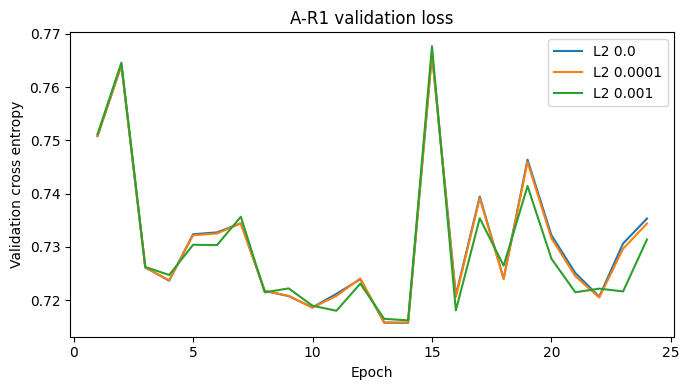

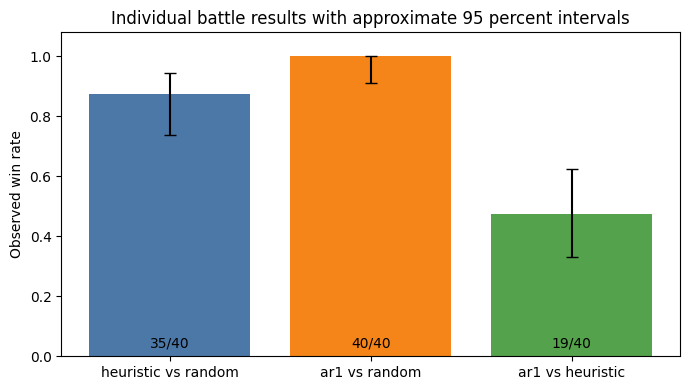

heuristic_vs_random | passed: True | wins: 35 | losses: 5 | draws: 0 | errors: 0 | policy usage: {}
ar1_vs_random | passed: True | wins: 40 | losses: 0 | draws: 0 | errors: 0 | policy usage: {'learned': 400, 'fallback': 300, 'deck': 41}
ar1_vs_heuristic | passed: True | wins: 19 | losses: 21 | draws: 0 | errors: 0 | policy usage: {'learned': 365, 'fallback': 281, 'deck': 41}


In [8]:
figures_dir = output_dir / 'figures'
figures_dir.mkdir(exist_ok=True)
if training_passed:
    with (training_dir / 'training_history.csv').open() as handle:
        history = list(csv.DictReader(handle))
    fig, ax = plt.subplots(figsize=(7, 4))
    for value in sorted({float(row['regularization']) for row in history}):
        rows = [row for row in history if float(row['regularization']) == value]
        ax.plot([int(row['epoch']) for row in rows], [float(row['validation_cross_entropy']) for row in rows],
                label='L2 ' + str(value))
    ax.set(xlabel='Epoch', ylabel='Validation cross entropy', title='A-R1 validation loss')
    ax.legend()
    fig.tight_layout()
    fig.savefig(figures_dir / 'validation_loss.png', dpi=160)
    plt.show()
if evaluation_results:
    valid = [(name, item['summary']) for name, item in evaluation_results.items()
             if item['passed'] and item['summary'].get('win_rate') is not None]
    if valid:
        labels = [name.replace('_', ' ') for name, result in valid]
        rates = [result['win_rate'] for name, result in valid]
        lower = [rate - result['win_rate_wilson_95'][0] for rate, (_, result) in zip(rates, valid)]
        upper = [result['win_rate_wilson_95'][1] - rate for rate, (_, result) in zip(rates, valid)]
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.bar(labels, rates, yerr=[lower, upper], capsize=4, color=['#4c78a8', '#f58518', '#54a24b'][:len(valid)])
        ax.set(ylim=(0, 1.08), ylabel='Observed win rate', title='Individual battle results with approximate 95 percent intervals')
        for index, (_, result) in enumerate(valid):
            ax.text(index, .03, str(result['win']) + '/' + str(result['valid_battles']), ha='center')
        fig.tight_layout()
        fig.savefig(figures_dir / 'battle_comparison.png', dpi=160)
        plt.show()
    for name, item in evaluation_results.items():
        result = item['summary']
        print(name, '| passed:', item['passed'], '| wins:', result.get('win'), '| losses:', result.get('loss'),
              '| draws:', result.get('draw'), '| errors:', result.get('error'), '| policy usage:', result.get('policy_usage'))


## 9. Build and retest the submission

Package the model after the required checks pass. Test a fresh extraction against both opponents in separate processes. A weaker agent can still be a valid experiment; packaging does not imply an improvement. No Kaggle upload happens automatically.


In [9]:
package_ready = False
(output_dir / 'submission.tar.gz').unlink(missing_ok=True)
package_manifest = {'model_id': 'A-R1', 'built': False, 'package_ready': False, 'kaggle_status': 'not_submitted'}
archive_results = {}
if evaluation_passed:
    try:
        candidate_archive = work_dir / 'ar1_candidate.tar.gz'
        expected_files = {'main.py', 'deck.csv', 'model.json'}
        with tarfile.open(candidate_archive, 'w:gz') as archive:
            for name in sorted(expected_files):
                archive.add(candidate_dir / name, arcname=name, recursive=False)
        unpacked = work_dir / 'unpacked_submission'
        unpacked.mkdir()
        with tarfile.open(candidate_archive, 'r:gz') as archive:
            members = archive.getmembers()
            assert len(members) == 3 and {member.name for member in members} == expected_files
            for member in members:
                assert member.isfile() and not member.issym() and not member.islnk()
                content = archive.extractfile(member).read()
                assert content == (candidate_dir / member.name).read_bytes()
                (unpacked / member.name).write_bytes(content)
        package_manifest.update(built=True, sha256=sha256(candidate_archive), bytes=candidate_archive.stat().st_size,
                                files={name: sha256(unpacked / name) for name in sorted(expected_files)})
        for offset, (label, opponent) in enumerate([('random', random_dir), ('heuristic', teacher_dir)]):
            passed, report, summary = run_battles('archive_vs_' + label, unpacked, opponent,
                                                 N_ARCHIVE_GAMES_PER_OPPONENT, 50000 + 100 * offset)
            archive_results[label] = {'passed': passed, 'summary': summary}
        package_ready = all(item['passed'] for item in archive_results.values())
        if package_ready:
            target = output_dir / 'submission.tar.gz'
            shutil.copy2(candidate_archive, target)
            assert sha256(target) == package_manifest['sha256']
    except Exception as error:
        package_ready = False
        (output_dir / 'submission.tar.gz').unlink(missing_ok=True)
        package_manifest['error'] = {'type': type(error).__name__, 'message': str(error), 'traceback': traceback.format_exc()}
        print('Package check failed:', str(error))
else:
    print('Packaging skipped because a required check did not pass.')
package_manifest.update(package_ready=package_ready, archive_checks=archive_results)
save_json(output_dir / 'package_manifest.json', package_manifest)
print('Package ready:', package_ready)
if package_ready:
    print('Archive:', 'submission.tar.gz', '| bytes:', package_manifest['bytes'], '| SHA 256:', package_manifest['sha256'])


archive_vs_random | passed: True | wins: 2 | losses: 0 | draws: 0 | errors: 0
archive_vs_heuristic | passed: True | wins: 1 | losses: 1 | draws: 0 | errors: 0
Package ready: True
Archive: submission.tar.gz | bytes: 20803 | SHA 256: 97971f8d74f76180fea2632b168425c7259908497573ea2622ebbae8097cb6d3


## 10. Save the run

Download the output ZIP and save the executed notebook from Colab. The ZIP includes collection records, game splits, feature definitions, fitted weights, training history, evaluation results and logs. If the package is ready, extract and upload only `submission.tar.gz` to Kaggle. Save its result separately.


In [10]:
status = {'run_id': RUN_ID, 'model_id': 'A-R1', 'collection_passed': collection_passed,
          'training_passed': training_passed, 'export_checks_passed': export_passed,
          'evaluation_passed': evaluation_passed, 'package_ready': package_ready, 'kaggle_status': 'not_submitted'}
save_json(output_dir / 'run_status.json', status)
experiment = {'run_id': RUN_ID, 'model_id': 'A-R1', 'member': 'Rishitha Gogineni',
              'feature_schema': 'ar1-visible-v1', 'training_passed': training_passed,
              'selected_l2': training_metrics.get('selected_l2'), 'selected_epoch': training_metrics.get('selected_epoch'),
              'collection_games': len(collection_report.get('battles', [])),
              'collection_records': collection_summary.get('demonstration_records'),
              'ar1_vs_random_win_rate': evaluation_results.get('ar1_vs_random', {}).get('summary', {}).get('win_rate'),
              'ar1_vs_heuristic_win_rate': evaluation_results.get('ar1_vs_heuristic', {}).get('summary', {}).get('win_rate'),
              'package_ready': package_ready, 'package_sha256': package_manifest.get('sha256'),
              'kaggle_status': 'not_submitted', 'kaggle_submission_id': '', 'kaggle_rating': ''}
with (output_dir / 'experiment_log.csv').open('w', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(experiment), lineterminator='\n')
    writer.writeheader()
    writer.writerow(experiment)
readme = ("A-R1 RUN\n\nThe model is a linear legal candidate scorer trained to imitate A-HEUR-01. "
          "Other decisions use the frozen heuristic. training/dataset_manifest.json defines whole game splits. "
          "training/feature_contract.json defines the features. Teacher scores are labels only. "
          "Collection, evaluation and archive games are separate. Reports use individual battles, not the full hosted match harness. "
          "Native engine randomness is not verified as seeded. Keep weaker results and errors. "
          "No Kaggle submission is made by this notebook. Original status files record the preupload state.\n")
(output_dir / 'README.txt').write_text(readme)
bundle = work_dir / ('AR1_' + RUN_ID + '_outputs.zip')
with zipfile.ZipFile(bundle, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(output_dir.rglob('*')):
        if path.is_file() and '__pycache__' not in path.parts and path.suffix != '.tmp':
            archive.write(path, arcname=str(path.relative_to(output_dir)))
print(json.dumps(status, indent=2))
print('Results:', bundle.name)
print('Submission archive included:', package_ready)
files.download(str(bundle))


{
  "run_id": "20261122T002608Z_bd91a79d",
  "model_id": "A-R1",
  "collection_passed": true,
  "training_passed": true,
  "export_checks_passed": true,
  "evaluation_passed": true,
  "package_ready": true,
  "kaggle_status": "not_submitted"
}
Results: AR1_20261122T002608Z_bd91a79d_outputs.zip
Submission archive included: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Next work

A-R1 training and its manual Kaggle upload are complete. All four tests from the unpacked archive passed. The saved package contains `main.py`, `model.json` and `deck.csv` and is 20,803 bytes.

The supplied screenshot does not show a submission ID, absolute observation time, rating uncertainty or the exact Kaggle team name. Those fields remain blank in the later submission record. Original Colab status outputs keep their values from before the upload.

Next, train A-R2 using the same feature definitions and game groups. Fit preprocessing on training data only. Use validation data for selection and keep the test games for the final comparison. The A-R1 results and weaker comparison against the heuristic should remain in the experiment record.
